# Does Medical Knowledge Graph Augmentation Help Biomedical Question Answering?
### A controlled study on PubMedQA with UMLS and PrimeKG

DA331 Big Data Analytics, Project 15, IIT Guwahati.

This notebook contains our complete study: the research question, every piece of implementation, all experiments,
the statistics, the diagnostics and our conclusions. It needs **only the original datasets**. Everything else (the
knowledge graphs, the retrieved facts, the model predictions, the classical-ML runs and all tables and figures) is
produced by running the cells below. Results are saved automatically in a `results/` folder.

**Workflow in five steps**

1. Open this notebook in Google Colab and choose a **T4 GPU** runtime (*Runtime > Change runtime type*).
2. Run Section 0. It installs the packages, checks the hardware and asks you to upload the dataset files.
3. Upload the files from the checklist below (or point the notebook to a Google Drive folder for the big ones).
4. Run the remaining cells in order (*Runtime > Run all* works). Long steps save checkpoints as they go.
5. At the end, download the executed notebook (*File > Download > .ipynb*) and the results ZIP produced in the last
   section.

The official PubMedQA test set (500 questions) is never used for evaluation. All results are on the 500-question
development pool.

## Dataset checklist

| # | File name (exact) | What it is | Format | Size | Where to get it | Licence |
|---|---|---|---|---|---|---|
| 1 | `ori_pqal.json` | PubMedQA PQA-L: 1,000 expert-labelled questions with abstracts | JSON | 2.6 MB | github.com/pubmedqa/pubmedqa, folder `data/` | MIT |
| 2 | `test_ground_truth.json` | official list of the 500 test questions (used only to **exclude** them) | JSON | 11 KB | same repository, `data/` | MIT |
| 3 | `kg.csv` | PrimeKG, the full graph | CSV | 0.98 GB | Harvard Dataverse, doi:10.7910/DVN/IYNGEV | CC BY 4.0 |
| 4 | `MRCONSO.RRF` | UMLS 2026AB concept names | pipe-separated text | 2.37 GB | UMLS licence needed: uts.nlm.nih.gov | UMLS licence |
| 5 | `MRREL.RRF` | UMLS 2026AB relations | pipe-separated text | 6.48 GB | same | UMLS licence |
| 6 | `MRSTY.RRF` | UMLS 2026AB semantic types | pipe-separated text | 214 MB | same | UMLS licence |
| 7 | `MRSAB.RRF` | UMLS 2026AB source list (used to pick the allowed sources) | pipe-separated text | 153 KB | same | UMLS licence |

**UMLS (files 4-7) must be supplied by you.** UMLS is licensed by the US National Library of Medicine. Anyone can
request a free licence at https://uts.nlm.nih.gov, then download the *2026AB Full Release* (or the
*Metathesaurus Full Subset*) and take the four files from its `META/` folder. Instead of the four files you can also
give the notebook the release ZIP (`umls-2026AB-metathesaurus-full.zip`, 5.6 GB); it extracts only what it needs.
Never share UMLS files or anything derived from them. This notebook keeps all UMLS-derived intermediate files in
`results/umls_private/`, prints only counts for UMLS, and leaves that folder out of the shareable results ZIP.

Without UMLS the notebook still runs: every UMLS step is skipped and clearly reported, and all PrimeKG experiments
run as normal.

**Uploading large files.** Files 1-3 are easy to upload with the upload cell below. The UMLS files (9 GB) are too large
for the browser upload widget. For them (and optionally for `kg.csv`) put the files in a Google Drive folder and set
`DRIVE_DATA_DIR` in the configuration cell; the notebook copies them from there. Files 1-3 can also be downloaded
automatically (`DOWNLOAD_PUBLIC_FILES = True`).

Pretrained models (Qwen3-4B-Instruct-2507 and Phi-4-mini-instruct) are downloaded from Hugging Face automatically.
Both are public and need no account.

## Compute requirements and run time

| Step | Hardware | Approximate time on Colab |
|---|---|---|
| Setup, dataset, PrimeKG graph | CPU | ~5 min |
| UMLS extraction with Spark (passes over 9 GB of text) | CPU | ~10-20 min |
| Facts and controls for both KGs | CPU | ~2 min |
| **LLM inference: Qwen3-4B, 5,000 prompts** | **T4 GPU** | **~45 min** |
| **LLM inference: Phi-4-mini, 5,000 prompts** | **T4 GPU** | **~50 min** |
| LLM statistics (paired bootstrap) | CPU | ~5 min |
| **Classical ML: 315 nested cross-validation fold runs** | CPU | **~1.5-2.5 h** |
| Relevance audit, retrieval strategies, prediction changes | CPU | ~10 min |
| **Total** | T4 runtime | **about 4-5 hours** |

Free Colab sessions can end before that. Every long step writes checkpoints to the results folder, so after a
disconnect you re-run the notebook and it continues where it stopped. For this to survive a disconnect, the results
folder must live on Google Drive (`USE_GOOGLE_DRIVE = True`) or you must download the results ZIP before the session
ends and upload it again (see *Resuming*, below). Disk: about 15 GB free (UMLS files plus Spark extracts). RAM: the
standard 12 GB Colab runtime is enough.

In [10]:
# Configuration: the only cell you may need to edit
from pathlib import Path

DATA_DIR = Path("/content/data")          # the uploaded dataset files are moved here
RESULTS_DIR = Path("/content/results")    # every output of the notebook goes here

USE_GOOGLE_DRIVE = True                  # True: keep data and results on Drive (survives disconnects)
DRIVE_DATA_DIR = "/content/drive/MyDrive/BioMedicalQA_with_KG/biomedqa_data"       # put big files (UMLS, kg.csv) here
DRIVE_RESULTS_DIR = "/content/drive/MyDrive/BioMedicalQA_with_KG/biomedqa_results"

DOWNLOAD_PUBLIC_FILES = False             # True: download PubMedQA and PrimeKG automatically instead of uploading

# What to run (all True reproduces the whole study)
RUN_UMLS = True                           # needs the licensed UMLS files; set False to run PrimeKG only
RUN_LLM = True                            # needs a GPU
RUN_CLASSICAL_ML = True
LLM_MODELS = ["Qwen/Qwen3-4B-Instruct-2507", "microsoft/Phi-4-mini-instruct"]

SEED = 42                                 # the seed used everywhere in the study (do not change)

In [11]:
# Install the packages that Colab does not have, and import everything we use
import subprocess, sys, shutil
# Versions used in our study. If a pinned version cannot be installed on this Colab image, the current version is
# installed instead and a warning is printed (results may then differ in the last digits).
PINNED = ["pyspark==3.5.3", "scikit-learn==1.7.2", "xgboost==3.2.0", "pyarrow", "accelerate"]
if subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + PINNED).returncode != 0:
    print("WARNING: could not install the pinned versions; installing current versions instead.")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark==3.5.3", "scikit-learn", "xgboost",
                    "pyarrow", "accelerate"], check=True)
if shutil.which("java") is None:                   # Spark needs Java (Colab normally has it)
    subprocess.run(["apt-get", "install", "-y", "-qq", "openjdk-17-jre-headless"], check=True)

import os, re, io, json, math, time, glob, shutil, random, zipfile, hashlib, platform, unicodedata, logging
from collections import Counter, defaultdict
from dataclasses import dataclass
from datetime import datetime
from itertools import combinations
from typing import Dict, List, Optional, Set, Tuple

import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})
UMLS_COLOR, PRIMEKG_COLOR, GREY = "#2a78d6", "#eb6834", "#8a8984"
KG_COLORS = {"umls": UMLS_COLOR, "primekg": PRIMEKG_COLOR}
KG_NAMES = {"umls": "UMLS", "primekg": "PrimeKG"}
LABELS = ("yes", "no", "maybe")
print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__)

python 3.13.16 | pandas 2.2.3 | numpy 2.4.6


In [12]:
# Hardware check: GPU, RAM and disk
IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
try:
    import torch
    HAS_GPU = torch.cuda.is_available()
    GPU_NAME = torch.cuda.get_device_name(0) if HAS_GPU else None
except ImportError:
    HAS_GPU, GPU_NAME = False, None
try:
    ram_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30
except (ValueError, OSError):
    ram_gb = float("nan")
disk_gb = shutil.disk_usage("/").free / 2**30
print(f"GPU: {GPU_NAME or 'none'} | RAM: {ram_gb:.1f} GB | free disk: {disk_gb:.0f} GB")
if RUN_LLM and not HAS_GPU:
    print("WARNING: no GPU found. The LLM experiments will be skipped. Switch to a T4 GPU runtime to run them.")
if RUN_UMLS and disk_gb < 15:
    print("WARNING: less than 15 GB free disk; the UMLS step may run out of space.")

GPU: Tesla T4 | RAM: 12.7 GB | free disk: 111 GB


In [13]:
# Folders: data, results (with sub-folders for every experiment), and the private UMLS folder
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = Path(DRIVE_RESULTS_DIR)

R = {name: RESULTS_DIR / name for name in
     ["dataset", "knowledge_graphs", "retrieval", "llm", "classical_ml", "diagnostics", "figures", "final_summary"]}
R["llm_raw"] = R["llm"] / "raw_predictions"
R["confusion"] = R["llm"] / "confusion_matrices"
R["ml_folds"] = R["classical_ml"] / "folds"
R["audit"] = R["diagnostics"] / "relevance_audit"
R["strategies"] = R["diagnostics"] / "retrieval_analysis"
R["transitions"] = R["diagnostics"] / "prediction_transitions"
PRIVATE = RESULTS_DIR / "umls_private"     # UMLS-derived files: never share this folder
for p in list(R.values()) + [PRIVATE, DATA_DIR]:
    p.mkdir(parents=True, exist_ok=True)
(PRIVATE / "README.txt").write_text("Files derived from the licensed UMLS. Do not share or publish.\n")
print("results folder:", RESULTS_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
results folder: /content/drive/MyDrive/BioMedicalQA_with_KG/biomedqa_results


In [14]:
# Small helpers for saving results and for safe checkpoints
def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(obj, indent=1, default=str), encoding="utf-8")


def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def save_fig(fig, name):
    fig.savefig(R["figures"] / f"{name}.png", bbox_inches="tight")


def file_fingerprint(path):
    """Size + hash of the first and last MB: enough to notice a different input file, fast on 6 GB files."""
    path = Path(path)
    h = hashlib.sha256()
    with open(path, "rb") as f:
        h.update(f.read(2**20))
        f.seek(max(0, path.stat().st_size - 2**20))
        h.update(f.read(2**20))
    return {"name": path.name, "bytes": path.stat().st_size, "sha256_head_tail": h.hexdigest()[:16]}


def checkpoint_ok(folder, settings):
    """A step's outputs can be reused only if they were made with exactly the same settings and inputs.
    Returns True if a matching checkpoint exists, False if the folder is new, and stops if the settings differ,
    so results from different settings are never mixed."""
    meta = Path(folder) / "_settings.json"
    settings = json.loads(json.dumps(settings, sort_keys=True, default=str))
    if meta.exists():
        old = load_json(meta)
        if old != settings:
            if not has_results(folder):          # nothing was computed with the old settings: just update them
                save_json(settings, meta)
                return False
            raise RuntimeError(f"{folder} holds results made with different settings or inputs.\n"
                               f"Delete or rename that folder to recompute.\nold: {old}\nnew: {settings}")
        return True
    save_json(settings, meta)
    return False


def has_results(folder):
    return any(p.is_file() and not p.name.startswith("_") for p in Path(folder).rglob("*"))


def check_parts(folder, parts):
    """Per-part settings (e.g. one entry per configuration or per KG) for a folder that can grow: parts already
    recorded must be unchanged, new parts are added. So adding UMLS later does not invalidate PrimeKG results,
    but changed facts or features for an existing part are never mixed with old results."""
    meta = Path(folder) / "_parts.json"
    parts = json.loads(json.dumps(parts, sort_keys=True, default=str))
    old = load_json(meta) if meta.exists() else {}
    changed = {k: (old[k], v) for k, v in parts.items() if k in old and old[k] != v}
    if changed:
        raise RuntimeError(f"{folder}: these parts were computed with different inputs: {sorted(changed)}.\n"
                           "Delete or rename that folder to recompute.")
    save_json({**old, **parts}, meta)


def done_flag(folder):
    return (Path(folder) / "_done").exists()


def mark_done(folder):
    (Path(folder) / "_done").write_text(datetime.now().isoformat())

### Upload the datasets

Run the next cell. It shows which files are present and which are missing, then opens the upload dialog when
something you need is missing. **You can upload in several rounds**: run the cell again for every new round (for
example PubMedQA and PrimeKG first, UMLS later). Files that are already in `DATA_DIR` are kept; a file with the same
name and the same size is never overwritten. Colab's renamed duplicates such as `kg (1).csv` are saved under the
expected name.

| What | Files | Needed for |
|---|---|---|
| Required | `ori_pqal.json`, `test_ground_truth.json`, `kg.csv` | everything |
| Optional: UMLS (licensed) | `MRCONSO.RRF`, `MRREL.RRF`, `MRSTY.RRF`, `MRSAB.RRF`, or the release ZIP `umls-2026AB-metathesaurus-full.zip` | all UMLS experiments |
| Optional: earlier results | `results.zip` (or `results_private_umls.zip`) made by the last section of this notebook | resuming after a disconnect |

To upload an optional file when nothing required is missing (for example only a `results.zip`), set
`UPLOAD_MORE_FILES = True` in the cell and run it again. The browser upload widget is not practical for the 9 GB of
UMLS files: put them (or the release ZIP) in `DRIVE_DATA_DIR` on Google Drive and set `USE_GOOGLE_DRIVE = True`
instead; the cell copies them from there.

**Resuming after a disconnect.** Upload the original datasets again and the `results.zip` you downloaded earlier.
The ZIP is unpacked into the results folder (files already there are kept), and every finished step is reused.

In [15]:
# Collect the input files: Drive copy, automatic download of public files, or upload through the browser
UPLOAD_MORE_FILES = False          # True: open the upload dialog even when nothing required is missing

PUBLIC_URLS = {   # official locations at the time of our study; if a link moved, download the file by hand
    "ori_pqal.json": "https://raw.githubusercontent.com/pubmedqa/pubmedqa/master/data/ori_pqal.json",
    "test_ground_truth.json": "https://raw.githubusercontent.com/pubmedqa/pubmedqa/master/data/test_ground_truth.json",
    "kg.csv": "https://dataverse.harvard.edu/api/access/datafile/6180620",
}
REQUIRED = ["ori_pqal.json", "test_ground_truth.json", "kg.csv"]
UMLS_FILES = ["MRCONSO.RRF", "MRREL.RRF", "MRSTY.RRF", "MRSAB.RRF"]
KNOWN = set(REQUIRED) | set(UMLS_FILES)


def accepted_name(name):
    """The expected file name for an uploaded file, or None. Colab renames duplicates as 'kg (1).csv'."""
    clean = re.sub(r"\s*\(\d+\)(?=\.[^.]+$)", "", Path(name).name)
    if clean in KNOWN:
        return clean
    if re.fullmatch(r"results(_private_umls)?\.zip", clean) or ("metathesaurus" in clean.lower() and clean.endswith(".zip")):
        return clean
    return None


def store(name, write):
    """Save one input file under its expected name; an identical file (same name and size) is never overwritten."""
    target = DATA_DIR / name
    tmp = DATA_DIR / (name + ".part")
    write(tmp)
    if target.exists() and target.stat().st_size == tmp.stat().st_size:
        tmp.unlink()
        return "already present (kept)"
    replaced = target.exists()
    tmp.replace(target)
    return "replaced (different size)" if replaced else "saved"


def umls_zips():
    return sorted(DATA_DIR.glob("*metathesaurus*.zip"))


def status():
    umls_ok = all((DATA_DIR / n).exists() for n in UMLS_FILES) or bool(umls_zips())
    return {"required_missing": [n for n in REQUIRED if not (DATA_DIR / n).exists()],
            "umls_missing": [] if umls_ok else [n for n in UMLS_FILES if not (DATA_DIR / n).exists()],
            "results_zip": [p.name for p in DATA_DIR.glob("results*.zip")]}


# 1. Google Drive (optional): copy what is there and not yet here
if USE_GOOGLE_DRIVE and Path(DRIVE_DATA_DIR).exists():
    rrf_available = all((DATA_DIR / n).exists() or (Path(DRIVE_DATA_DIR) / n).exists() for n in UMLS_FILES)
    for src in sorted(Path(DRIVE_DATA_DIR).iterdir()):
        name = accepted_name(src.name)
        if name and "metathesaurus" in name.lower() and rrf_available:
            continue                                   # the four RRF files are there: the 5.6 GB ZIP is not needed
        if name and src.is_file() and not ((DATA_DIR / name).exists() and (DATA_DIR / name).stat().st_size == src.stat().st_size):
            print(f"copying from Drive: {src.name} ({src.stat().st_size / 2**20:,.0f} MB)")
            print("  ", store(name, lambda tmp, src=src: shutil.copyfile(src, tmp)))

# 2. Automatic download of the public files (optional)
if DOWNLOAD_PUBLIC_FILES:
    for name, url in PUBLIC_URLS.items():
        if not (DATA_DIR / name).exists():
            print("downloading", name)
            subprocess.run(["wget", "-q", "-O", str(DATA_DIR / (name + ".part")), url], check=True)
            (DATA_DIR / (name + ".part")).replace(DATA_DIR / name)

# 3. Browser upload: when something needed is missing, or when you ask for it
st = status()
print("Required files missing:", st["required_missing"] or "none")
print("UMLS files missing:    ", (st["umls_missing"] or "none") if RUN_UMLS else "not needed (RUN_UMLS = False)")
print("Earlier results ZIP:   ", st["results_zip"] or "none (optional)")
want_upload = bool(st["required_missing"]) or (RUN_UMLS and bool(st["umls_missing"])) or UPLOAD_MORE_FILES
if want_upload and IN_COLAB:
    from google.colab import files
    print("\nChoose the files to upload (you can cancel and run this cell again later for another round).")
    uploaded = files.upload()
    for raw_name, content in uploaded.items():
        name = accepted_name(raw_name)
        if Path(raw_name).exists():
            Path(raw_name).unlink()                # Colab also writes the upload to the working folder
        if name is None:
            print(f"  {raw_name}: not an expected file name, ignored (expected: {sorted(KNOWN)}, results.zip or the UMLS release ZIP)")
            continue
        print(f"  {raw_name} -> {name}: {store(name, lambda tmp, c=content: tmp.write_bytes(c))}")
    del uploaded
elif want_upload:
    print(f"\nNot on Colab: copy the missing files into {DATA_DIR} and run this cell again.")

# 4. A previous results ZIP: unpack it so finished steps are reused (files already in the results folder are kept)
for z in sorted(DATA_DIR.glob("results*.zip")):
    restored = kept = 0
    with zipfile.ZipFile(z) as zf:
        for member in zf.namelist():
            rel = Path(member).relative_to("results") if member.startswith("results/") else Path(member)
            target = RESULTS_DIR / rel
            if member.endswith("/"):
                continue
            if target.exists():
                kept += 1
                continue
            target.parent.mkdir(parents=True, exist_ok=True)
            with zf.open(member) as src, open(target, "wb") as dst:
                shutil.copyfileobj(src, dst)
            restored += 1
    print(f"{z.name}: restored {restored} checkpoint files, kept {kept} files that were already in the results folder")

# 5. A UMLS release ZIP: extract only the four files we need (files already extracted are kept)
for z in umls_zips():
    with zipfile.ZipFile(z) as zf:
        for member in zf.namelist():
            name = member.split("/")[-1]
            if name in UMLS_FILES and "/META/" in member and not (DATA_DIR / name).exists():
                print("extracting", name, "from", z.name)
                with zf.open(member) as src, open(DATA_DIR / (name + ".part"), "wb") as dst:
                    shutil.copyfileobj(src, dst, 2**24)
                (DATA_DIR / (name + ".part")).replace(DATA_DIR / name)

st = status()
print("\nAfter this round -> required missing:", st["required_missing"] or "none",
      "| UMLS missing:", (st["umls_missing"] or "none") if RUN_UMLS else "not needed")

copying from Drive: kg.csv (936 MB)
   saved
copying from Drive: ori_pqal.json (2 MB)
   saved
copying from Drive: test_ground_truth.json (0 MB)
   saved
copying from Drive: umls-2026AB-metathesaurus-full.zip (5,636 MB)
   saved
Required files missing: none
UMLS files missing:     none
Earlier results ZIP:    none (optional)
extracting MRCONSO.RRF from umls-2026AB-metathesaurus-full.zip
extracting MRREL.RRF from umls-2026AB-metathesaurus-full.zip
extracting MRSAB.RRF from umls-2026AB-metathesaurus-full.zip
extracting MRSTY.RRF from umls-2026AB-metathesaurus-full.zip

After this round -> required missing: none | UMLS missing: none


In [16]:
# Check the inputs before any expensive step
EXPECTED_BYTES = {"ori_pqal.json": 2584787, "test_ground_truth.json": 11414, "kg.csv": 981751236,
                  "MRCONSO.RRF": 2373345692, "MRREL.RRF": 6484532773, "MRSTY.RRF": 214225716, "MRSAB.RRF": 152838}
problems = []
for name in REQUIRED:
    if not (DATA_DIR / name).exists():
        problems.append(f"missing required file {name}")
if not problems:
    pq = json.loads((DATA_DIR / "ori_pqal.json").read_text())
    if len(pq) != 1000 or "QUESTION" not in next(iter(pq.values())):
        problems.append("ori_pqal.json does not look like PubMedQA PQA-L (expected 1,000 items with QUESTION)")
    if len(json.loads((DATA_DIR / "test_ground_truth.json").read_text())) != 500:
        problems.append("test_ground_truth.json should list 500 test questions")
    header = (DATA_DIR / "kg.csv").open().readline().strip().split(",")
    if not {"relation", "display_relation", "x_index", "x_name", "y_index", "y_name"} <= set(header):
        problems.append(f"kg.csv header looks wrong: {header}")

HAVE_UMLS = RUN_UMLS and all((DATA_DIR / n).exists() for n in UMLS_FILES)
if RUN_UMLS and not HAVE_UMLS:
    print("UMLS files not found:", [n for n in UMLS_FILES if not (DATA_DIR / n).exists()],
          "-> all UMLS steps will be skipped (PrimeKG experiments still run).")

rows = []
for name in REQUIRED + UMLS_FILES:
    p = DATA_DIR / name
    size = p.stat().st_size if p.exists() else None
    note = "" if size is None or size == EXPECTED_BYTES[name] else "different size from the file we used"
    rows.append({"file": name, "present": p.exists(), "bytes": size, "note": note})
display(pd.DataFrame(rows))
if any(r["note"] for r in rows):
    print("NOTE: a file differs in size from ours (for example another UMLS release). The notebook still runs, but "
          "results may differ from the ones we report.")
if problems:
    raise FileNotFoundError("Fix these input problems first:\n  " + "\n  ".join(problems))
INPUTS = {name: file_fingerprint(DATA_DIR / name) for name in REQUIRED + (UMLS_FILES if HAVE_UMLS else [])}
save_json(INPUTS, R["dataset"] / "input_files.json")
print("All required inputs are present. UMLS available:", HAVE_UMLS)

,file,present,bytes,note
0,ori_pqal.json,True,2584787,
1,test_ground_truth.json,True,11414,
2,kg.csv,True,981751236,
3,MRCONSO.RRF,True,2373345692,
4,MRREL.RRF,True,6484532773,
5,MRSTY.RRF,True,214225716,
6,MRSAB.RRF,True,152838,


All required inputs are present. UMLS available: True


# 1. Introduction

**Motivation.** Small open language models are cheap to run and easy to deploy, but in medicine they often answer
from memory and can be confidently wrong. A common suggestion is to give them structured medical knowledge from a
knowledge graph (KG), such as "drug X treats disease Y". We wanted to check whether this actually helps, and whether
any improvement is real or just noise.

**Problem statement.** PubMedQA asks yes/no/maybe questions about published biomedical studies (for example "Does
telmisartan prevent hepatic fibrosis in rats with alloxan-induced diabetes?"). The answer depends on what one
particular study found. We asked whether adding facts from two biomedical KGs, UMLS and PrimeKG, to the model's input
improves its answers.

**Research question.**
> Does augmenting biomedical question answering with structured knowledge from UMLS and PrimeKG improve performance
> on PubMedQA?

**Objectives.**
1. Build a pipeline that links question words to KG concepts and retrieves short, readable KG facts.
2. Measure the effect of these facts on an LLM, with and without the study abstract, against matched *irrelevant*
   facts as a control.
3. Check whether the result holds for a second LLM and for classical ML models with KG-derived features.
4. When we found no benefit, find out *why*: is the knowledge missing, are the wrong concepts linked, is retrieval
   picking the wrong facts, or does the model not use the facts?

**Why this problem.** It is a clean test of a popular idea (KG augmentation) on a dataset with expert labels, and it
fits our course: extracting a KG from UMLS (about 9 GB of text files) is a big-data processing step we did with Spark.

**Overview.**

| Step | What | Section |
|---|---|---|
| Data | PubMedQA PQA-L; 500 development questions, test set locked | 2 |
| KGs | UMLS 2026AB (extracted with Spark) and PrimeKG (whitelisted relations) | 3, 4 |
| Pipeline | Exact-match entity linking, rule-based fact retrieval, matched irrelevant control facts | 5, 6 |
| LLM study | Qwen3-4B-Instruct and Phi-4-mini, six input conditions | 7, 8 |
| Classical ML | TF-IDF + KG features, three classifiers, repeated cross-validation | 9 |
| Why no gain? | Relevance audit, retrieval-strategy analysis, prediction-change analysis | 11-13 |
| Fine-tuning | Feasibility assessment (not run) | 14 |
| Wrap-up | Discussion, limitations, conclusion, results export | 15-18 |

# 2. Dataset: PubMedQA

We used **PQA-L**, the expert-labelled part of PubMedQA: 1,000 questions, each built from a PubMed article.
Each item has:

- **question**: usually the article title rephrased as a question;
- **context**: the abstract *without* its conclusion;
- **long answer**: the abstract's conclusion. It contains the answer, so we never give it to any model;
- **final decision**: the label, `yes`, `no` or `maybe`.

The official split puts 500 questions in a test set. We kept the test set **locked** for the whole project and only
used the other 500 questions, which we call the **development pool** (Dev-500). Inside it we first drew **Dev-100**
(100 questions, stratified by label, seed 42) to develop and debug the pipeline; the other 400 are **Dev-400**. All
reported results are on the full development pool.

In [17]:
# PubMedQA loading and the deterministic splits
@dataclass(frozen=True)
class Example:
    pmid: str
    question: str
    abstract: str      # abstract WITHOUT its conclusion: the only evidence a model may see
    label: str         # gold answer: yes / no / maybe
    long_answer: str   # the conclusion: analysis only, never put into a prompt or a feature


def load_examples(path=DATA_DIR / "ori_pqal.json"):
    raw = json.loads(Path(path).read_text(encoding="utf-8"))
    examples = {}
    for pmid, rec in raw.items():
        if rec["final_decision"] not in LABELS:
            raise ValueError(f"PMID {pmid}: unexpected label")
        examples[pmid] = Example(pmid, rec["QUESTION"].strip(), " ".join(rec["CONTEXTS"]).strip(),
                                 rec["final_decision"], rec.get("LONG_ANSWER", ""))
    return examples


def load_test_pmids(examples, path=DATA_DIR / "test_ground_truth.json"):
    """The official test PMIDs. We only need the IDs, to keep these questions out."""
    truth = json.loads(Path(path).read_text(encoding="utf-8"))
    if set(truth) - set(examples):
        raise ValueError("test PMIDs missing from ori_pqal.json")
    return set(truth)


def stratified_sample(examples, pmids, n, seed):
    """Draw n PMIDs keeping the yes/no/maybe proportions (so Dev-100 has about 11 maybes)."""
    rng = random.Random(seed)
    by_label = {lab: sorted(p for p in pmids if examples[p].label == lab) for lab in LABELS}
    quotas = {lab: round(n * len(v) / len(pmids)) for lab, v in by_label.items()}
    quotas["maybe"] = n - quotas["yes"] - quotas["no"]
    chosen = set()
    for lab in LABELS:
        chosen |= set(rng.sample(by_label[lab], quotas[lab]))
    return chosen


def label_counts(items):
    c = Counter(e.label for e in items)
    return {lab: c.get(lab, 0) for lab in LABELS}


examples = load_examples()
test_pmids = load_test_pmids(examples)
non_test = set(examples) - test_pmids
dev100_ids = stratified_sample(examples, non_test, 100, SEED)
splits = {"dev_pool": [examples[p] for p in sorted(non_test)],
          "dev_100": [examples[p] for p in sorted(dev100_ids)],
          "dev_400": [examples[p] for p in sorted(non_test - dev100_ids)]}
dev_pool = splits["dev_pool"]
split_of = {e.pmid: ("dev_100" if e.pmid in dev100_ids else "dev_400") for e in dev_pool}

assert not {e.pmid for e in dev_pool} & test_pmids, "a test question entered the development pool"
print("PQA-L questions:", len(examples))
print(f"  official test set: {len(test_pmids)} questions (locked: never evaluated, labels never used)")
for name, items in splits.items():
    print(f"  {name:9s} {len(items):4d} questions  labels {label_counts(items)}")

pd.DataFrame({"pmid": [e.pmid for e in dev_pool], "split": [split_of[e.pmid] for e in dev_pool]}).to_csv(
    R["dataset"] / "development_splits.csv", index=False)
words = [len(e.abstract.split()) for e in dev_pool]
save_json({"pqal_questions": len(examples), "test_questions_locked": len(test_pmids),
           "dev_pool": label_counts(dev_pool), "dev_100": label_counts(splits["dev_100"]),
           "dev_400": label_counts(splits["dev_400"]), "abstract_words_mean": round(float(np.mean(words)), 1),
           "abstract_words_max": int(max(words)), "seed": SEED}, R["dataset"] / "dataset_summary.json")

PQA-L questions: 1000
  official test set: 500 questions (locked: never evaluated, labels never used)
  dev_pool   500 questions  labels {'yes': 276, 'no': 169, 'maybe': 55}
  dev_100    100 questions  labels {'yes': 55, 'no': 34, 'maybe': 11}
  dev_400    400 questions  labels {'yes': 221, 'no': 135, 'maybe': 44}


PMID: 10411439 | label: yes
Question: Lloyd-Davies position with Trendelenburg--a disaster waiting to happen?
Abstract (conclusion removed), first 300 characters: Lower limb compartment syndrome has been reported to occur after colorectal, urological, and gynecological procedures during which the patient's lower limbs are elevated for prolonged periods of time. We investigated lower limb perfusion in a group of patients undergoing prolonged pelvic surgery bot ...
Abstract length in the development pool: mean 198 words, max 398


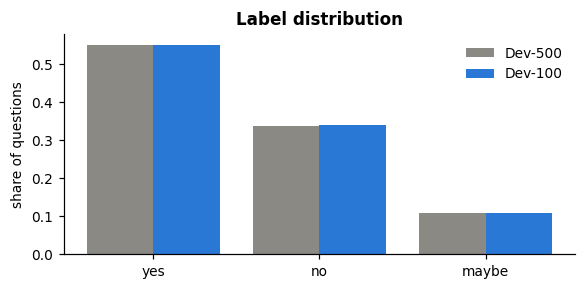

Always answering 'yes' gives accuracy 0.552 on the development pool.


In [18]:
# One example, and what a model is (and is not) allowed to see
e = splits["dev_100"][0]
print("PMID:", e.pmid, "| label:", e.label)
print("Question:", e.question)
print("Abstract (conclusion removed), first 300 characters:", e.abstract[:300], "...")
print(f"Abstract length in the development pool: mean {np.mean(words):.0f} words, max {max(words)}")

pool_counts, d100_counts = label_counts(dev_pool), label_counts(splits["dev_100"])
fig, ax = plt.subplots(figsize=(6, 2.6))
x = np.arange(3)
ax.bar(x - 0.2, [pool_counts[l] / 500 for l in LABELS], 0.4, label="Dev-500", color=GREY)
ax.bar(x + 0.2, [d100_counts[l] / 100 for l in LABELS], 0.4, label="Dev-100", color=UMLS_COLOR)
ax.set_xticks(x, LABELS); ax.set_ylabel("share of questions"); ax.set_title("Label distribution")
ax.legend(frameon=False)
save_fig(fig, "label_distribution"); plt.show()
print("Always answering 'yes' gives accuracy", pool_counts["yes"] / 500, "on the development pool.")

**What we observe.** The labels are unbalanced: 55% yes, 34% no and only 11% maybe. A model that always says "yes"
already gets 55% accuracy, so accuracy alone can look good while the model ignores "no" and "maybe". This is why we
also report **macro-F1** (Section 10).

# 3. Knowledge graphs: UMLS and PrimeKG

| | **UMLS 2026AB** (Unified Medical Language System) | **PrimeKG** (Precision Medicine KG, Harvard) |
|---|---|---|
| What it is | A very large thesaurus that merges about 200 medical vocabularies into millions of concepts, each with many synonyms, plus relations between concepts | A graph built for precision medicine from about 20 curated sources; about 129k nodes; `kg.csv` has about 8.1 million rows (each relation stored in both directions) |
| Strength for us | Very good **synonym coverage** (e.g. "stroke" = "cerebrovascular accident") | Clean, typed **drug-disease, disease-phenotype and gene-disease** edges |
| Relations we used | 11 types from MED-RT, OMIM and NCI (treat, prevent, contraindication, diagnose, induce, manifestation, findings, associated gene, associated disease) | 12 types: indication, contraindication, off-label use, side effect, phenotype present/absent, linked to (exposure), associated with (gene), target, enzyme, transporter, carrier |
| Licence | UMLS licence; we used only the current English sources with restriction level 0, and nothing UMLS-derived is shared | CC BY 4.0 (can be shared with attribution) |

**Why both.** UMLS should find more concepts (thanks to synonyms), PrimeKG should give cleaner relations. Using both
tells us whether the result depends on the choice of KG.

**Limitations for our problem (which we only fully understood later, Sections 11-12).** Both graphs store general
facts about drugs, diseases, phenotypes and genes. PubMedQA questions are about *what one study found*, often about
procedures, measurements, exposures or social factors. A curated graph rarely contains a fact that answers such a
question.

We also looked at **OptimusKG**, which the PrimeKG authors describe as its successor, but we could not download its
files with our tools and its data comes with mixed licences, so we did not use it.

# 4. Knowledge graph construction

## 4.1 PrimeKG

`kg.csv` has 8.1 million rows. We read it in chunks of one million rows and kept only the relation types in our
whitelist below. PrimeKG stores every relation in both directions, so for each type we kept one direction (the one whose
first node has the listed subject type, e.g. drug -> disease for "indication") and dropped duplicates. Each relation
type also gets an English sentence template and a **priority** (1 = most clinically useful), which retrieval uses
later.

In [19]:
# PrimeKG whitelist: (relation, display_relation) -> (subject type, priority, sentence template)
FACT_SPECS = {
    ("indication", "indication"): ("drug", 1, "{s} is indicated for {o}."),
    ("contraindication", "contraindication"): ("drug", 1, "{s} is contraindicated in {o}."),
    ("off-label use", "off-label use"): ("drug", 1, "{s} is used off-label for {o}."),
    ("drug_effect", "side effect"): ("drug", 2, "{s} may cause {o} as a side effect."),
    ("disease_phenotype_positive", "phenotype present"): ("disease", 3, "{s} is associated with the phenotype {o}."),
    ("disease_phenotype_negative", "phenotype absent"): ("disease", 3, "{s} does not typically present with {o}."),
    ("exposure_disease", "linked to"): ("exposure", 3, "{s} is linked to {o}."),
    ("disease_protein", "associated with"): ("disease", 4, "{s} is associated with the gene/protein {o}."),
    ("drug_protein", "target"): ("drug", 4, "{s} targets {o}."),
    ("drug_protein", "enzyme"): ("drug", 5, "{s} is metabolized by the enzyme {o}."),
    ("drug_protein", "transporter"): ("drug", 5, "{s} is transported by {o}."),
    ("drug_protein", "carrier"): ("drug", 5, "{s} is carried by {o}."),
    ("phenotype_protein", "associated with"): ("effect/phenotype", 5, "{s} is associated with {o}."),
}
EDGE_COLUMNS = ["relation", "display_relation", "s_index", "s_name", "s_type", "o_index", "o_name", "o_type"]
SPEC_TABLE = pd.DataFrame([(r, d, s) for (r, d), (s, _p, _t) in FACT_SPECS.items()],
                          columns=["relation", "display_relation", "subject_type"])


def filter_edges(chunk):
    """Keep whitelisted relations in their subject -> object direction; rename x/y to s/o."""
    merged = chunk.merge(SPEC_TABLE, on=["relation", "display_relation"], how="inner")
    merged = merged[merged["x_type"] == merged["subject_type"]]
    out = merged.rename(columns={"x_index": "s_index", "x_name": "s_name", "x_type": "s_type",
                                 "y_index": "o_index", "y_name": "o_name", "y_type": "o_type"})
    out = out[EDGE_COLUMNS].copy()
    out["s_index"] = out["s_index"].astype("int64")
    out["o_index"] = out["o_index"].astype("int64")
    return out


def load_whitelist_edges(path, chunksize=1_000_000):
    parts, rows = [], 0
    for chunk in pd.read_csv(path, usecols=["relation", "display_relation", "x_index", "x_type", "x_name",
                                            "y_index", "y_type", "y_name"], dtype=str, chunksize=chunksize):
        rows += len(chunk)
        parts.append(filter_edges(chunk))
    edges = pd.concat(parts, ignore_index=True)
    edges = edges.drop_duplicates(["relation", "display_relation", "s_index", "o_index"]).reset_index(drop=True)
    return edges, rows


def node_table(edges):
    """Unique nodes that have at least one whitelisted edge: columns index, name, type."""
    s = edges[["s_index", "s_name", "s_type"]].set_axis(["index", "name", "type"], axis=1)
    o = edges[["o_index", "o_name", "o_type"]].set_axis(["index", "name", "type"], axis=1)
    return pd.concat([s, o]).drop_duplicates("index").sort_values("index").reset_index(drop=True)


kg_dir = R["knowledge_graphs"] / "primekg"
edges_file = kg_dir / "primekg_whitelist_edges.parquet"
if checkpoint_ok(kg_dir, {"input": INPUTS["kg.csv"], "whitelist": sorted(map(str, FACT_SPECS))}) and edges_file.exists():
    primekg_edges = pd.read_parquet(edges_file)
    print("reused the PrimeKG graph built earlier")
else:
    t0 = time.time()
    primekg_edges, n_rows = load_whitelist_edges(DATA_DIR / "kg.csv")
    primekg_edges.to_parquet(edges_file, index=False)
    save_json({"kg_csv_rows": n_rows, "whitelisted_edges": len(primekg_edges),
               "nodes": int(len(node_table(primekg_edges))),
               "edges_by_relation": primekg_edges["display_relation"].value_counts().to_dict()},
              R["knowledge_graphs"] / "primekg_summary.json")
    print(f"read {n_rows:,} rows in {time.time() - t0:.0f}s")
print(f"PrimeKG whitelisted edges: {len(primekg_edges):,}  nodes: {len(node_table(primekg_edges)):,}")
print(primekg_edges["display_relation"].value_counts().to_string())

reused the PrimeKG graph built earlier
PrimeKG whitelisted edges: 370,623  nodes: 35,661
display_relation
phenotype present    150317
associated with       83741
side effect           64784
contraindication      30675
target                16380
indication             9388
enzyme                 5317
transporter            3092
off-label use          2568
linked to              2304
phenotype absent       1193
carrier                 864


## 4.2 UMLS with Spark

UMLS is distributed as large pipe-separated text files: MRCONSO (concept names, 2.4 GB), MRREL (relations, 6.5 GB)
and MRSTY (semantic types). They are too big to load into memory, so we wrote a small **PySpark** job:

1. Split each file into line-aligned **byte ranges** of 128 MB.
2. Each Spark task seeks to its own range, streams it line by line and keeps only matching rows:
   - **MRCONSO:** English, non-suppressed names from an allowed source whose *normalised* text equals a word n-gram
     (1-6 words) from our text;
   - **MRSTY:** the semantic types of the matched concepts;
   - **MRREL:** relations of the 11 whitelisted types (relation class RO, CHD or PAR, allowed source, not
     suppressed) that touch a matched concept;
   - **NAMES / NSTY:** a second pass over MRCONSO / MRSTY for the names and types of the new neighbour concepts.
3. Each finished range is saved as a small Parquet file, so the job is **resumable**: if Colab stops, re-running
   the cell skips the finished ranges.

"Allowed sources" are the current English sources with licence restriction level 0 in MRSAB (53 sources).

We built two UMLS graphs, scoped to different text:

| Graph | Concepts matched from | Used for |
|---|---|---|
| question-scoped graph | the 500 development questions | the LLM experiments (Sections 7-8) |
| question+abstract-scoped graph | the development questions **and their abstracts** | classical-ML features (Section 9) and the retrieval-strategy analysis (Section 12) |

Because the question n-grams are a subset of the question+abstract n-grams, we run each Spark pass **once** with the
larger candidate set (plus the concept-lookup terms of the relevance audit, Section 11) and then select
the rows of each graph. The row filters are exactly the same as running the
graphs separately; we checked that this gives identical graphs to the ones from our experiments.

In [20]:
# UMLS extraction helpers: normalisation (shared with the entity linker), n-gram candidates, allowed sources
TOKEN = re.compile(r"[A-Za-z0-9][A-Za-z0-9\-'’]*")
MAX_NGRAM = 6
STOPWORDS = frozenset("the of and in on for with to a an is are does do can be by or after before during than "
                      "versus vs as at from".split())
GENERIC_NAMES = frozenset({"disease", "syndrome", "disorder", "disorders", "condition", "injury"})
SPELLING = [("oesophag", "esophag"), ("haemo", "hemo"), ("haem", "hem"), ("aemia", "emia"), ("aemi", "emi"),
            ("oedema", "edema"), ("diarrhoea", "diarrhea"), ("foet", "fet"), ("paed", "ped"), ("anaesth", "anesth"),
            ("tumour", "tumor"), ("ischaemi", "ischemi"), ("oestr", "estr"), ("gynaecol", "gynecol"),
            ("caesarean", "cesarean"), ("behaviour", "behavior"), ("centre", "center"), ("labour", "labor"),
            ("faec", "fec"), ("leukaem", "leukem")]


def normalize(text):
    """Lower case, drop possessive 's, punctuation -> space, British -> American spelling."""
    s = unicodedata.normalize("NFKC", str(text)).lower()
    s = re.sub(r"['’]s\b", "", s)
    s = re.sub(r"[^a-z0-9]+", " ", s).strip()
    for old, new in SPELLING:
        s = s.replace(old, new)
    return re.sub(r"\s+", " ", s)


def candidate_strings(texts):
    """Every normalised 1..6-gram of every text, plus the trailing-'s'-stripped form the linker also tries."""
    out = set()
    for q in texts:
        norm = [normalize(t) for t in TOKEN.findall(q)]
        for n in range(1, MAX_NGRAM + 1):
            for i in range(len(norm) - n + 1):
                span = " ".join(w for w in norm[i:i + n] if w)
                if not span or all(w in STOPWORDS for w in span.split()):
                    continue
                out.add(span)
                if span.endswith("s") and len(span) > 4:
                    out.add(span[:-1])
    return {s for s in out if len(s) >= 3 and s not in GENERIC_NAMES}


def allowed_sources(mrsab_path):
    cols = ["VCUI", "RCUI", "VSAB", "RSAB", "SON", "SF", "SVER", "VSTART", "VEND", "IMETA", "RMETA", "SLC", "SCC",
            "SRL", "TFR", "CFR", "CXTY", "TTYL", "ATNL", "LAT", "CENC", "CURVER", "SABIN", "SSN", "SCIT", "_"]
    df = pd.read_csv(mrsab_path, sep="|", header=None, names=cols, dtype=str, quoting=3)
    df = df[(df["CURVER"] == "Y") & (df["LAT"] == "ENG") & (df["SRL"].astype(int) <= 0)]
    return set(df["RSAB"])


# The 11 whitelisted UMLS relations: rela -> (priority, sentence template, source)
UMLS_SPECS = {
    "may_treat": (1, "{s} may treat {o}.", "MED-RT"),
    "contraindicated_with_disease": (1, "{s} is contraindicated in {o}.", "MED-RT"),
    "may_prevent": (1, "{s} may prevent {o}.", "MED-RT"),
    "may_diagnose": (2, "{s} may be used to diagnose {o}.", "MED-RT"),
    "induces": (2, "{s} may induce {o}.", "MED-RT"),
    "has_manifestation": (3, "{s} has the manifestation {o}.", "OMIM"),
    "disease_has_finding": (3, "{s} has the finding {o}.", "NCI"),
    "disease_may_have_finding": (3, "{s} may present with {o}.", "NCI"),
    "disease_excludes_finding": (3, "{s} typically does not present with {o}.", "NCI"),
    "disease_has_associated_gene": (4, "{s} is associated with the gene {o}.", "NCI"),
    "disease_may_have_associated_disease": (4, "{s} may be associated with {o}.", "NCI"),
}
KEEP_REL = {"RO", "CHD", "PAR"}
MAX_STR_CHARS = 120       # candidate strings are at most 6 words; longer UMLS names can never match
RANGE_BYTES = 128 * 2**20

In [21]:
# The Spark job: byte ranges, per-table row filters, resumable passes
def byte_ranges(path, size=RANGE_BYTES):
    n = os.path.getsize(path)
    return [(i, s, min(s + size, n)) for i, s in enumerate(range(0, n, size))]


def read_range(path, start, end):
    """Yield the lines that START inside [start, end). Every line belongs to exactly one range."""
    with open(path, "rb") as f:
        if start > 0:
            f.seek(start - 1)
            f.readline()
        while f.tell() < end:
            line = f.readline()
            if not line:
                break
            yield line.decode("utf-8", errors="replace").rstrip("\n").rstrip("\r")


def conso_rows(lines, ctx):
    cands, sabs = ctx["cands"], ctx["sabs"]
    for ln in lines:
        p = ln.split("|")
        if p[1] != "ENG" or p[16] != "N" or p[11] not in sabs or len(p[14]) > MAX_STR_CHARS:
            continue
        n = normalize(p[14])
        if n in cands:
            yield (p[0], p[2], p[6], p[11], p[12], p[14], n)


def names_rows(lines, ctx):
    cuis, sabs = ctx["cuis"], ctx["sabs"]
    for ln in lines:
        if ln[:8] not in cuis:
            continue
        p = ln.split("|")
        if p[1] == "ENG" and p[16] == "N" and p[11] in sabs:
            yield (p[0], p[2], p[4], p[6], p[11], p[12], p[14])


def sty_rows(lines, ctx):
    cuis = ctx["cuis"]
    for ln in lines:
        if ln[:8] in cuis:
            p = ln.split("|")
            yield (p[0], p[1], p[3])


def rel_rows(lines, ctx):
    cuis, sabs, relas = ctx["cuis"], ctx["sabs"], ctx["relas"]
    for ln in lines:
        p = ln.split("|", 15)
        c1, c2 = p[0], p[4]
        if (c1 in cuis or c2 in cuis) and c1 != c2 and p[3] in KEEP_REL and p[10] in sabs and p[14] != "Y" \
                and p[7] in relas:
            yield (c1, p[3], c2, p[7], p[10])


SCHEMA = {"MRCONSO": (conso_rows, ["cui", "ts", "ispref", "sab", "tty", "str", "nstr"], "MRCONSO.RRF"),
          "NAMES": (names_rows, ["cui", "ts", "stt", "ispref", "sab", "tty", "str"], "MRCONSO.RRF"),
          "MRSTY": (sty_rows, ["cui", "tui", "sty"], "MRSTY.RRF"),
          "NSTY": (sty_rows, ["cui", "tui", "sty"], "MRSTY.RRF"),
          "MRREL": (rel_rows, ["cui1", "rel", "cui2", "rela", "sab"], "MRREL.RRF")}


def get_spark():
    from pyspark.sql import SparkSession
    os.environ["PYSPARK_PYTHON"] = sys.executable
    os.environ.pop("JAVA_TOOL_OPTIONS", None)
    os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
    return (SparkSession.builder.master("local[2]").appName("umls_extract")
            .config("spark.driver.memory", "2g").config("spark.ui.enabled", "false")
            .config("spark.driver.host", "127.0.0.1").config("spark.driver.bindAddress", "127.0.0.1")
            .config("spark.python.worker.reuse", "true").getOrCreate())


def run_pass(table, ctx, out_dir, budget_s=None, per_job=2):
    """Run one pass over a UMLS file; every finished 128 MB range is saved, so a stopped pass resumes."""
    fn, cols, fname = SCHEMA[table]
    path = str(DATA_DIR / fname)
    tdir = Path(out_dir) / table
    tdir.mkdir(parents=True, exist_ok=True)
    ranges = byte_ranges(path)
    todo = [r for r in ranges if not (tdir / f"range_{r[0]:04d}.parquet").exists()]
    if not todo:
        return
    spark = get_spark()
    sc = spark.sparkContext
    bctx = sc.broadcast(ctx)
    t0 = time.time()
    while todo and (budget_s is None or time.time() - t0 < budget_s):
        batch, todo = todo[:per_job], todo[per_job:]
        res = (sc.parallelize(batch, len(batch))
               .mapPartitions(lambda it: [(rid, list(fn(read_range(path, s, e), bctx.value))) for rid, s, e in it])
               .collect())
        for rid, rows in res:
            pd.DataFrame(rows, columns=cols).to_parquet(tdir / f"range_{rid:04d}.parquet", index=False)
        done = len(ranges) - len(todo)
        print(f"  {table}: {done}/{len(ranges)} ranges ({time.time() - t0:.0f}s)", flush=True)
    spark.stop()


def load_pass(out_dir, table):
    parts = sorted(glob.glob(str(Path(out_dir) / table / "range_*.parquet")))
    return pd.concat([pd.read_parquet(p) for p in parts], ignore_index=True) if parts else pd.DataFrame()


def pass_complete(out_dir, table):
    n = len(byte_ranges(str(DATA_DIR / SCHEMA[table][2])))
    return len(glob.glob(str(Path(out_dir) / table / "range_*.parquet"))) == n

In [22]:
# Research data of the preliminary relevance audit (Section 11): AI annotations, key concepts and lookup terms.
# It contains no UMLS text (UMLS facts are referenced by a short hash only). It is loaded here because the
# concept lookup terms are matched in the same UMLS pass as the question and abstract strings.
AUDIT_DATA = json.loads(r"""{"facts_csv":"item_id,fact_sha,link_correct,fact_correct,category,subtype,justification_primekg_only\n10757151-umls-0,357ce8dcaf,correct,correct,2,2b,\n10757151-umls-1,1b6cfffe61,correct,correct,2,2b,\n10757151-umls-2,15b04f307b,correct,correct,2,2b,\n10757151-umls-3,a14a54aaea,correct,correct,2,2b,\n11247896-primekg-0,ae334fb374,correct,correct,3,,Gene-disease link FAP-APC is stated throughout the abstract; adds nothing about therapeutic decisions.\n11247896-primekg-1,9e8b5f4339,correct,unsure,2,2b,Generic gene association of APC with an unrelated condition.\n11247896-primekg-2,29d9f76b4e,correct,correct,2,2b,Extracolonic dental phenotype of FAP; not about mutation-guided therapy.\n11247896-primekg-3,7090c7ac42,correct,correct,2,2b,APC in adenocarcinoma generally; not about therapeutic decisions.\n11247896-primekg-4,62e994f00b,correct,correct,2,2b,Extracolonic tumour association (Turcot); not about mutation-guided therapy.\n11247896-primekg-5,849ec107dd,correct,unsure,2,2b,Generic gene association; not about mutation analysis or therapy.\n11247896-primekg-6,c92604dad6,correct,unsure,2,2b,Generic gene association; not about mutation analysis or therapy.\n11247896-umls-0,c3787f0899,incorrect,correct,4,,\n11247896-umls-1,1026a26c45,correct,correct,2,2a,\n11247896-umls-2,8dc8288d90,incorrect,correct,4,,\n11247896-umls-3,f205d9a71f,correct,correct,3,,\n11247896-umls-4,44128fc8a5,incorrect,correct,4,,\n11247896-umls-5,e60ceeeceb,correct,correct,3,,\n11247896-umls-6,576dc88170,incorrect,correct,4,,\n11247896-umls-7,c7b7ababd8,correct,correct,3,,\n11413427-primekg-0,9f4a84839a,correct,correct,3,,Abnormal spinal curvature is implied by the concept name.\n11413427-primekg-1,7bec826927,correct,correct,2,2b,Phenotype annotation; unrelated to apex/rotation question.\n11413427-primekg-2,53efe47563,correct,unsure,2,2b,Gene association; irrelevant to apex/rotation question.\n11413427-primekg-3,70d061cd28,correct,unsure,2,2b,Gene association; irrelevant to apex/rotation question.\n11413427-umls-0,c13da0cd76,correct,correct,2,2b,\n11413427-umls-1,972c76c8a2,correct,correct,2,2b,\n11838307-umls-0,a7552a3ecf,incorrect,correct,4,,\n11838307-umls-1,f5b5cc9d90,incorrect,correct,4,,\n11838307-umls-2,a4a2cd1503,incorrect,correct,4,,\n11882828-primekg-0,4e38c31d88,correct,correct,2,2b,Safety contraindication; does not address the question.\n11882828-primekg-1,c4be947b01,correct,incorrect,5,,Anxiety disorder is not a recognised contraindication of tranexamic acid; likely a data artefact.\n11882828-primekg-2,5d527929a4,correct,misleading,5,,\"Tranexamic acid treats heavy menstrual bleeding, not endometriosis itself; misleading indication.\"\n11882828-primekg-3,7527a31510,correct,misleading,5,,As previous; misleading indication.\n11882828-umls-0,2c899ce435,correct,correct,2,2b,\n11882828-umls-1,ecd5d82aed,correct,correct,2,2b,\n11882828-umls-2,9b6afca87e,correct,correct,2,2a,\n11882828-umls-3,b13ef687b4,correct,correct,2,2a,\n12607120-primekg-0,35d2dbef07,partial,correct,2,2b,Generic cancer contraindication.\n12607120-primekg-1,ddfd08dcd4,partial,correct,2,2b,Generic cancer contraindication.\n12607120-primekg-2,d5d5cfc677,partial,correct,2,2b,Generic oncology drug indication.\n12607120-primekg-3,0ebb347c0f,partial,correct,2,2b,Generic oncology drug indication.\n12607120-umls-0,c7a4bd0d45,partial,correct,2,2b,\n12607120-umls-1,b1230c8c93,partial,correct,2,2b,\n12607120-umls-2,7ea3404037,partial,correct,3,,\n12607120-umls-3,b843a6505d,partial,correct,3,,\n15475728-primekg-0,a5e76cefbb,correct,correct,2,2b,Unrelated drug contraindication.\n15475728-primekg-1,de91ee66cb,correct,incorrect,5,,MI is not a recognised contraindication of acyclovir; likely a data artefact.\n15475728-primekg-2,72b6a893fe,correct,correct,2,2a,\"Aspirin and MI; related outcome topic, not alcohol timing.\"\n15475728-primekg-3,92aa173d5d,correct,correct,2,2b,Acute thrombolytic treatment; unrelated to MI risk from drinking pattern.\n15475728-umls-0,c5771cfd86,correct,correct,2,2b,\n15475728-umls-1,8f69af91c8,correct,correct,2,2b,\n15475728-umls-2,f28b1f3609,correct,correct,2,2b,\n15475728-umls-3,fe0dd908ab,correct,unsure,2,2b,\n15475728-umls-4,07ef5d2b95,correct,correct,2,2a,\n15475728-umls-5,72290ef1e4,correct,correct,2,2a,\n15477551-primekg-0,31eae079a8,correct,correct,2,2b,'Progressive' is a course modifier; fact links it to an arbitrary metabolic syndrome.\n15477551-primekg-1,ee51445572,correct,correct,2,2b,Other cause of cervical myelopathy; not HTLV-I related.\n15477551-primekg-2,ba6bc82c3a,correct,correct,2,2b,Course modifier attached to an arbitrary syndrome.\n15477551-primekg-3,da262e72f0,correct,correct,2,2b,Other cause of cervical myelopathy.\n15477551-umls-0,294895452d,correct,correct,2,2b,\n15477551-umls-1,9c930b2cfe,partial,correct,2,2b,\n15477551-umls-2,cb05303b12,correct,correct,2,2b,\n15477551-umls-3,e07823c306,partial,correct,2,2b,\n15477551-umls-4,81eb3f3a39,partial,correct,2,2b,\n15477551-umls-5,6f2f4c3364,partial,correct,2,2b,\n15703931-primekg-0,22a64192ab,correct,incorrect,5,,Cholecalciferol is not contraindicated in cervical cancer; likely artefact.\n15703931-primekg-1,24ba3cb6ea,correct,correct,2,2b,Hormonal contraceptive contraindication; unrelated to PET diagnosis.\n15703931-primekg-2,dad3e1a1c0,correct,correct,2,2b,Treatment indication; question is about diagnostic imaging.\n15703931-primekg-3,f998ce6e9a,correct,correct,2,2b,Treatment indication; unrelated to diagnosis.\n15703931-umls-0,bd345c6a9a,correct,correct,2,2b,\n15703931-umls-1,dc0cb1a999,correct,incorrect,5,,\n15703931-umls-2,fe6ab16472,correct,correct,2,2b,\n15703931-umls-3,d199097a54,correct,incorrect,5,,\n15703931-umls-4,07ab849a7e,correct,unsure,2,2b,\n15703931-umls-5,2bd3c8e21d,correct,correct,3,,\n15703931-umls-6,feffe5a2ab,correct,correct,2,2b,\n15703931-umls-7,b666653ef6,correct,correct,3,,\n17179167-primekg-0,20fd3634bd,correct,unsure,2,2b,Gene association (likely from the webbing sense); nothing about HPV.\n17179167-primekg-1,9abb028bdc,correct,unsure,2,2b,Gene association; nothing about HPV as a risk factor.\n17179167-umls-0,d2baaeef74,unsure,misleading,5,,\n17179167-umls-1,335aacc068,unsure,misleading,5,,\n17244100-primekg-0,35d2dbef07,correct,correct,2,2b,Generic cancer contraindication.\n17244100-primekg-1,e8649be4eb,correct,correct,2,2b,Drug side effect of pain; unrelated.\n17244100-primekg-2,ddfd08dcd4,correct,correct,2,2b,Generic cancer contraindication.\n17244100-primekg-3,20b06559bd,correct,correct,2,2b,Drug side effect of pain; unrelated.\n17244100-primekg-4,d5d5cfc677,correct,correct,2,2b,Generic oncology indication.\n17244100-primekg-5,d067b514bd,correct,unsure,2,2b,Painless rare skin lesion; unrelated.\n17244100-primekg-6,0ebb347c0f,correct,correct,2,2b,Generic oncology indication.\n17244100-primekg-7,65966b6bec,correct,correct,2,2b,Painless rare carcinoma; unrelated.\n17244100-umls-0,c7a4bd0d45,correct,correct,2,2b,\n17244100-umls-1,88f682df41,correct,correct,2,2a,\n17244100-umls-2,b1230c8c93,correct,correct,2,2b,\n17244100-umls-3,24c9b7138e,correct,correct,2,2a,\n17244100-umls-4,7ea3404037,correct,correct,3,,\n17244100-umls-5,14dbe28191,correct,correct,2,2a,\n17244100-umls-6,b843a6505d,correct,correct,3,,\n17244100-umls-7,3e040c6041,correct,correct,2,2a,\n17489316-primekg-0,a9ff2f8611,partial,correct,2,2b,'carcinoma' instead of renal cell carcinoma; unrelated contraindication.\n17489316-primekg-1,13f870ec91,partial,unsure,2,2b,Unrelated anaesthetic caution.\n17489316-primekg-2,33b7fab50a,partial,correct,2,2b,Basal cell carcinoma drug under a generic carcinoma node; unrelated.\n17489316-primekg-3,edb2bde679,partial,correct,2,2b,Basal cell carcinoma drug under a generic node; unrelated.\n17489316-umls-0,079def1336,partial,unsure,2,2b,\n17489316-umls-1,4919027120,correct,correct,2,2b,\n17489316-umls-2,c066fd1e9c,partial,unsure,2,2b,\n17489316-umls-3,896e681d3a,correct,correct,2,2b,\n17489316-umls-4,5c34e59758,partial,unsure,2,2b,\n17489316-umls-5,d901a1e629,correct,correct,3,,\n17489316-umls-6,13bc267196,partial,correct,2,2b,\n17489316-umls-7,340e4a4dd0,correct,correct,2,2b,\n17502203-primekg-0,5ee600dd77,correct,unsure,2,2b,Drug contraindication; unrelated.\n17502203-primekg-1,b81c871077,correct,unsure,2,2b,Drug contraindication; unrelated.\n17502203-primekg-2,17d36b35de,correct,correct,2,2b,Vitamin supplementation in cholestasis; not about investigation.\n17502203-primekg-3,9bdf2e3d69,correct,correct,2,2b,Vitamin K in cholestasis; not about investigation.\n17502203-umls-0,29b22d2ca0,correct,correct,2,2b,\n17502203-umls-1,4cf7d5cc8e,correct,correct,3,,\n17502203-umls-2,5bd62bd347,correct,correct,2,2a,\n17502203-umls-3,51d239b8d8,correct,correct,2,2b,\n17502203-umls-4,3fdf329ce4,correct,correct,2,2a,\n17502203-umls-5,04824d2d3f,correct,correct,2,2b,\n17502203-umls-6,85d4d4bd85,correct,correct,2,2a,\n17502203-umls-7,bb74b1d28f,correct,correct,2,2b,\n17562682-primekg-0,7315712017,correct,correct,2,2b,Other condition with bacteraemia; unrelated.\n17562682-primekg-1,1158bc4b86,correct,correct,2,2b,Other bacteraemia cause; unrelated.\n17562682-umls-0,b1bfdb6d6b,partial,unsure,2,2b,\n17562682-umls-1,f9dd2f0365,correct,correct,2,2b,\n17562682-umls-2,5003c68113,partial,correct,2,2b,\n17562682-umls-3,c900ab97c2,correct,correct,2,2b,\n17562682-umls-4,cd9cabb886,partial,correct,2,2b,\n17562682-umls-5,a4819ee3f0,correct,correct,2,2b,\n17562682-umls-6,97a3190a9e,partial,correct,2,2b,\n17562682-umls-7,edf1ee3a85,correct,correct,2,2b,\n18403944-primekg-0,f98a1607e9,correct,correct,2,2b,Off-label steroid; not about gluten tolerance.\n18403944-primekg-1,6e11d01933,correct,correct,2,2b,Off-label steroid; unrelated.\n18403944-primekg-2,a06004b891,correct,unsure,2,2b,Gene association; unrelated.\n18403944-primekg-3,02d305c322,correct,unsure,2,2b,Gene association; unrelated.\n18403944-umls-0,ab8f64c009,correct,correct,2,2b,\n18403944-umls-1,299db8be57,correct,correct,2,2b,\n18403944-umls-2,bfcfa0e530,correct,correct,2,2b,\n18403944-umls-3,9b58b063fd,correct,correct,2,2b,\n19299238-primekg-0,8a532fa7db,correct,correct,2,2b,Heparin-like drug caution in osteoporosis; unrelated.\n19299238-primekg-1,72f4bbcc01,correct,incorrect,5,,Osteoporosis is not a contraindication of amoxicillin; likely artefact.\n19299238-primekg-2,880ddb21be,correct,correct,2,2a,Bisphosphonate for osteoporosis matches the abstract's Ca/Bis arm but not the symptom question.\n19299238-primekg-3,888774164e,correct,correct,2,2a,Another osteoporosis drug; related topic only.\n19299238-umls-0,09a9b446ef,correct,correct,2,2b,\n19299238-umls-1,5f1d7d46ad,correct,correct,2,2b,\n19299238-umls-2,f63948e7e9,correct,unsure,2,2a,\n19299238-umls-3,bac7ca26eb,correct,correct,2,2a,\n19406119-primekg-0,84e0356d7c,correct,correct,2,2b,Contraindication; unrelated.\n19406119-primekg-1,5d92716b42,correct,correct,2,2b,Drug causing hepatic fibrosis; unrelated to telmisartan.\n19406119-primekg-2,a16feec6b9,correct,correct,2,2b,\"Hepatic contraindication of telmisartan (biliary), not about fibrosis prevention.\"\n19406119-primekg-3,ed2a6a244f,correct,correct,2,2b,Drug causing hepatic fibrosis; unrelated.\n19406119-primekg-4,22bca57385,correct,correct,2,2b,Cerebrovascular indication; unrelated.\n19406119-primekg-5,82709b952e,correct,unsure,2,2b,Rare disease phenotype; unrelated.\n19406119-primekg-6,4c1db03ee8,correct,correct,2,2b,Cerebrovascular indication; unrelated.\n19406119-primekg-7,dab8f65e5a,correct,correct,2,2b,Rare disease with hepatic fibrosis; unrelated.\n19406119-umls-0,e43ff5c365,correct,correct,2,2b,\n19406119-umls-1,74508c01b3,correct,correct,2,2b,\n19406119-umls-2,10ebd1717d,correct,correct,2,2b,\n19406119-umls-3,27d2222f0a,correct,unsure,2,2b,\n19406119-umls-4,da2c9726a3,correct,correct,2,2b,\n19406119-umls-5,ce3bc6d907,correct,correct,2,2b,\n19406119-umls-6,b9a0614b96,correct,correct,2,2a,\n19406119-umls-7,2d0891aa0e,correct,correct,2,2a,\n19931500-primekg-0,a7c4e35ae7,partial,correct,2,2b,\"'lung cancer' rather than NSCLC; treatment indication, unrelated.\"\n19931500-primekg-1,35b0c2c31a,partial,correct,2,2b,Treatment indication; unrelated.\n19931500-primekg-2,a0bad57d40,partial,correct,2,2b,Treatment; unrelated.\n19931500-primekg-3,25320e6edc,partial,incorrect,5,,Coenzyme M is not a lung cancer treatment; likely artefact.\n19931500-umls-0,2e7b877016,correct,correct,2,2b,\n19931500-umls-1,2a82669099,correct,correct,2,2b,\n19931500-umls-2,3496d4452c,correct,correct,2,2b,\n19931500-umls-3,2c5764a295,correct,correct,2,2b,\n19931500-umls-4,00607f2421,correct,correct,3,,\n19931500-umls-5,04fc70aa50,correct,correct,3,,\n20130378-primekg-0,e5875415fc,correct,unsure,2,2b,Immunosuppressant caution; unrelated.\n20130378-primekg-1,32c5c17e81,correct,incorrect,5,,Phenol contraindicated in CMV infection is not a recognised relation; likely artefact.\n20130378-primekg-2,51ff85d654,correct,correct,2,2b,Antiviral indication; unrelated.\n20130378-primekg-3,db6d40d7b4,correct,correct,2,2b,Antiviral; unrelated.\n20130378-umls-0,063d62563f,correct,correct,2,2b,\n20130378-umls-1,fa3eb6b2b3,correct,correct,2,2b,\n20130378-umls-2,54f3430d4a,correct,correct,2,2b,\n20130378-umls-3,28b582a004,correct,correct,2,2b,\n20130378-umls-4,50dac69e52,correct,correct,2,2b,\n20130378-umls-5,6b040e048b,correct,correct,2,2b,\n20304513-umls-0,079def1336,correct,unsure,2,2b,\n20304513-umls-1,e5d1ac5619,partial,correct,2,2a,\n20304513-umls-2,c066fd1e9c,correct,unsure,2,2b,\n20304513-umls-3,78174e4c02,partial,correct,2,2b,\n20304513-umls-4,5c34e59758,correct,unsure,2,2b,\n20304513-umls-5,ad735d5ba3,partial,correct,2,2b,\n20304513-umls-6,13bc267196,correct,correct,2,2a,\n20353735-primekg-0,e20d7a7602,partial,correct,2,2b,\"'vitamin D' (drug) linked from 'vitamin D deficiency'; binding protein target, unrelated.\"\n20353735-primekg-1,c1b4fd117d,correct,incorrect,5,,Achalasia is not a contraindication of ergocalciferol; likely artefact.\n20353735-primekg-2,ab1bf76603,partial,correct,2,2b,Receptor target; unrelated to dosing adequacy.\n20353735-primekg-3,f28e3f14da,correct,unsure,2,2b,Unusual contraindication; unrelated to the question.\n20353735-primekg-4,cfa507ab72,partial,correct,2,2a,Renal 1-alpha-hydroxylation (CYP27B1) is relevant background for vitamin D in CKD but does not address dosing adequacy.\n20353735-primekg-5,8788c5b42e,correct,correct,2,2b,Rickets indication; unrelated.\n20353735-primekg-6,3792bf3020,partial,correct,2,2b,Hepatic 25-hydroxylation enzyme; background only.\n20353735-primekg-7,5ef496e4e3,correct,incorrect,5,,\"Ergocalciferol is contraindicated in, not indicated for, hypercalcaemia; wrong relation.\"\n20353735-umls-0,be3336b90f,correct,unsure,2,2b,\n20353735-umls-1,7e20014a54,correct,correct,2,2b,\n20353735-umls-2,c9018276da,correct,correct,2,2a,\n20353735-umls-3,d6a34fc3bc,correct,correct,2,2b,\n20353735-umls-4,3182d416ef,correct,correct,2,2b,\n20353735-umls-5,f78912b756,correct,correct,2,2b,\n20353735-umls-6,0835b01a1e,correct,correct,2,2b,\n20353735-umls-7,f300a32392,correct,correct,2,2b,\n20594006-primekg-0,cd768f5c49,correct,correct,2,2b,Related neural-tube phenotype; unrelated to untethering.\n20594006-primekg-1,9f4a84839a,correct,correct,3,,Implied by the concept name.\n20594006-primekg-2,e70e62eaa6,correct,correct,2,2b,Related phenotype; unrelated.\n20594006-primekg-3,7bec826927,correct,correct,2,2b,Phenotype annotation; unrelated.\n20594006-primekg-4,9b2c7799b5,correct,unsure,2,2b,Gene association; unrelated.\n20594006-primekg-5,53efe47563,correct,unsure,2,2b,Gene association; unrelated.\n20594006-primekg-6,8161d813b7,correct,unsure,2,2b,Gene association; unrelated.\n20594006-primekg-7,70d061cd28,correct,unsure,2,2b,Gene association; unrelated.\n20594006-umls-0,b01ab690aa,correct,correct,3,,\n20594006-umls-1,c13da0cd76,correct,correct,2,2b,\n20594006-umls-2,8802c4de20,correct,correct,2,2b,\n20594006-umls-3,972c76c8a2,correct,correct,2,2b,\n20594006-umls-4,cb92f6888d,correct,correct,2,2b,\n21457946-primekg-0,31eae079a8,correct,correct,2,2b,Course modifier attached to an arbitrary syndrome.\n21457946-primekg-1,c7c2801aa5,correct,unsure,2,2b,Drug contraindication; unrelated.\n21457946-primekg-2,ba6bc82c3a,correct,correct,2,2b,Course modifier attached to an arbitrary syndrome.\n21457946-primekg-3,874538aebb,correct,unsure,2,2b,Drug caution; unrelated.\n21457946-primekg-4,25b1536311,correct,correct,2,2b,Treatment indication; unrelated.\n21457946-primekg-5,36d8ef3108,correct,correct,2,2b,Treatment indication; unrelated.\n21457946-umls-0,2f84db5329,correct,correct,2,2b,\n21457946-umls-1,d457eb9433,correct,correct,2,2b,\n21457946-umls-2,7bed1c4758,correct,correct,2,2b,\n21457946-umls-3,fbea5c4d17,correct,correct,2,2b,\n21880023-umls-0,c22ab5f1ff,correct,correct,2,2a,\n21880023-umls-1,ca9220cd14,correct,correct,2,2a,\n22301406-primekg-0,33a6c51fbb,correct,correct,1,,\"States a CYP2D6-breast cancer gene association, the relationship asked; gene-level only (not the *4 allele) and does not give direction or whether it concerns risk or tamoxifen response.\"\n22301406-primekg-1,b8c1e3babf,correct,unsure,2,2b,CYP2D6 association with an unrelated disease.\n22301406-primekg-2,2e4a2e149a,correct,correct,2,2b,Treatment; unrelated.\n22301406-primekg-3,96289b9fe0,correct,unsure,2,2b,CYP2D6 association with an unrelated disease.\n22301406-primekg-4,83cdbcb7ce,correct,correct,2,2b,Old hormonal treatment; unrelated.\n22301406-primekg-5,7da15e3036,correct,correct,2,2b,Drug-enzyme interaction; unrelated to cancer risk.\n22301406-primekg-6,e45da42026,correct,unsure,2,2b,Other gene association with breast cancer; unrelated to CYP2D6.\n22301406-primekg-7,1235c953f9,correct,unsure,2,2b,Drug-enzyme interaction; unrelated.\n22301406-umls-0,ff39de97d2,correct,misleading,5,,\n22301406-umls-1,9502e4c2a3,correct,correct,2,2b,\n22301406-umls-2,b06e212893,correct,correct,2,2b,\n22301406-umls-3,40a1bf255c,correct,correct,2,2b,\n22303473-primekg-0,175b029314,correct,unsure,2,2b,Drug caution in anxiety; unrelated.\n22303473-primekg-1,40a27bb215,correct,unsure,2,2b,Drug side effect of dementia; unrelated to caregivers.\n22303473-primekg-2,2f9f50edb5,correct,unsure,2,2b,Drug caution in anxiety; unrelated.\n22303473-primekg-3,456508d8c8,correct,unsure,2,2b,Drug side effect of dementia; unrelated.\n22303473-primekg-4,56ac2cfbb6,correct,correct,2,2a,\"Anxiolytic for anxiety: same outcome, not the intervention.\"\n22303473-primekg-5,3c2bad4e71,correct,misleading,2,2b,Disease without typical dementia; unrelated (and ALS-FTD exists).\n22303473-primekg-6,8ae68e8d94,correct,correct,2,2a,Anxiolytic for anxiety: same outcome only.\n22303473-primekg-7,8e3f809a7d,correct,unsure,2,2b,Disease without typical dementia; unrelated.\n22303473-umls-0,5d5a768426,correct,incorrect,5,,\n22303473-umls-1,8983b99473,correct,correct,2,2b,\n22303473-umls-2,095eb37bf5,correct,unsure,2,2b,\n22303473-umls-3,deaab1ef9c,correct,incorrect,5,,\n22303473-umls-4,b7fe22321f,correct,unsure,2,2a,\n22303473-umls-5,16d7e2a8b6,correct,unsure,2,2b,\n22303473-umls-6,5c10dc1850,correct,incorrect,5,,\n22303473-umls-7,e1c54e0e82,correct,unsure,2,2a,\n22427593-umls-0,05ee8e7d4a,correct,correct,2,2b,\n22427593-umls-1,a7232a7570,correct,correct,2,2b,\n22427593-umls-2,95c6b13713,correct,correct,2,2b,\n22427593-umls-3,8ab763271d,correct,correct,2,2b,\n22706226-primekg-0,56130240cf,correct,incorrect,5,,Endometrial cancer is not a contraindication of chlordiazepoxide; likely artefact.\n22706226-primekg-1,623bdd8a9b,correct,correct,2,2b,Oestrogen contraindication; unrelated to surveillance.\n22706226-primekg-2,cbd0bbb797,correct,correct,2,2b,Hormonal treatment; unrelated to follow-up modalities.\n22706226-primekg-3,fa98e4889c,correct,correct,2,2b,Hormonal treatment; unrelated.\n22706226-umls-0,f8c5525ecc,correct,unsure,2,2b,\n22706226-umls-1,dbaf032bd8,correct,correct,3,,\n22706226-umls-2,95b463dc77,correct,correct,2,2b,\n22706226-umls-3,741c977726,correct,correct,3,,\n22706226-umls-4,9375da9d45,correct,correct,2,2b,\n22706226-umls-5,bd39485c0a,correct,correct,2,2b,\n22706226-umls-6,12c7412d63,correct,correct,2,2b,\n22706226-umls-7,0038aaaf6d,correct,correct,2,2b,\n23096188-umls-0,8d9eddb90f,correct,correct,2,2b,\n23096188-umls-1,2e7b877016,incorrect,correct,4,,\n23096188-umls-2,c0fff23d94,correct,correct,2,2b,\n23096188-umls-3,3496d4452c,incorrect,correct,4,,\n23598835-primekg-0,e8649be4eb,correct,correct,2,2b,Drug side effect of pain; unrelated.\n23598835-primekg-1,20b06559bd,correct,correct,2,2b,Drug side effect of pain; unrelated.\n23598835-primekg-2,d067b514bd,correct,unsure,2,2b,Painless rare lesion; unrelated.\n23598835-primekg-3,65966b6bec,correct,correct,2,2b,Painless rare carcinoma; unrelated.\n23598835-umls-0,88f682df41,correct,correct,2,2a,\n23598835-umls-1,24c9b7138e,correct,correct,2,2a,\n23598835-umls-2,14dbe28191,correct,correct,2,2a,\n23598835-umls-3,3e040c6041,correct,correct,2,2a,\n23792130-primekg-0,35d2dbef07,partial,correct,2,2b,Generic cancer contraindication.\n23792130-primekg-1,ddfd08dcd4,partial,correct,2,2b,Generic cancer contraindication.\n23792130-primekg-2,d5d5cfc677,partial,correct,2,2b,Generic oncology indication.\n23792130-primekg-3,0ebb347c0f,partial,correct,2,2b,Generic oncology indication.\n23792130-umls-0,c7a4bd0d45,partial,correct,2,2b,\n23792130-umls-1,b1230c8c93,partial,correct,2,2b,\n23792130-umls-2,7ea3404037,partial,correct,3,,\n23792130-umls-3,b843a6505d,partial,correct,3,,\n24793469-primekg-0,6b2548bf9c,correct,incorrect,5,,Ascorbic acid is not contraindicated in MS; likely artefact.\n24793469-primekg-1,a616cbe8c6,correct,unsure,2,2b,Supplement caution; unrelated to discopathy.\n24793469-primekg-2,7450d10df1,correct,correct,2,2b,Relapse treatment; unrelated.\n24793469-primekg-3,f4a8306051,correct,correct,2,2b,Steroid indication; unrelated.\n24793469-umls-0,414d921228,incorrect,correct,4,,\n24793469-umls-1,db3dc407d7,correct,misleading,5,,\n24793469-umls-2,09fb5a66cc,incorrect,correct,4,,\n24793469-umls-3,98fad4f34c,correct,correct,2,2b,\n24793469-umls-4,8c043eab60,correct,correct,2,2b,\n24793469-umls-5,5c5f88dbf4,correct,correct,2,2b,\n24827404-primekg-0,b6ff9758f1,correct,correct,2,2b,Weight loss in metabolic disease; unrelated.\n24827404-primekg-1,2baa656cd7,correct,unsure,2,2b,Weight loss in a microdeletion syndrome; unrelated.\n24827404-primekg-2,e2f8c817dc,correct,unsure,2,2b,Gene association with weight loss; unrelated to resected volume.\n24827404-primekg-3,81a1ddd458,correct,unsure,2,2b,Gene association; unrelated.\n24827404-umls-0,fa66d29691,correct,correct,2,2b,\n24827404-umls-1,8a5c3586a2,correct,correct,2,2b,\n24827404-umls-2,78ce77ade6,correct,correct,2,2b,\n24827404-umls-3,142c0310d6,correct,correct,2,2b,\n25155638-primekg-0,bee6bba766,correct,correct,2,2b,Antiviral; unrelated to vaccination disparities.\n25155638-primekg-1,d3132359ee,correct,correct,2,2b,Antiviral; unrelated.\n25155638-primekg-2,3aa79cff12,correct,unsure,2,2b,Environmental exposure link; unrelated.\n25155638-primekg-3,4d256a43e9,correct,unsure,2,2b,Gene association; unrelated.\n25155638-umls-0,33994b03ea,correct,correct,2,2b,\n25155638-umls-1,7fdd6de88a,correct,correct,2,2b,\n25155638-umls-2,e5effff22f,correct,correct,2,2b,\n25155638-umls-3,fbca98bd8d,correct,correct,2,2b,\n25489696-primekg-0,ade13a219d,correct,correct,2,2b,Gene association; unrelated to radiotherapy.\n25489696-primekg-1,e50c261156,correct,correct,2,2b,'recurrent' linked as a phenotype modifier; arbitrary metabolic disease.\n25489696-primekg-2,5a6b82e681,correct,unsure,2,2b,Gene association; unrelated.\n25489696-umls-0,00fae988e3,correct,correct,3,,\n25489696-umls-1,ae76fccf16,correct,correct,3,,\n25489696-umls-2,41cd6e844a,correct,correct,2,2b,\n25489696-umls-3,3acb3c6f99,correct,correct,2,2b,\n25489696-umls-4,733fcba20b,correct,correct,3,,\n25489696-umls-5,77aaebbbd3,correct,correct,3,,\n25489696-umls-6,a25d221d0c,correct,correct,3,,\n25489696-umls-7,0c2784bdb5,correct,correct,3,,\n25636371-primekg-0,3e4340e558,partial,unsure,2,2b,\"Linked only 'chronic hepatitis' (not hepatitis B); drug side effect, unrelated.\"\n25636371-primekg-1,02920aa845,partial,misleading,5,,\"Lamivudine does not cause chronic hepatitis; the label concerns hepatitis flares after stopping, distorted here into a side effect.\"\n25636371-primekg-2,ca1130fb14,partial,correct,2,2b,Rare syndrome with chronic hepatitis; unrelated.\n25636371-primekg-3,45ff2c5d09,partial,unsure,2,2b,Rare disease with chronic hepatitis; unrelated.\n25636371-umls-0,cddc879285,correct,correct,3,,\n25636371-umls-1,efb3272489,correct,correct,3,,\n25987398-umls-0,72b10e9552,correct,correct,2,2b,\n25987398-umls-1,2ea3e3ea39,correct,correct,2,2b,\n25987398-umls-2,f8173459bb,correct,correct,2,2b,\n25987398-umls-3,42a3027a59,correct,correct,2,2b,\n25987398-umls-4,b818c71c47,correct,correct,2,2b,\n25987398-umls-5,f9341caf71,correct,correct,2,2b,\n25987398-umls-6,ff2f1db559,correct,correct,2,2b,\n25987398-umls-7,07680e2601,correct,correct,2,2b,\n26452334-primekg-0,0b955e7ba2,correct,correct,2,2b,Associated tumour; unrelated to volumetry.\n26452334-primekg-1,1838df6f8a,correct,correct,2,2b,Onset annotation; unrelated.\n26452334-primekg-2,cc5bf2bc93,correct,unsure,2,2b,Gene association; unrelated.\n26452334-primekg-3,f2bc7990f8,correct,correct,2,2b,Gene association; unrelated.\n26452334-umls-0,b678813246,correct,correct,3,,\n26452334-umls-1,6810ab4cfa,correct,correct,3,,\n26452334-umls-2,0cd2787d4b,correct,correct,2,2b,\n26452334-umls-3,ba610fbfa4,correct,correct,2,2b,\n27146470-primekg-0,8a132461ea,correct,correct,2,2b,Steroid contraindication; unrelated.\n27146470-primekg-1,9be1c12de9,correct,correct,2,2b,Steroid contraindication; unrelated.\n27146470-primekg-2,9610518d63,correct,correct,2,2b,Disease phenotype; unrelated to adherence.\n27146470-primekg-3,951857ac28,correct,correct,2,2b,Symptom; unrelated to adherence.\n27146470-umls-0,acc7d581db,correct,correct,2,2b,\n27146470-umls-1,05c3d767e2,correct,correct,2,2b,\n27146470-umls-2,b4d84fea3b,correct,correct,2,2b,\n27146470-umls-3,a3cf8cf10e,correct,correct,2,2b,\n28006766-primekg-0,a9ff2f8611,partial,correct,2,2b,Generic carcinoma node; unrelated.\n28006766-primekg-1,13f870ec91,partial,unsure,2,2b,Unrelated anaesthetic caution.\n28006766-primekg-2,33b7fab50a,partial,correct,2,2b,Basal cell carcinoma drug under a generic node; unrelated.\n28006766-primekg-3,edb2bde679,partial,correct,2,2b,Basal cell carcinoma drug under a generic node; unrelated.\n28006766-umls-0,3e5f332364,partial,unsure,2,2b,\n28006766-umls-1,84b4b5f054,partial,unsure,2,2b,\n28006766-umls-2,ad26c12d22,partial,correct,2,2b,\n28006766-umls-3,fcacd7e50f,partial,correct,2,2b,\n","extra_csv":"kg,pmid,fact_sha,link_correct,fact_correct,category,subtype\numls,19931500,578504b3af,correct,correct,3,\numls,22301406,2b3a337aad,correct,correct,3,\numls,22706226,da54a375cd,correct,correct,3,\numls,25636371,85da4a2c3f,correct,correct,3,\nprimekg,11247896,18304314ce,correct,correct,2,2b\nprimekg,11247896,fdfc0e9053,correct,correct,2,2a\nprimekg,11413427,ca24ce2dfc,correct,correct,3,\nprimekg,20353735,779509f2a6,correct,misleading,5,\nprimekg,22301406,411e0d46d7,correct,correct,1,\nprimekg,20353735,d545474e75,correct,correct,2,2b\n","questions":{"10757151":{"key_concepts":["ischemic preconditioning","reperfusion","myocardial ischemia (index ischemia)"],"missed":{"ischemic preconditioning":{"in_question":true,"missed_in":"both","lookup_terms":["ischemic preconditioning","ischaemic preconditioning","myocardial ischemic preconditioning"]},"reperfusion":{"in_question":true,"missed_in":"both","lookup_terms":["reperfusion","reperfusion injury","myocardial reperfusion"]},"ischemia":{"in_question":true,"missed_in":"primekg","lookup_terms":["ischemia","myocardial ischemia"]}}},"11247896":{"key_concepts":["APC gene mutation analysis (genetic testing)","familial adenomatous polyposis","therapeutic decision (prophylactic colectomy)"],"missed":{"mutation analysis":{"in_question":true,"missed_in":"both","lookup_terms":["genetic testing","mutation analysis","dna mutational analysis"]},"colectomy":{"in_question":false,"missed_in":"both","lookup_terms":["colectomy","prophylactic colectomy"]},"APC gene":{"in_question":true,"missed_in":"umls","lookup_terms":["apc gene","apc"]}}},"11413427":{"key_concepts":["transverse apex / vertebral rotation","coronal apex","adolescent idiopathic scoliosis"],"missed":{"vertebral rotation":{"in_question":true,"missed_in":"both","lookup_terms":["vertebral rotation","apical vertebra"]},"adolescent idiopathic scoliosis":{"in_question":true,"missed_in":"both","lookup_terms":["adolescent idiopathic scoliosis","idiopathic scoliosis"]}}},"11838307":{"key_concepts":["cold knife conization","loop electrosurgical excision procedure (LEEP)","cervical intraepithelial neoplasia"],"missed":{"cold knife conization":{"in_question":true,"missed_in":"both","lookup_terms":["cold knife conization","conization","cervical conization"]},"LEEP":{"in_question":true,"missed_in":"both","lookup_terms":["loop electrosurgical excision procedure","leep","electrosurgery"]},"CIN":{"in_question":false,"missed_in":"both","lookup_terms":["cervical intraepithelial neoplasia"]}}},"11882828":{"key_concepts":["tranexamic acid","desmopressin","hyperfibrinolysis/fibrinolysis","cardiac surgery bleeding"],"missed":{"desmopressin":{"in_question":true,"missed_in":"both","lookup_terms":["desmopressin","desmopressin acetate"]},"hyperfibrinolysis":{"in_question":true,"missed_in":"both","lookup_terms":["hyperfibrinolysis","fibrinolysis"]}}},"12607120":{"key_concepts":["anastomotic leakage","continence/functional outcome","rectal cancer resection"],"missed":{"anastomotic leak":{"in_question":true,"missed_in":"both","lookup_terms":["anastomotic leak","anastomotic leakage"]},"fecal incontinence":{"in_question":false,"missed_in":"both","lookup_terms":["fecal incontinence","faecal incontinence"]},"rectal cancer":{"in_question":true,"missed_in":"both","lookup_terms":["rectal cancer","rectal carcinoma"]}}},"14992556":{"key_concepts":["24-h oesophageal/pharyngeal pH monitoring","artefacts (meals)","gastro-oesophageal/pharyngeal reflux"],"missed":{"oesophageal pH monitoring":{"in_question":true,"missed_in":"both","lookup_terms":["esophageal ph monitoring","oesophageal ph monitoring","ph monitoring"]},"reflux":{"in_question":false,"missed_in":"both","lookup_terms":["gastroesophageal reflux","gastroesophageal reflux disease","laryngopharyngeal reflux"]}}},"15369037":{"key_concepts":["passive smoking (environmental tobacco smoke) in childhood","long-term work disability/sick leave"],"missed":{"passive smoking":{"in_question":true,"missed_in":"both","lookup_terms":["passive smoking","tobacco smoke pollution","environmental tobacco smoke","secondhand smoke"]},"work disability":{"in_question":true,"missed_in":"both","lookup_terms":["sick leave","work disability"]}}},"15475728":{"key_concepts":["alcohol consumption","acute myocardial infarction","timing with meals"],"missed":{"alcohol":{"in_question":true,"missed_in":"primekg","lookup_terms":["alcohol","ethanol","alcohol drinking","alcohol consumption"]},"meals":{"in_question":true,"missed_in":"both","lookup_terms":["meals"]}}},"15477551":{"key_concepts":["HTLV-I infection","cervical myelopathy","HAM/TSP"],"missed":{"HTLV-I infection":{"in_question":true,"missed_in":"both","lookup_terms":["htlv-i infections","htlv i infection","human t-lymphotropic virus 1","htlv-1","htlv-i"]},"HAM/TSP":{"in_question":true,"missed_in":"both","lookup_terms":["tropical spastic paraparesis","htlv-associated myelopathy","paraparesis, tropical spastic"]}}},"15703931":{"key_concepts":["diabetes mellitus / hyperglycaemia","FDG-PET","cervical cancer"],"missed":{"FDG-PET":{"in_question":true,"missed_in":"both","lookup_terms":["fluorodeoxyglucose f18","positron-emission tomography","fdg pet"]},"diabetes mellitus":{"in_question":true,"missed_in":"primekg","lookup_terms":["diabetes mellitus"]}}},"16991071":{"key_concepts":["rotator cuff tear","occupational disease/occupational load"],"missed":{"rotator cuff tear":{"in_question":true,"missed_in":"both","lookup_terms":["rotator cuff tear","rotator cuff injuries","rotator cuff tears"]},"occupational disease":{"in_question":true,"missed_in":"both","lookup_terms":["occupational diseases","occupational disease"]}}},"17179167":{"key_concepts":["human papillomavirus","(ocular) pterygium","risk factor"],"missed":{"human papillomavirus":{"in_question":true,"missed_in":"both","lookup_terms":["human papillomavirus","papillomavirus infections","human papilloma virus infection","hpv"]}}},"17244100":{"key_concepts":["patient coaching/education","racial/ethnic disparities","cancer pain control"],"missed":{"patient coaching":{"in_question":true,"missed_in":"both","lookup_terms":["patient education","patient coaching"]},"disparities":{"in_question":true,"missed_in":"both","lookup_terms":["healthcare disparities","health disparities"]},"cancer pain":{"in_question":true,"missed_in":"both","lookup_terms":["cancer pain"]}}},"17489316":{"key_concepts":["VEGF expression","venous invasion (renal vein/vena cava)","survival","pT3 renal cell carcinoma"],"missed":{"VEGF":{"in_question":true,"missed_in":"both","lookup_terms":["vegf","vascular endothelial growth factor a","vegfa"]},"venous invasion":{"in_question":true,"missed_in":"both","lookup_terms":["venous invasion","neoplasm invasiveness"]},"renal cell carcinoma":{"in_question":true,"missed_in":"primekg","lookup_terms":["renal cell carcinoma"]}}},"17502203":{"key_concepts":["cholestasis","small bowel atresia","diagnostic investigation (liver biopsy)","parenteral nutrition"],"missed":{"liver biopsy":{"in_question":false,"missed_in":"both","lookup_terms":["liver biopsy"]},"parenteral nutrition":{"in_question":false,"missed_in":"both","lookup_terms":["parenteral nutrition"]},"small bowel atresia":{"in_question":true,"missed_in":"primekg","lookup_terms":["intestinal atresia","small bowel atresia","jejunal atresia"]}}},"17562682":{"key_concepts":["Panton-Valentine leucocidin","Staphylococcus aureus","bacteraemia","pathogenesis"],"missed":{"Panton-Valentine leucocidin":{"in_question":true,"missed_in":"both","lookup_terms":["panton-valentine leukocidin","panton-valentine leucocidin"]},"Staphylococcus aureus":{"in_question":true,"missed_in":"primekg","lookup_terms":["staphylococcus aureus","staphylococcal infections"]}}},"18403944":{"key_concepts":["gluten tolerance","coeliac disease","gluten-free diet","long-term follow-up"],"missed":{"gluten":{"in_question":true,"missed_in":"both","lookup_terms":["gluten","glutens"]},"gluten-free diet":{"in_question":false,"missed_in":"both","lookup_terms":["gluten-free diet","diet, gluten-free"]},"tolerance":{"in_question":true,"missed_in":"both","lookup_terms":["immune tolerance"]}}},"19299238":{"key_concepts":["aromatase inhibitors","musculoskeletal symptoms (arthralgia, myalgia)","osteoporosis prevention (calcium, bisphosphonates)","breast cancer"],"missed":{"aromatase inhibitors":{"in_question":true,"missed_in":"both","lookup_terms":["aromatase inhibitors","anastrozole","letrozole"]},"arthralgia":{"in_question":true,"missed_in":"both","lookup_terms":["arthralgia","musculoskeletal pain"]}}},"19406119":{"key_concepts":["telmisartan","hepatic fibrosis","diabetes (alloxan-induced, rat model)","TGF-beta"],"missed":{"alloxan":{"in_question":true,"missed_in":"both","lookup_terms":["alloxan"]},"diabetes":{"in_question":true,"missed_in":"primekg","lookup_terms":["diabetes mellitus","diabetes"]}}},"19643525":{"key_concepts":["vaginal pH","wet mount microscopy","vaginitis"],"missed":{"vaginal pH":{"in_question":true,"missed_in":"both","lookup_terms":["vaginal ph"]},"wet mount":{"in_question":true,"missed_in":"both","lookup_terms":["wet mount"]},"vaginitis":{"in_question":false,"missed_in":"both","lookup_terms":["vaginitis","vaginosis, bacterial"]}}},"19931500":{"key_concepts":["lymph node immune microenvironment (dendritic cells, T cells)","mediastinal lymph node metastasis","non-small cell lung cancer"],"missed":{"lymph node":{"in_question":true,"missed_in":"both","lookup_terms":["lymph nodes"]},"dendritic cells":{"in_question":false,"missed_in":"both","lookup_terms":["dendritic cells"]},"NSCLC":{"in_question":true,"missed_in":"primekg","lookup_terms":["non-small cell lung carcinoma","non-small cell lung cancer"]}}},"20130378":{"key_concepts":["low birth weight","congenital cytomegalovirus infection","newborn screening"],"missed":{"congenital CMV":{"in_question":true,"missed_in":"both","lookup_terms":["congenital cytomegalovirus infection","cytomegalovirus infection, congenital"]},"low birth weight":{"in_question":true,"missed_in":"primekg","lookup_terms":["low birth weight","low birth weight infant"]}}},"20304513":{"key_concepts":["18F-FDG","tumour hypoxia","PET tracer"],"missed":{"FDG":{"in_question":true,"missed_in":"both","lookup_terms":["fluorodeoxyglucose f18","fluorodeoxyglucose"]},"tumour hypoxia":{"in_question":true,"missed_in":"primekg","lookup_terms":["tumor hypoxia","hypoxia"]},"PET":{"in_question":false,"missed_in":"both","lookup_terms":["positron-emission tomography"]}}},"20353735":{"key_concepts":["vitamin D deficiency","chronic kidney disease","ergocalciferol","K/DOQI guideline dosing","secondary hyperparathyroidism"],"missed":{"chronic kidney disease":{"in_question":true,"missed_in":"both","lookup_terms":["chronic kidney disease","chronic renal insufficiency","kidney failure, chronic"]},"hyperparathyroidism":{"in_question":false,"missed_in":"both","lookup_terms":["secondary hyperparathyroidism","hyperparathyroidism"]},"vitamin D deficiency":{"in_question":true,"missed_in":"primekg","lookup_terms":["vitamin d deficiency"]}}},"20594006":{"key_concepts":["myelomeningocele","tethered cord / untethering surgery","scoliosis correction (spinal fusion)","neurological complications"],"missed":{"tethered cord":{"in_question":true,"missed_in":"both","lookup_terms":["tethered cord syndrome","tethered spinal cord syndrome"]},"spinal fusion":{"in_question":true,"missed_in":"both","lookup_terms":["spinal fusion"]}}},"21457946":{"key_concepts":["schizophrenia","progressive brain volume change (MRI, longitudinal)"],"missed":{"brain atrophy":{"in_question":true,"missed_in":"both","lookup_terms":["brain atrophy","cerebral atrophy"]}}},"21569408":{"key_concepts":["area deprivation (socioeconomic)","all-cause mortality","geographical context"],"missed":{"deprivation":{"in_question":true,"missed_in":"both","lookup_terms":["social deprivation","poverty"]},"mortality":{"in_question":true,"missed_in":"both","lookup_terms":["mortality"]}}},"21873082":{"key_concepts":["h-index","NIH funding","academic radiologists"],"missed":{"h-index":{"in_question":true,"missed_in":"both","lookup_terms":["h-index","bibliometrics"]},"research funding":{"in_question":true,"missed_in":"both","lookup_terms":["research support as topic"]}}},"21880023":{"key_concepts":["exercise","pregnancy","postnatal depression"],"missed":{"exercise":{"in_question":true,"missed_in":"both","lookup_terms":["exercise","exercise therapy"]},"pregnancy":{"in_question":true,"missed_in":"both","lookup_terms":["pregnancy"]},"postnatal depression":{"in_question":true,"missed_in":"primekg","lookup_terms":["postpartum depression","depression, postpartum","postnatal depression"]}}},"22301406":{"key_concepts":["CYP2D6*4 allele / CYP2D6 genotype","breast cancer risk"],"missed":{"CYP2D6":{"in_question":true,"missed_in":"umls","lookup_terms":["cyp2d6","cytochrome p-450 cyp2d6","cyp2d6 gene"]}}},"22303473":{"key_concepts":["family meetings intervention (caregiver support)","family caregivers","depression","anxiety","dementia"],"missed":{"family meetings":{"in_question":true,"missed_in":"both","lookup_terms":["family therapy","caregiver support"]},"caregivers":{"in_question":true,"missed_in":"both","lookup_terms":["caregivers"]},"depression":{"in_question":true,"missed_in":"primekg","lookup_terms":["depression","major depressive disorder","depressive disorder"]}}},"22427593":{"key_concepts":["blindness / visual impairment","street crossing decisions","auditory cues"],"missed":{"visual impairment":{"in_question":true,"missed_in":"both","lookup_terms":["visual impairment","low vision"]},"street crossing":{"in_question":true,"missed_in":"both","lookup_terms":["pedestrians"]},"blindness":{"in_question":true,"missed_in":"primekg","lookup_terms":["blindness"]}}},"22706226":{"key_concepts":["follow-up/surveillance modalities","asymptomatic recurrence","endometrial cancer"],"missed":{"follow-up/surveillance":{"in_question":true,"missed_in":"both","lookup_terms":["follow-up studies","aftercare","cancer surveillance"]},"recurrence":{"in_question":true,"missed_in":"primekg","lookup_terms":["recurrence","neoplasm recurrence, local"]}}},"23096188":{"key_concepts":["juvenile osteochondritis dissecans","secondary physis / epiphysis","endochondral ossification / growth disturbance"],"missed":{"growth plate":{"in_question":true,"missed_in":"both","lookup_terms":["growth plate","epiphysis"]},"ossification":{"in_question":false,"missed_in":"both","lookup_terms":["ossification","endochondral ossification"]},"osteochondritis dissecans":{"in_question":true,"missed_in":"primekg","lookup_terms":["osteochondritis dissecans"]}}},"23228527":{"key_concepts":["music (intervention)","stress (urinary cortisol)","mechanical ventilation"],"missed":{"music therapy":{"in_question":true,"missed_in":"both","lookup_terms":["music therapy","music"]},"stress":{"in_question":true,"missed_in":"both","lookup_terms":["psychological stress","stress, psychological"]},"mechanical ventilation":{"in_question":true,"missed_in":"both","lookup_terms":["respiration, artificial","mechanical ventilation"]}}},"23598835":{"key_concepts":["vertebroplasty / spinal augmentation","severe immediate post-procedural pain","long-term pain outcome"],"missed":{"vertebroplasty":{"in_question":true,"missed_in":"both","lookup_terms":["vertebroplasty","kyphoplasty"]}}},"23792130":{"key_concepts":["MR-ultrasound fusion biopsy","prostate cancer detection","enlarged prostate (prostate volume / BPH)"],"missed":{"fusion biopsy":{"in_question":true,"missed_in":"both","lookup_terms":["image-guided biopsy","prostate biopsy"]},"enlarged prostate":{"in_question":true,"missed_in":"both","lookup_terms":["prostatic hyperplasia","benign prostatic hyperplasia"]},"prostate cancer":{"in_question":true,"missed_in":"both","lookup_terms":["prostate cancer","prostatic neoplasms","malignant neoplasm of prostate"]}}},"24434052":{"key_concepts":["public awareness campaigns","(abstract: melanoma, Breslow thickness)"],"missed":{"awareness campaigns":{"in_question":true,"missed_in":"both","lookup_terms":["health promotion"]},"melanoma (abstract only)":{"in_question":false,"missed_in":"both","lookup_terms":["melanoma"]}}},"24606627":{"key_concepts":["objective structured clinical examination","remote examiners","medical education"],"missed":{"OSCE":{"in_question":true,"missed_in":"both","lookup_terms":["objective structured clinical examination","educational measurement"]}}},"24793469":{"key_concepts":["cervical cord plaques (MS lesions)","cervical discopathy (disc degeneration/herniation)","multiple sclerosis"],"missed":{"discopathy":{"in_question":true,"missed_in":"both","lookup_terms":["intervertebral disc degeneration","intervertebral disc displacement","discopathy"]},"MS plaque":{"in_question":true,"missed_in":"both","lookup_terms":["demyelinating plaque","multiple sclerosis plaque"]}}},"24827404":{"key_concepts":["laparoscopic sleeve gastrectomy","resected stomach volume","weight loss (excess body weight loss)","obesity"],"missed":{"sleeve gastrectomy":{"in_question":true,"missed_in":"both","lookup_terms":["sleeve gastrectomy","gastrectomy"]},"obesity":{"in_question":false,"missed_in":"both","lookup_terms":["morbid obesity","obesity"]}}},"25155638":{"key_concepts":["influenza vaccination","office-based routine offering (missed opportunities)","racial/ethnic disparities"],"missed":{"influenza vaccination":{"in_question":true,"missed_in":"both","lookup_terms":["influenza vaccines","influenza vaccine","influenza vaccination"]},"disparities":{"in_question":true,"missed_in":"both","lookup_terms":["healthcare disparities"]}}},"25489696":{"key_concepts":["radiotherapy (of primary rectal cancer)","recurrent rectal cancer","pelvic exenteration","prognosis/survival"],"missed":{"radiotherapy":{"in_question":true,"missed_in":"both","lookup_terms":["radiotherapy","radiation therapy"]},"pelvic exenteration":{"in_question":true,"missed_in":"both","lookup_terms":["pelvic exenteration"]},"recurrent rectal cancer":{"in_question":true,"missed_in":"primekg","lookup_terms":["recurrent rectal cancer"]}}},"25636371":{"key_concepts":["nucleos(t)ide analogues","treatment discontinuation","HBeAg-negative chronic hepatitis B","virological relapse"],"missed":{"nucleos(t)ide analogues":{"in_question":true,"missed_in":"both","lookup_terms":["nucleoside analogs","reverse transcriptase inhibitors","lamivudine","tenofovir","entecavir"]},"HBeAg":{"in_question":true,"missed_in":"both","lookup_terms":["hepatitis b e antigens","hbeag"]},"chronic hepatitis B":{"in_question":true,"missed_in":"primekg","lookup_terms":["chronic hepatitis b","hepatitis b"]}}},"25987398":{"key_concepts":["atmospheric pressure","aortic aneurysm rupture","aneurysm diameter"],"missed":{"atmospheric pressure":{"in_question":true,"missed_in":"both","lookup_terms":["atmospheric pressure"]},"aneurysm rupture":{"in_question":true,"missed_in":"both","lookup_terms":["aortic rupture"]},"aortic aneurysm":{"in_question":true,"missed_in":"primekg","lookup_terms":["aortic aneurysm","abdominal aortic aneurysm"]}}},"26452334":{"key_concepts":["head and neck paraganglioma","volumetric/linear measurement (MRI)","tumour growth (wait-and-scan)"],"missed":{"volumetric measurement":{"in_question":true,"missed_in":"both","lookup_terms":["tumor burden","imaging, three-dimensional"]}}},"26717802":{"key_concepts":["CLASS Act / voluntary public long-term care insurance","adults with disabilities","long-term services and supports"],"missed":{"public insurance":{"in_question":true,"missed_in":"both","lookup_terms":["insurance","long-term care"]},"disability":{"in_question":true,"missed_in":"both","lookup_terms":["disabled persons"]}}},"27146470":{"key_concepts":["tuberculosis","treatment adherence (directly observed therapy)","China"],"missed":{"treatment adherence":{"in_question":true,"missed_in":"both","lookup_terms":["medication adherence","treatment adherence and compliance","directly observed therapy"]}}},"28006766":{"key_concepts":["Ki-67 expression","upper tract urothelial carcinoma","prognosis"],"missed":{"Ki-67":{"in_question":true,"missed_in":"both","lookup_terms":["ki-67 antigen","mki67","ki67"]},"upper tract urothelial carcinoma":{"in_question":true,"missed_in":"both","lookup_terms":["upper tract urothelial carcinoma","urothelial carcinoma","transitional cell carcinoma"]}}}},"oracle_edges":[{"kg":"primekg","pmid":"19299238","category":"2","subtype":"2a","edge":"Letrozole is contraindicated in osteoporosis.","note":"Supports the premise that aromatase inhibitors harm bone, not whether preventing osteoporosis removes the symptoms."},{"kg":"primekg","pmid":"19299238","category":"2","subtype":"2a","edge":"Anastrozole / Letrozole may cause Osteoporosis as a side effect.","note":"Same: background for the premise, not the claim."},{"kg":"primekg","pmid":"19299238","category":"3","subtype":"","edge":"Anastrozole / Letrozole may cause Arthralgia as a side effect.","note":"Aromatase-inhibitor musculoskeletal symptoms are stated in the question."},{"kg":"umls","pmid":"25636371","category":"3","subtype":"","edge":"","note":""},{"kg":"primekg","pmid":"25636371","category":"5","subtype":"","edge":"Lamivudine may cause Chronic hepatitis as a side effect.","note":"Distorted post-withdrawal flare warning (audit fact 25636371-primekg-1)."},{"kg":"primekg","pmid":"11247896","category":"3","subtype":"","edge":"familial adenomatous polyposis is associated with the gene/protein APC.","note":"Retrieved by R1; already stated in the abstract."},{"kg":"primekg","pmid":"22301406","category":"1","subtype":"","edge":"breast cancer is associated with the gene/protein CYP2D6.","note":"Retrieved by R1; the only answer-bearing association found."}],"key_concept_coverage":{"note":"counted by the AI annotator from its question-level lists (partial and generic links count as linked)","key_concepts":146,"linked":{"umls":65,"primekg":48},"questions_all_linked":{"umls":1,"primekg":1},"questions_2plus_linked":{"umls":21,"primekg":14}}}""")
LOOKUP_TERMS = {p: {c: v["lookup_terms"] for c, v in q["missed"].items()} for p, q in AUDIT_DATA["questions"].items()}
cands_lookup = {normalize(t) for concepts in LOOKUP_TERMS.values() for terms in concepts.values() for t in terms}
print(f"audit data: {len(AUDIT_DATA['questions'])} questions, {len(cands_lookup)} lookup strings")

audit data: 50 questions, 226 lookup strings


In [23]:
# Run the extraction (about 10-20 minutes on Colab; resumable)
UMLS_EXTRACT = PRIVATE / "extract_dev_pool"
UMLS_BUDGET_S = None     # None = run each pass to the end; a number of seconds lets you stop and resume later
if HAVE_UMLS:
    sabs = allowed_sources(DATA_DIR / "MRSAB.RRF")
    cands_question = candidate_strings([e.question for e in dev_pool])
    cands_qa = candidate_strings([e.question for e in dev_pool] + [e.abstract for e in dev_pool])
    assert cands_question <= cands_qa
    cands_all = cands_qa | cands_lookup          # one pass serves both graphs and the concept lookup
    settings = {"inputs": {n: INPUTS[n] for n in UMLS_FILES}, "n_candidates": len(cands_all),
                "candidates_sha": hashlib.sha256("\n".join(sorted(cands_all)).encode()).hexdigest()[:16],
                "allowed_sources": len(sabs), "relations": sorted(UMLS_SPECS), "range_bytes": RANGE_BYTES}
    checkpoint_ok(UMLS_EXTRACT, settings)
    print(f"{len(sabs)} allowed sources | candidate strings: {len(cands_question):,} (questions), "
          f"{len(cands_qa):,} (questions + abstracts)")
    t0 = time.time()
    def finished(table):        # a later pass may only start when the passes it depends on are complete
        if not pass_complete(UMLS_EXTRACT, table):
            raise RuntimeError(f"the {table} pass stopped early; run this cell again to continue")
    run_pass("MRCONSO", {"cands": cands_all, "sabs": sabs}, UMLS_EXTRACT, budget_s=UMLS_BUDGET_S); finished("MRCONSO")
    seeds = set(load_pass(UMLS_EXTRACT, "MRCONSO")["cui"])
    run_pass("MRSTY", {"cuis": seeds}, UMLS_EXTRACT, budget_s=UMLS_BUDGET_S); finished("MRSTY")
    run_pass("MRREL", {"cuis": seeds, "sabs": sabs, "relas": set(UMLS_SPECS)}, UMLS_EXTRACT, budget_s=UMLS_BUDGET_S)
    finished("MRREL")
    rel_all = load_pass(UMLS_EXTRACT, "MRREL")
    neighbours = (set(rel_all["cui1"]) | set(rel_all["cui2"])) - seeds
    run_pass("NAMES", {"cuis": neighbours | seeds, "sabs": sabs}, UMLS_EXTRACT, budget_s=UMLS_BUDGET_S); finished("NAMES")
    run_pass("NSTY", {"cuis": neighbours}, UMLS_EXTRACT, budget_s=UMLS_BUDGET_S); finished("NSTY")
    print(f"UMLS extraction finished ({time.time() - t0:.0f}s in this session)")
else:
    print("UMLS not available: skipped.")

53 allowed sources | candidate strings: 29,121 (questions), 527,408 (questions + abstracts)
UMLS extraction finished (25s in this session)


### Building the UMLS graphs

From the extracted rows we built each graph in the same format as PrimeKG:

- a **preferred name** per concept (concept-preferred term, preferred form, then a fixed source order; acronyms
  avoided);
- a **node type** from the semantic type (disease, drug, phenotype, exposure, gene; others are "other");
- the whitelisted relations as edges, with the **subject = CUI2** of MRREL (MRREL describes CUI2 relative to CUI1,
  e.g. CUI1 = appendicitis, may_treat, CUI2 = meropenem means "meropenem may treat appendicitis");
- a **synonym table**: every English name of a graph concept from the allowed sources, except acronyms. The linker
  uses it for UMLS.

In [24]:
# Build the two UMLS graphs from the extracted rows
STY_TYPE = {
    "Disease or Syndrome": "disease", "Neoplastic Process": "disease", "Pathologic Function": "disease",
    "Mental or Behavioral Dysfunction": "disease", "Congenital Abnormality": "disease",
    "Acquired Abnormality": "disease", "Injury or Poisoning": "disease", "Cell or Molecular Dysfunction": "disease",
    "Anatomical Abnormality": "disease",
    "Pharmacologic Substance": "drug", "Clinical Drug": "drug", "Antibiotic": "drug", "Vitamin": "drug",
    "Hormone": "drug", "Immunologic Factor": "drug",
    "Sign or Symptom": "effect/phenotype", "Finding": "effect/phenotype",
    "Hazardous or Poisonous Substance": "exposure", "Environmental Effect of Humans": "exposure",
    "Gene or Genome": "gene/protein", "Amino Acid, Peptide, or Protein": "gene/protein", "Enzyme": "gene/protein",
    "Receptor": "gene/protein",
}
TYPE_ORDER = ["disease", "drug", "effect/phenotype", "exposure", "gene/protein"]
SAB_PREF = ["MTH", "MSH", "NCI", "MEDLINEPLUS", "HPO", "MONDO", "RXNORM", "OMIM", "MED-RT"]
ACRONYM = re.compile(r"^[A-Z0-9\-]{1,6}$")


def preferred_names(names):
    d = names.copy()
    d["acr"] = d["str"].str.match(ACRONYM)
    d["sabr"] = d["sab"].map({s: i for i, s in enumerate(SAB_PREF)}).fillna(len(SAB_PREF))
    d = d.sort_values(["cui", "acr", "ts", "stt", "ispref", "sabr", "str"],
                      ascending=[True, True, True, True, False, True, True])
    return d.drop_duplicates("cui").set_index("cui")["str"]


def node_types(sty):
    t = sty.assign(t=sty["sty"].map(STY_TYPE)).dropna(subset=["t"])
    t["r"] = t["t"].map({k: i for i, k in enumerate(TYPE_ORDER)})
    return t.sort_values(["cui", "r"]).drop_duplicates("cui").set_index("cui")["t"]


def build_umls_graph(names, sty, rel):
    """-> edges (same columns as PrimeKG + 'source'), aliases (index, alias), cui_of_index, report."""
    pname = preferred_names(names)
    ctype = node_types(sty)
    r = rel[rel["rela"].isin(UMLS_SPECS)].copy()
    r = r.rename(columns={"cui2": "s_cui", "cui1": "o_cui"})            # subject = CUI2
    r = r[r["s_cui"].isin(pname.index) & r["o_cui"].isin(pname.index)]
    r = r.drop_duplicates(["rela", "s_cui", "o_cui"])
    cuis = sorted(set(r["s_cui"]) | set(r["o_cui"]))
    idx = {c: i for i, c in enumerate(cuis)}
    edges = pd.DataFrame({
        "relation": "umls:" + r["rela"], "display_relation": r["rela"],
        "s_index": r["s_cui"].map(idx).astype("int64"), "s_name": r["s_cui"].map(pname),
        "s_type": r["s_cui"].map(ctype).fillna("other"),
        "o_index": r["o_cui"].map(idx).astype("int64"), "o_name": r["o_cui"].map(pname),
        "o_type": r["o_cui"].map(ctype).fillna("other"), "source": r["sab"]}).reset_index(drop=True)
    syn = names[names["cui"].isin(idx) & ~names["str"].str.match(ACRONYM)][["cui", "str"]].drop_duplicates()
    aliases = pd.DataFrame({"index": syn["cui"].map(idx).astype("int64"), "alias": syn["str"]})
    report = {"whitelisted_edges": len(edges), "nodes": len(cuis),
              "edges_by_relation": edges.groupby("display_relation").size().to_dict()}
    return edges, aliases, {i: c for c, i in idx.items()}, report


def umls_graph_for(cands):
    """Select the rows of one graph (its own candidate strings) from the combined extract, then build it."""
    conso = load_pass(UMLS_EXTRACT, "MRCONSO")
    seeds = set(conso.loc[conso["nstr"].isin(cands), "cui"])
    rel = load_pass(UMLS_EXTRACT, "MRREL")
    rel = rel[rel["cui1"].isin(seeds) | rel["cui2"].isin(seeds)]
    neigh = (set(rel["cui1"]) | set(rel["cui2"])) - seeds
    names = load_pass(UMLS_EXTRACT, "NAMES")
    names = names[names["cui"].isin(seeds | neigh)]
    sty = pd.concat([load_pass(UMLS_EXTRACT, "MRSTY"), load_pass(UMLS_EXTRACT, "NSTY")])
    sty = sty[sty["cui"].isin(seeds | neigh)]
    return build_umls_graph(names, sty, rel)


UMLS_GRAPHS = {}
if HAVE_UMLS:
    for name, cands in (("question", cands_question), ("question_abstract", cands_qa)):
        gdir = PRIVATE / f"graph_{name}"
        gdir.mkdir(exist_ok=True)
        if checkpoint_ok(gdir, settings) and (gdir / "edges.parquet").exists():
            edges = pd.read_parquet(gdir / "edges.parquet"); aliases = pd.read_parquet(gdir / "aliases.parquet")
            cui_of = {int(k): v for k, v in load_json(gdir / "cui_of_index.json").items()}
            report = load_json(gdir / "report.json")
        else:
            edges, aliases, cui_of, report = umls_graph_for(cands)
            edges.to_parquet(gdir / "edges.parquet", index=False); aliases.to_parquet(gdir / "aliases.parquet", index=False)
            save_json(cui_of, gdir / "cui_of_index.json"); save_json(report, gdir / "report.json")
        UMLS_GRAPHS[name] = {"edges": edges, "aliases": aliases, "cui_of": cui_of}
        print(f"UMLS {name}-scoped graph: {report['nodes']:,} concepts, {report['whitelisted_edges']:,} edges, "
              f"{len(aliases):,} synonyms")
    save_json({k: {"concepts": int(len(node_table(v["edges"]))), "edges": len(v["edges"]), "synonyms": len(v["aliases"]),
                   "edges_by_relation": v["edges"]["display_relation"].value_counts().to_dict()}
               for k, v in UMLS_GRAPHS.items()}, R["knowledge_graphs"] / "umls_summary.json")

UMLS question-scoped graph: 14,099 concepts, 23,622 edges, 98,357 synonyms
UMLS question_abstract-scoped graph: 19,879 concepts, 46,086 edges, 140,379 synonyms


# 5. Entity linking

To retrieve facts for a question we first have to find KG concepts in it. We used a deliberately simple and
transparent linker:

1. **Normalise** the text (same `normalize` as above): lower case, possessive 's removed, punctuation -> space,
   British -> American spelling.
2. Try every **word n-gram** from 6 words down to 1, longest first, without overlaps, and look it up in a dictionary
   of KG node names. A trailing plural "s" is tried once.
3. Gene symbols match only as an exact, case-sensitive token of at least 3 characters.
4. If a name belongs to several nodes, take the more useful type (disease > drug > phenotype > exposure > gene),
   then the lowest node index.
5. **Synonyms:** for UMLS every English synonym from the allowed sources is added (primary names always win).
   PrimeKG has no synonym table, so only exact node names match.

For the LLM experiments we linked **the question only**, never the abstract, so the facts cannot copy information
from the abstract or the conclusion.

In [25]:
# The entity linker
LINKABLE_TYPES = ("disease", "drug", "effect/phenotype", "exposure", "gene/protein")


@dataclass(frozen=True)
class Mention:
    surface: str
    start: int
    end: int
    node_index: int
    node_name: str
    node_type: str


class EntityLinker:
    def __init__(self, nodes, aliases=None):
        """nodes: columns index, name, type. aliases (optional): columns index, alias."""
        prio = {t: i for i, t in enumerate(LINKABLE_TYPES)}
        nodes = nodes[nodes["type"].isin(prio)].copy()
        nodes["prio"] = nodes["type"].map(prio)
        self.genes, self.names, self.n_ambiguous_names = {}, {}, 0
        for r in nodes[nodes["type"] == "gene/protein"].sort_values("index").itertuples():
            if len(r.name) >= 3:
                self.genes.setdefault(r.name, (int(r.index), r.name, r.type))
        others = nodes[nodes["type"] != "gene/protein"].sort_values(["prio", "index"])
        seen = set()
        for r in others.itertuples():
            key = normalize(r.name)
            if len(key) < 3 or key in GENERIC_NAMES:
                continue
            if key in seen:
                self.n_ambiguous_names += 1
                continue
            seen.add(key)
            self.names[key] = (int(r.index), r.name, r.type)
        self.n_alias_names = 0
        if aliases is not None and len(aliases):
            info = {int(r.index): (r.name, r.type) for r in others.itertuples()}
            order = nodes.set_index("index")["prio"]
            for r in aliases.assign(prio=aliases["index"].map(order)).dropna(subset=["prio"]) \
                    .sort_values(["prio", "index"]).itertuples():
                key = normalize(r.alias)
                if len(key) < 3 or key in GENERIC_NAMES or key in seen or int(r.index) not in info:
                    continue
                seen.add(key)
                self.names[key] = (int(r.index), *info[int(r.index)])
                self.n_alias_names += 1

    def _lookup(self, span):
        hit = self.names.get(span)
        if hit is None and span.endswith("s") and len(span) > 4:
            hit = self.names.get(span[:-1])
        return hit

    def link(self, text):
        tokens = TOKEN.findall(text)
        norm = [normalize(t) for t in tokens]
        used = [False] * len(tokens)
        found = []
        for length in range(min(MAX_NGRAM, len(tokens)), 0, -1):
            for start in range(len(tokens) - length + 1):
                if any(used[start:start + length]):
                    continue
                span = " ".join(w for w in norm[start:start + length] if w)
                if not span or all(w in STOPWORDS for w in span.split()):
                    continue
                hit = self._lookup(span)
                if hit is None and length == 1:
                    hit = self.genes.get(tokens[start])
                if hit is not None:
                    found.append(Mention(" ".join(tokens[start:start + length]), start, start + length, *hit))
                    for k in range(start, start + length):
                        used[k] = True
        found.sort(key=lambda m: m.start)
        unique, seen = [], set()
        for m in found:                       # one mention per node, first occurrence
            if m.node_index not in seen:
                seen.add(m.node_index)
                unique.append(m)
        return unique


primekg_linker = EntityLinker(node_table(primekg_edges))
for pmid in ["22301406", "15475728", "21880023", "25636371"]:
    links = [(m.surface, m.node_name, m.node_type) for m in primekg_linker.link(examples[pmid].question)]
    print(f"{pmid}: {examples[pmid].question}\n   PrimeKG links: {links if links else 'none'}")

22301406: CYP2D6*4 allele and breast cancer risk: is there any association?
   PrimeKG links: [('CYP2D6', 'CYP2D6', 'gene/protein'), ('breast cancer', 'breast cancer', 'disease')]
15475728: Alcohol consumption and acute myocardial infarction: a benefit of alcohol consumed with meals?
   PrimeKG links: [('myocardial infarction', 'myocardial infarction', 'disease')]
21880023: Does exercise during pregnancy prevent postnatal depression?
   PrimeKG links: none
25636371: Is it possible to stop treatment with nucleos(t)ide analogs in patients with e-antigen negative chronic hepatitis B?
   PrimeKG links: [('chronic hepatitis', 'Chronic hepatitis', 'effect/phenotype')]


These examples already show the main linking problems we measured later (Section 11):

- **22301406** (CYP2D6 and breast cancer): both key concepts are linked. This is the good case.
- **15475728** ("Alcohol consumption and acute myocardial infarction"): PrimeKG calls alcohol "Ethanol", and without
  synonyms "alcohol" is not linked.
- **21880023** ("exercise during pregnancy ... postnatal depression"): PrimeKG uses "postpartum depression", and
  "exercise" and "pregnancy" are not PrimeKG nodes at all.
- **25636371** (stopping nucleos(t)ide analogues in "e-antigen negative chronic hepatitis B"): only the generic node
  "chronic hepatitis" is found.

UMLS synonyms fix some of these, but add **wrong senses**: in our audit sample UMLS linked "APC" (the adenomatous
polyposis coli gene) to *atrial premature complexes*, "cold" in "cold knife conization" to the *common cold*, MS
"plaques" to *senile plaques* and "secondary" (as in "secondary physis") to *metastasis*. Exact matching cannot tell
senses apart.

# 6. Fact retrieval and control facts

## 6.1 How facts are retrieved

For each question the retriever turns the linked concepts into at most 8 short English sentences:

1. **Direct edges first:** any edge that connects two linked question concepts (at most 2 per pair).
2. Then a **round robin over the linked concepts**: each concept in turn adds its next neighbour fact. A concept's
   facts are sorted by relation **priority**, then relation name, then **alphabetically by sentence text**.
3. **Caps:** at most 2 facts per (concept, relation), 4 per concept, 8 in total and 120 words in total.

Nothing in this ranking looks at the question's meaning or at the abstract. We designed it to be deterministic and
simple; Section 6.4 measures what this means in practice.

In [26]:
# Facts and the retriever
@dataclass(frozen=True)
class Fact:
    text: str
    relation: str
    display_relation: str
    s_index: int
    o_index: int
    priority: int

    @property
    def words(self):
        return len(self.text.split())

    def to_dict(self):
        return {"text": self.text, "relation": self.relation, "display_relation": self.display_relation,
                "s_index": self.s_index, "o_index": self.o_index, "priority": self.priority}


class FactRetriever:
    def __init__(self, edges, kind="primekg"):
        self.by_node, self.neighbors = defaultdict(list), defaultdict(set)
        for r in edges.itertuples(index=False):
            if kind == "primekg":
                _subj, priority, template = FACT_SPECS[(r.relation, r.display_relation)]
            else:
                priority, template, _src = UMLS_SPECS[r.display_relation]
            fact = Fact(template.format(s=r.s_name, o=r.o_name), r.relation, r.display_relation,
                        int(r.s_index), int(r.o_index), priority)
            for node, other in ((fact.s_index, fact.o_index), (fact.o_index, fact.s_index)):
                self.by_node[node].append(fact)
                self.neighbors[node].add(other)
        for facts in self.by_node.values():
            facts.sort(key=lambda f: (f.priority, f.display_relation, f.text.lower()))

    def retrieve(self, nodes, max_facts=8, per_entity=4, per_relation=2, max_words=120):
        chosen, texts, words = [], set(), 0

        def add(fact):
            nonlocal words
            if fact.text in texts or len(chosen) >= max_facts or words + fact.words > max_words:
                return False
            chosen.append(fact); texts.add(fact.text); words += fact.words
            return True

        for a, b in combinations(nodes, 2):                     # 1. direct edges between linked concepts
            added = 0
            for f in self.by_node.get(a, []):
                if {f.s_index, f.o_index} == {a, b} and added < per_relation and add(f):
                    added += 1
        per_ent, per_rel = defaultdict(int), defaultdict(int)
        iters = {n: iter(self.by_node.get(n, [])) for n in nodes}

        def next_fact(n):
            for f in iters[n]:
                if f.text in texts or per_rel[(n, f.display_relation)] >= per_relation:
                    continue
                return f
            return None

        active = list(nodes)
        while active and len(chosen) < max_facts:              # 2. round robin over concepts
            still = []
            for n in active:
                if per_ent[n] >= per_entity or len(chosen) >= max_facts:
                    continue
                f = next_fact(n)
                if f is not None and add(f):
                    per_ent[n] += 1; per_rel[(n, f.display_relation)] += 1; still.append(n)
            active = still
        return chosen


CAPS = {"max_facts": 8, "per_entity": 4, "per_relation": 2, "max_words": 120}
primekg_retriever = FactRetriever(primekg_edges, "primekg")
q = examples["11555508"].question
nodes = list(dict.fromkeys(m.node_index for m in primekg_linker.link(q)))
print(q)
for f in primekg_retriever.retrieve(nodes, **CAPS):
    print(f"  - {f.text}   (relation: {f.display_relation}, priority {f.priority})")

Do inhaled corticosteroids affect perception of dyspnea during bronchoconstriction in asthma?
  - Abacavir may cause Dyspnea as a side effect.   (relation: side effect, priority 2)
  - Acebutolol is contraindicated in asthma.   (relation: contraindication, priority 1)
  - Acamprosate may cause Dyspnea as a side effect.   (relation: side effect, priority 2)
  - Acetylcysteine is contraindicated in asthma.   (relation: contraindication, priority 1)
  - acute interstitial pneumonia is associated with the phenotype Dyspnea.   (relation: phenotype present, priority 3)
  - Acefylline is indicated for asthma.   (relation: indication, priority 1)
  - acute lung injury is associated with the phenotype Dyspnea.   (relation: phenotype present, priority 3)
  - Beclomethasone dipropionate is indicated for asthma.   (relation: indication, priority 1)


The question is about *inhaled corticosteroids* and *dyspnea in asthma*. The facts are true but generic. They were
picked because they come first in the alphabet within their relation type ("Abacavir", "Acamprosate", ...).

## 6.2 Matched irrelevant control facts

To know whether a change in accuracy comes from the *content* of the facts or just from *adding more text*, we built
a control for every question. For each relevant fact we draw a replacement fact that:

- comes from the facts retrieved for **other** development questions (never the test set);
- has the **same relation type** (fallback: same priority, then any type) and a similar length (25 seeded candidates,
  the one closest in word count wins);
- does **not** touch the question's concepts or any of their graph neighbours; for UMLS it also must not contain a
  question word or concept name (UMLS has sub-concepts that are not graph neighbours but still name the entity).

The control looks the same (same number and kinds of sentences, almost the same length) but says nothing about the
question. Questions without relevant facts get no control facts either.

In [27]:
# Control facts
def build_controls(facts_by_id, nodes_by_id, retriever, pool, seed, banned_terms=None, tries=25):
    by_key, by_priority, everything = defaultdict(list), defaultdict(list), []
    for f in sorted(set(pool), key=lambda f: f.text):
        by_key[(f.relation, f.display_relation)].append(f)
        by_priority[f.priority].append(f)
        everything.append(f)
    out = {}
    for qid, facts in facts_by_id.items():
        forbidden = set(nodes_by_id.get(qid, []))
        for n in list(forbidden):
            forbidden |= retriever.neighbors.get(n, set())
        pat = None
        if banned_terms and banned_terms.get(qid):
            pat = re.compile("|".join(r"\b" + re.escape(t.lower()) + r"\b" for t in sorted(set(banned_terms[qid]))))
        used, control = set(), []
        stats_ = {"slots": len(facts), "same_relation": 0, "same_priority": 0, "any_relation": 0, "unmatched": 0}
        for slot, target in enumerate(facts):
            chosen = None
            for label, cands in (("same_relation", by_key[(target.relation, target.display_relation)]),
                                 ("same_priority", by_priority[target.priority]), ("any_relation", everything)):
                ok = [c for c in cands if c.text not in used and c.s_index not in forbidden
                      and c.o_index not in forbidden and not (pat and pat.search(c.text.lower()))]
                if ok:
                    rng = random.Random(f"{seed}|{qid}|{slot}")
                    sample = rng.sample(ok, min(tries, len(ok)))
                    chosen = min(sample, key=lambda c: (abs(c.words - target.words), c.text))
                    stats_[label] += 1
                    break
            if chosen is None:
                stats_["unmatched"] += 1
                continue
            used.add(chosen.text); control.append(chosen)
        out[qid] = (control, stats_)
    return out


def build_facts_and_controls(linker, retriever, questions, lexical_exclusion):
    """Link the QUESTION only, retrieve facts, then build controls from the facts of the other questions."""
    mentions, nodes, facts = {}, {}, {}
    for e in questions:
        ms = linker.link(e.question)
        mentions[e.pmid] = ms
        nodes[e.pmid] = list(dict.fromkeys(m.node_index for m in ms))
        facts[e.pmid] = retriever.retrieve(nodes[e.pmid], **CAPS)
    pool = [f for fs in facts.values() for f in fs]          # facts of the development pool only
    banned = ({p: [m.surface for m in ms] + [m.node_name for m in ms] for p, ms in mentions.items()}
              if lexical_exclusion else None)
    controls = build_controls(facts, nodes, retriever, pool, SEED, banned_terms=banned)
    return mentions, nodes, facts, controls

## 6.3 Building the facts for both knowledge graphs

We now build the relevant and control facts for all 500 development questions with both KGs. For UMLS the linker
uses names + synonyms of the question-scoped graph. The fact files are saved because the LLM runs use exactly these
facts (UMLS ones go to the private folder).

In [28]:
# Relevant and control facts for both KGs (about 1-2 minutes)
KG_SETUP = {"primekg": {"linker": primekg_linker, "retriever": primekg_retriever, "lexical_exclusion": False,
                        "folder": R["retrieval"]}}
if HAVE_UMLS:
    g = UMLS_GRAPHS["question"]
    KG_SETUP["umls"] = {"linker": EntityLinker(node_table(g["edges"]), g["aliases"]),
                        "retriever": FactRetriever(g["edges"], "umls"), "lexical_exclusion": True,
                        "folder": PRIVATE / "retrieval"}
STUDY_KGS = [kg for kg in ("umls", "primekg") if kg in KG_SETUP]

FACTS, CONTROLS, MENTIONS, NODES = {}, {}, {}, {}
for kg in STUDY_KGS:
    s = KG_SETUP[kg]
    ms, nodes, facts, controls = build_facts_and_controls(s["linker"], s["retriever"], dev_pool, s["lexical_exclusion"])
    MENTIONS[kg], NODES[kg] = ms, nodes
    FACTS[kg] = {p: [f.text for f in fs] for p, fs in facts.items()}
    CONTROLS[kg] = {p: [f.text for f in c[0]] for p, c in controls.items()}
    s["facts_obj"], s["control_stats"] = facts, {p: c[1] for p, c in controls.items()}
    s["controls_obj"] = {p: c[0] for p, c in controls.items()}
    s["folder"].mkdir(parents=True, exist_ok=True)
    with open(s["folder"] / f"{kg}_facts.jsonl", "w", encoding="utf-8") as fh:
        for e in dev_pool:
            fh.write(json.dumps({"pmid": e.pmid, "mentions": [m.__dict__ for m in ms[e.pmid]],
                                 "facts": [f.to_dict() for f in facts[e.pmid]],
                                 "controls": [f.to_dict() for f in controls[e.pmid][0]]}, ensure_ascii=False) + "\n")
    print(f"{KG_NAMES[kg]}: questions with a linked concept {sum(bool(v) for v in ms.values())}, "
          f"with facts {sum(bool(v) for v in facts.values())}, total facts {sum(map(len, facts.values()))}")

# Shareable table of retrieved facts: PrimeKG text; for UMLS only counts (UMLS text stays private)
rows = []
for kg in STUDY_KGS:
    for e in dev_pool:
        for kind, store in (("relevant", FACTS[kg]), ("control", CONTROLS[kg])):
            for rank, text in enumerate(store[e.pmid]):
                rows.append({"kg": kg, "pmid": e.pmid, "kind": kind, "rank": rank,
                             "fact_text": text if kg == "primekg" else "", "fact_sha": hashlib.sha256(text.encode()).hexdigest()[:10]})
pd.DataFrame(rows).to_csv(R["retrieval"] / "retrieved_facts.csv", index=False)

summary = {}
for kg in STUDY_KGS:
    st = KG_SETUP[kg]["control_stats"]
    summary[kg] = {"questions_linked": sum(bool(v) for v in MENTIONS[kg].values()),
                   "questions_with_facts": sum(bool(v) for v in FACTS[kg].values()),
                   "total_facts": sum(map(len, FACTS[kg].values())),
                   "control_slot_fill": {k: sum(s[k] for s in st.values()) for k in ("same_relation", "same_priority", "any_relation", "unmatched")},
                   "control_count_equal": all(len(FACTS[kg][p]) == len(CONTROLS[kg][p]) for p in FACTS[kg])}
save_json(summary, R["retrieval"] / "retrieval_summary.json")
display(pd.DataFrame(summary).T)
p = "11555508"
print("Example (PrimeKG) relevant:", FACTS["primekg"][p][:3])
print("Example (PrimeKG) control: ", CONTROLS["primekg"][p][:3])

UMLS: questions with a linked concept 291, with facts 291, total facts 1275
PrimeKG: questions with a linked concept 203, with facts 203, total facts 909


,questions_linked,questions_with_facts,total_facts,control_slot_fill,control_count_equal
umls,291,291,1275,"{'same_relation': 1274, 'same_priority': 1, 'any_relation': 0, 'unmatched': 0}",True
primekg,203,203,909,"{'same_relation': 905, 'same_priority': 0, 'any_relation': 4, 'unmatched': 0}",True


Example (PrimeKG) relevant: ['Abacavir may cause Dyspnea as a side effect.', 'Acebutolol is contraindicated in asthma.', 'Acamprosate may cause Dyspnea as a side effect.']
Example (PrimeKG) control:  ['Abarelix may cause Fatigue as a side effect.', 'Acetazolamide is contraindicated in gout.', 'Abarelix may cause Headache as a side effect.']


In [29]:
# Leakage and control checks
checks = {}
for kg in STUDY_KGS:
    s = KG_SETUP[kg]
    touching = 0
    for p, nodes in NODES[kg].items():
        forbidden = set(nodes)
        for n in list(forbidden):
            forbidden |= s["retriever"].neighbors.get(n, set())
        touching += sum(f.s_index in forbidden or f.o_index in forbidden for f in s["controls_obj"][p])
    checks[kg] = {
        "test_questions_in_fact_files": len(set(FACTS[kg]) & test_pmids),
        "questions_where_control_count_differs": sum(len(FACTS[kg][p]) != len(CONTROLS[kg][p]) for p in FACTS[kg]),
        "control_facts_equal_to_own_relevant_facts": sum(len(set(FACTS[kg][p]) & set(CONTROLS[kg][p])) for p in FACTS[kg]),
        "control_facts_touching_question_concepts_or_neighbours": touching,
    }
save_json(checks, R["retrieval"] / "leakage_checks.json")
print(json.dumps(checks, indent=1))
print("Retrieval reads only the question text, so the abstract and the conclusion cannot change the facts.")

{
 "umls": {
  "test_questions_in_fact_files": 0,
  "questions_where_control_count_differs": 0,
  "control_facts_equal_to_own_relevant_facts": 0,
  "control_facts_touching_question_concepts_or_neighbours": 0
 },
 "primekg": {
  "test_questions_in_fact_files": 0,
  "questions_where_control_count_differs": 0,
  "control_facts_equal_to_own_relevant_facts": 0,
  "control_facts_touching_question_concepts_or_neighbours": 0
 }
}
Retrieval reads only the question text, so the abstract and the conclusion cannot change the facts.


## 6.4 Coverage of the retrieved facts

How many questions get any fact at all, and which relation types fill the 8 slots? A KG can only help a question
if it returns something for it.

UMLS: questions with 0 facts 209, with 8 facts 44, mean 2.55
PrimeKG: questions with 0 facts 297, with 8 facts 30, mean 1.82


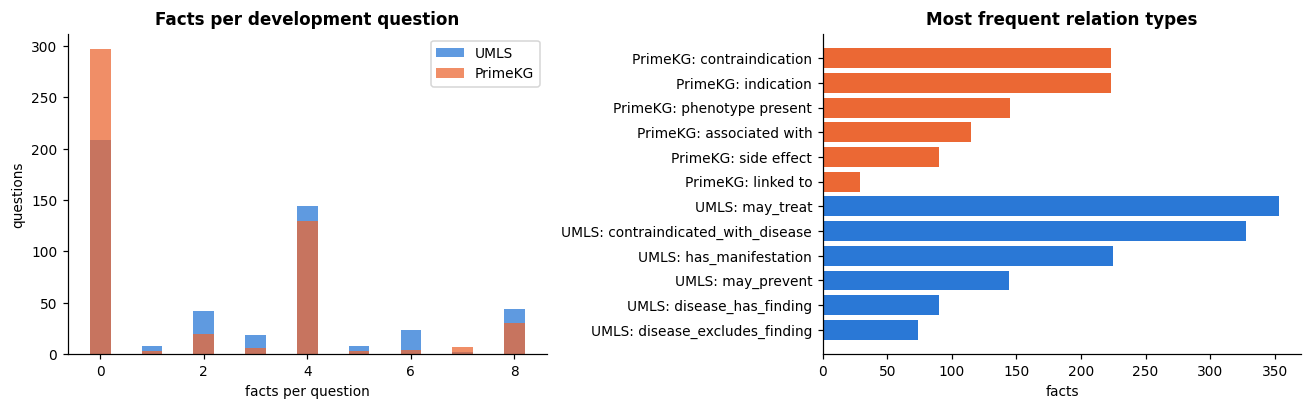

In [30]:
# Coverage: facts per question and relation types
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
cov_rows = []
for i, kg in enumerate(STUDY_KGS):
    n = np.array([len(FACTS[kg][e.pmid]) for e in dev_pool])
    axes[0].hist(n + (i - 0.5) * 0.35, bins=np.arange(-0.5, 9.5, 1), alpha=0.75, label=KG_NAMES[kg],
                 color=KG_COLORS[kg], rwidth=0.4)
    rel = Counter(f.display_relation for fs in KG_SETUP[kg]["facts_obj"].values() for f in fs)
    for r_, c in rel.items():
        cov_rows.append({"kg": kg, "relation": r_, "facts": c})
    print(f"{KG_NAMES[kg]}: questions with 0 facts {int((n == 0).sum())}, with 8 facts {int((n == 8).sum())}, "
          f"mean {n.mean():.2f}")
axes[0].set(xlabel="facts per question", ylabel="questions", title="Facts per development question")
axes[0].legend()
cov = pd.DataFrame(cov_rows).sort_values(["kg", "facts"], ascending=[True, False])
top = cov.groupby("kg").head(6)
axes[1].barh([f"{KG_NAMES[k]}: {r_}" for k, r_ in zip(top.kg, top.relation)], top.facts,
             color=[KG_COLORS[k] for k in top.kg])
axes[1].invert_yaxis(); axes[1].set(xlabel="facts", title="Most frequent relation types")
plt.tight_layout(); save_fig(fig, "retrieval_coverage"); plt.show()
cov.to_csv(R["retrieval"] / "relation_counts.csv", index=False)

# 7. Experimental design

## 7.1 The six conditions

Every question is given to the model in six ways. **These names are used everywhere in this notebook.**

| Condition | Input provided to the model | Purpose |
|---|---|---|
| **E1** | Question only | Establish the question-only baseline. |
| **E2** | Question + abstract | Measure the benefit of providing the original PubMedQA abstract. |
| **E3** | Question + relevant KG facts | Examine whether relevant KG facts help without the abstract. |
| **E4** | Question + abstract + relevant KG facts | Examine whether KG facts provide additional benefit when the abstract is already available. |
| **C3** | Question + matched irrelevant KG facts | Control for the effect of adding KG context without the abstract. |
| **C4** | Question + abstract + matched irrelevant KG facts | Control for the effect of adding KG context when the abstract is available. |

"Relevant facts" means the facts our pipeline retrieved for this question (Section 6.1). "Irrelevant facts" are the
matched controls (Section 6.2). Whether the retrieved facts are actually *useful* is a separate question that we
answer in Section 11.

## 7.2 The comparisons

| # | Comparison | Question it answers |
|---|---|---|
| 1 | **E1 vs E2** | How much does the abstract improve performance? (a positive control: if this did not help, something would be wrong) |
| 2 | **E1 vs E3** | What happens when relevant KG facts are added without the abstract? |
| 3 | **E2 vs E4** | Do relevant KG facts provide additional information beyond the abstract? |
| 4 | **E1 vs C3** | What happens when irrelevant KG facts are added without the abstract? |
| 5 | **E2 vs C4** | What happens when irrelevant KG facts are added alongside the abstract? |
| 6 | **E3 vs C3** | Do relevant facts perform better than matched irrelevant facts without the abstract? |
| 7 | **E4 vs C4** | Do relevant facts perform better than matched irrelevant facts when the abstract is available? |

**Why we need both relevant and control conditions.** If E4 were better than E2, there would be two explanations:
the facts carry useful knowledge, or the model simply behaves differently when the prompt is longer or contains a
"background facts" block. The control conditions have the same format and length but no useful content, so only
**E3 vs C3** and **E4 vs C4** isolate the effect of the content. Comparisons 2-5 tell us the total effect of adding
facts; comparisons 6-7 tell us whether the content is what matters.

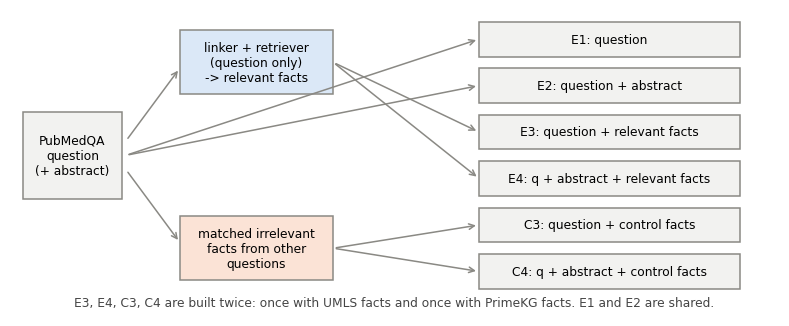

In [31]:
# Flowchart: how one question becomes six model inputs
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axis("off")


def box(x, y, text, color="#f2f2f0", w=0.17, h=0.17):
    ax.add_patch(plt.Rectangle((x - w / 2, y - h / 2), w, h, facecolor=color, edgecolor=GREY))
    ax.text(x, y, text, ha="center", va="center", fontsize=8)


def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color=GREY))


box(0.08, 0.5, "PubMedQA\nquestion\n(+ abstract)", w=0.13, h=0.3)
box(0.32, 0.82, "linker + retriever\n(question only)\n-> relevant facts", "#dbe8f7", w=0.2, h=0.22)
box(0.32, 0.18, "matched irrelevant\nfacts from other\nquestions", "#fbe3d6", w=0.2, h=0.22)
conds = [("E1", "question", 0.9), ("E2", "question + abstract", 0.74), ("E3", "question + relevant facts", 0.58),
         ("E4", "q + abstract + relevant facts", 0.42), ("C3", "question + control facts", 0.26),
         ("C4", "q + abstract + control facts", 0.1)]
for name, text, y in conds:
    box(0.78, y, f"{name}: {text}", w=0.34, h=0.12)
for name, text, y in conds:
    if name in ("E1", "E2"):
        arrow(0.15, 0.5, 0.61, y)
    elif name.startswith("E"):
        arrow(0.42, 0.82, 0.61, y)
    else:
        arrow(0.42, 0.18, 0.61, y)
arrow(0.15, 0.55, 0.22, 0.8)
arrow(0.15, 0.45, 0.22, 0.2)
ax.text(0.5, -0.02, "E3, E4, C3, C4 are built twice: once with UMLS facts and once with PrimeKG facts. E1 and E2 are shared.",
        ha="center", fontsize=8, color="#444")
ax.set_xlim(0, 1); ax.set_ylim(-0.05, 1)
save_fig(fig, "conditions_flowchart")
plt.show()

## 7.3 Rules we kept fixed

- **Same model, same prompt wording, same decoding** in all six conditions. Only the context block changes
  (`build_prompt` below).
- **E1 and E2 are shared baselines.** They contain no KG facts, so they are run once and reused for both KGs.
- **E3, E4, C3 and C4 are run separately for each KG.** "E4 with UMLS" and "E4 with PrimeKG" are two different runs;
  the KG decides which facts go in, the condition decides which parts of the input are present.
- **Paired design.** Relevant and control conditions use the same question (and the same abstract where present),
  so differences come only from the facts.
- **Questions without facts.** If a KG gives no facts for a question, E3 and C3 get exactly the E1 prompt, and E4 and
  C4 exactly the E2 prompt. These questions cannot change and are kept in the totals (so totals measure the effect on
  all questions). We report "covered" subsets separately.

## 7.4 The prompts

The system prompt and the answer format are the same in every condition; only the context block in the user
message changes. The abstract is all context sentences of the PubMedQA entry joined together; the conclusion
(`LONG_ANSWER`) is never included.

In [32]:
# Prompts for all six conditions (system prompt "e1-v1", context wording "kg-v1")
PROMPT_VERSION = "kg-v1"
CONDITIONS = ("E1", "E2", "E3", "E4", "C3", "C4")
SYSTEM_PROMPT = (
    "You are a careful biomedical expert. You will be given one biomedical research question. "
    "Classify the answer to the question as exactly one of these labels:\n"
    "- yes: the answer is affirmative\n"
    "- no: the answer is negative\n"
    "- maybe: the answer is uncertain or conditional\n"
    "Reply with only the label (yes, no, or maybe), in lowercase, with no explanation."
)
USER_TEMPLATE = "Question: {question}\nAnswer (yes, no, or maybe):"
FACT_HEADER = ("Background facts from a biomedical knowledge graph "
               "(they may be incomplete or not relevant to the question):")


def build_e1_prompt(question):
    """E1 takes ONLY the question string, so the abstract or facts cannot leak into it by accident."""
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": USER_TEMPLATE.format(question=question.strip())}]


def build_prompt(condition, question, abstract=None, facts=None):
    if condition not in CONDITIONS:
        raise ValueError(f"unknown condition {condition!r}")
    use_abs = condition in ("E2", "E4", "C4")
    use_facts = condition in ("E3", "E4", "C3", "C4") and bool(facts)
    if use_abs and not abstract:
        raise ValueError(f"{condition} needs an abstract")
    if condition == "E1" or not (use_abs or use_facts):
        return build_e1_prompt(question)
    parts = []
    if use_abs:
        parts.append(f"Abstract (conclusion removed): {abstract.strip()}")
    if use_facts:
        parts.append(FACT_HEADER + "\n" + "\n".join(f"- {f}" for f in facts))
    parts.append(f"Question: {question.strip()}\nAnswer (yes, no, or maybe):")
    return [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": "\n\n".join(parts)}]


def prompt_hash(messages):
    """The exact prompt is stored with every prediction as this hash."""
    return hashlib.sha256(json.dumps(messages).encode()).hexdigest()[:16]


def messages_for(config, e):
    """config = 'E1', 'E2' or '<condition>/<kg>', e.g. 'E4/umls'."""
    cond, kg = (config.split("/") + [None])[:2]
    facts = FACTS[kg][e.pmid] if cond in ("E3", "E4") else CONTROLS[kg][e.pmid] if cond in ("C3", "C4") else None
    return build_prompt(cond, e.question, e.abstract if cond in ("E2", "E4", "C4") else None, facts), len(facts or [])


CONFIGS = ["E1", "E2"] + [f"{c}/{kg}" for kg in STUDY_KGS for c in ("E3", "C3", "E4", "C4")]

p = "11555508"
for cfg in ("E1", "E3/primekg", "C4/primekg"):
    msgs, _ = messages_for(cfg, examples[p])
    text = msgs[-1]["content"]
    print(f"===== {cfg} =====")
    print(text if len(text) < 900 else text[:250] + "\n   [... rest of the abstract ...]\n" + text[-520:], "\n")
print("System prompt (same for all conditions):\n", SYSTEM_PROMPT)

===== E1 =====
Question: Do inhaled corticosteroids affect perception of dyspnea during bronchoconstriction in asthma?
Answer (yes, no, or maybe): 

===== E3/primekg =====
Background facts from a biomedical knowledge graph (they may be incomplete or not relevant to the question):
- Abacavir may cause Dyspnea as a side effect.
- Acebutolol is contraindicated in asthma.
- Acamprosate may cause Dyspnea as a side effect.
- Acetylcysteine is contraindicated in asthma.
- acute interstitial pneumonia is associated with the phenotype Dyspnea.
- Acefylline is indicated for asthma.
- acute lung injury is associated with the phenotype Dyspnea.
- Beclomethasone dipropionate is indicated for asthma.

Question: Do inhaled corticosteroids affect perception of dyspnea during bronchoconstriction in asthma?
Answer (yes, no, or maybe): 

===== C4/primekg =====
Abstract (conclusion removed): Some of the disagreements on the perception of dyspnea (PD) during bronchoconstriction in asthma patients could dep

### Checking the prompts against our original runs

Every prediction of our original study stored a hash of its exact prompt. Below we embed, for every configuration, one
digest of all 500 prompt hashes (a hash of hashes; it reveals nothing about the text). We rebuild all prompts here,
before any GPU work, and compare. If the digests match, this notebook sends **exactly the same 5,000 prompts per
model** as our original study: same facts, same controls, same wording, character for character.

We also check the rule from Section 7.3: on questions without facts, E3/C3 prompts must equal E1 and E4/C4 prompts
must equal E2.

In [33]:
# Reference data from our original runs (prompt digests and the original predicted labels, no text)
REFERENCE_LLM = json.loads(r"""{"prompt_digest":{"E1":"74ba476462549b47","E2":"0abeaf06f88b24c0","E3/umls":"4e7d54102fa3ad84","C3/umls":"ba39a569c292d36d","E4/umls":"3b4e2bca2b93c982","C4/umls":"d1882b57166f1f5b","E3/primekg":"75db3a3751861839","C3/primekg":"5c0cfda82b380c0f","E4/primekg":"8edd2169e0c91eb1","C4/primekg":"38c7353ef217ea17"},"models":{"Qwen/Qwen3-4B-Instruct-2507":{"E1":"mmmmmymmymmmyymmmmmmymmmymmymmmymmmnmymmymmmyymymmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmmmmyymmymyymmymmmmmmmmmmmymymymmmmymmmmmmmmmmmmmmmmymmmmmmmmymmyymmmymmmmymmmmmmymmmymmmmmmmmyymmmymmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmymmmmmmnmmmymmmmmnmmmmmmmmmmymmymmmymmymmmmmmmmmmmmmmmymmmymmmymmmmmmmmmmmmmmmymmmymmmmmmmmmmmmmymmmmmmmmmymmmmymmmmmmmmmmymnymmmmmmmmmmmmmmmmymmymmmmmyymmmmymmmmmmmmymmmmmmmmmmmymmmmmnmnmmmmmnmmmmmmmmmmymmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmymmmmmnmmmmmmmmymymmmmyymmmmymmmmyymymymmmmmmymm","E2":"mymmmyymmnmyyyymymyymmnmymmymymmmymnyyynmmmnmymyymynmmmymmymmymmymymnyynymyymnymmnyymyyyyyyyymymynmmmmmmyymmmnmyymnmyyyynmmyyyymymnymmnmymmymymmyymyymmymmmmmmmnmymymynmyyynymmmnymmyymymyyymymmyyyyyymmyymynnyyymmmyyymymymmmymmymyymmymnmmmmymmmymymnyymmymmnmnyyyyyyymmyynmymymyymyynymmmynymmmyymymymyyymmymymymymynnmnymymyymnmmmmymmmymyymmyyymmynymmymymmyyynmmyyyymmmymyyyyymymnmyymmymmyyyymmyyyyymymyyyymynymyyynmmyynmmmmyymnymmmymyyyymymmnymmymnymmyyymmynmymmmymmmmnymymynmmyymyymyymmmyymyynmyymmyyyy","E3/umls":"mmmmmymmymmmmymmmmmmmmmmmmmmmmmymmmnmymmmmmmmymymmmmmmmmmmmmmmmmmmmmmmmmmnmmmmmmmmmmmmmmmmmmyymmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmymmmymmmmmmmmmmmymmmymmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmymmmymmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmymmmmmmmmmmymnymmmmmmmmmmmmmmmmymmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmymmmmmnmnmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmymmmmymmmmmmmmmmmymymymmmmmmymm","C3/umls":"mmmmmymmymmmmymmmmmmmmmmmmmmmmmymmmmmymmmmmmmyyymmmmmmmmmmmmmmmmmmmmmmmmmnmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmymmmymmmmmmmmmmmymmmymmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmnmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmymmmymmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmymmmmmmmmmmymmymmmmmmmmmmmmmmmmymmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmymmmmmnmnmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmymmmmymmmmmymmmmmymymmmmmmmmymm","E4/umls":"mymmmyymmnmyyyymymmymmnmymmymyymmymnyyynmmmnmymyymynmmmymmymmymmymmmnyynymyyynymmnyymyyyyyyyymmmynmmmmmmyyymynmyymnmyyyynmmyyyymymnymmnmymmymymmyymyymmymmmmmmmnmymymymmmyynymymnymmyymymyyymymmyymyyymmyymynnyyymmmyyymymymmmmmmymyymmymnmmmmymmmymymnyymmymmnmnyyyyyyymmyynmymymyymyynymyyynymmmyyyymymyyymmymymymymynnmnymymyymnmmymyymmymyymmyyymmynymmyyymmyyynmmyyyymmmymyyyymyymnmyymmymmyyyymmyyyyymymyyyymynyyyyynmmyynmmmmyymnymmmymyyyymymmnymmymyymyyyymmynmymmmymmmmnynymynmmyymyymymmmmyymyynmyymmyyyy","C4/umls":"mymmmymnmnmyyyymymyymmnmymmymyymmymnyyymmmmnmyyyymynmmmmmmymmymmymmmnyynymyyynymmnymmyyyyyyymmmmynmmmmmnyymmynmyymnmyyyynmmyyyymymnymmnmymmynymmyymyymmymmmmmmmnmymymynmmmynymymnymmyymymyyymymmyyyyyymmyymynnyyymmmyyymymymmmmmmymyymmymnmmmmymmmymymnyymmymmnmnyyyyymymmyynmymymyymyynymyyynymmmyyyymymyyymmymymymymynnmnymymyymnmmymyymmymyymmyyymmymymmymymmyyynmmyyyymmmymyyyyyyymnmyymmymmyyyymmyyyyymymyyyymynyyyyynmmyynmmmmyymnymmmymyyyymymmnymmymyymyyyymmynmymmmymmmmnynymynmmyymyymyymmmyymyynmyymmyyyy","E3/primekg":"mmmmmymmymmmmymmmmmmmmmmymmmmmmymmmnmymmymmmmymymmmmmmmmmmmmmmmmmmmmmmmmmnmmmmmmmmmmmmyymmmmyymmmmmmmmmmmmmmymmmymmmmymmmmmmmmmmmmmmmmymmmmmmmmmmmyymmmymmmmmmmmmmmymmmymmmmmmymyymmmymmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmnmmmymmmmmmmmmmmmmmmmymmymmmmmmymmmmmmmmmmmmmmmmmmmymmmymmmmmmmmmmmmmmmymmmymmmmmmmmmmmmmmmmmmmmmmmymmmmymmmmmmmmmmymmymmmmmmmmmmmmmmmmymmymmmmmmmmmmmymmmmmmmmymmmmmmmmmmmymmmmmnmnmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmymmmmymmmmmmmmmmmymymymmmmmmymm","C3/primekg":"mmmmmymmymmmmymmmmmmmmmmymmmmmmymmmnmymmymmmmymymmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmyymmmmyymmmmmmmmmmmmmmymmmymmmmymmmmmmmmmmmmmmmmymmmmmmmmmmmyymmmymmmmmmmmmmmymmmymmmmmmmmyymmmymmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmnmmmymmmmmmmmmmmmmmmmymmymmmmmmymmmmmmmmmmmmmmmmmmmymmmymmmmmmmmmmmmmmmymmmymmmmmmmmmmmmmmmmmmmmmmmymmmmymmmmmmmmmmymmymmmmmmmmmmmmmmmmymmymmmmmmmmmmmymmmmmmmmymmmmmmmmmmmymmmmmnmnmmmmmnmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmymmmmymmmmmmmmmmmymymmmmmmmmymm","E4/primekg":"yymmmymmmnmyyyymymmymmnmymmymyymmymnyymmmmmnmymyymynmmmymmymmymmymymnyynymyyynymmmyymmyyyyyyymmmynmmmmmmyymmmnmyymnmyyyynmmyyyymymnymynmymmynymmyymyymmymmmmmmmnmymymynmmyynymymnymmyymymyyymymmyyyyyymmyymynnyyymmmyyymymymmmymmymyymmymnmmmyymmmymymnyymmymmnmnyyyyyyymmyynmymymyymyynymymynymmmyyyymymmyymmymymymymynnmnymymyymnmmymymmmymyymmyyyymynymmymymmyyynmmyyyymmmymyyyyymymnmyymmymmyyyymmyyyyymymyyyymynyyyyynmmyynmmmmyymnymmmymyyyymymmnymmymnymyyyymmynmymmmymmmmnynymynymyymyymyymmmyymyynmyymmyyym","C4/primekg":"yymmmymmmnmyyyymymyymmnmymmymyymmymnyymmmmmnmymyymynmmmymmymmymmymymnyynymyymnymmmyymyyyyyyyymymynmmmmmmyymmmnmyymnmyyyynmmyyyymymnymmnmymmynymmyymyymmymmmmymmnmymymynmmyynymymnymmyymymyyymymmyyyyyymmyymynnyyymmmyyymymymmmymmymyymmymnmmmyymmmymymnyymmymmnmnyyyyymymmyynmymymyymyynymymynymmmyyyymymyyymmymyyymymynnmnymymyymnmmymyymmymyymmyymmmynymmymymmyyynmmyyyymmmymyyyyymymnmyymmymmyyyymmyyyyymymyyyymynyyyyynmmyynmmmmyymnymmmymyyyymymmnymmymyymyyyymmynmymmmymmmmnynymynmmyymyymyymmmyymyynmyymmyyyy"},"microsoft/Phi-4-mini-instruct":{"E1":"yymmmmmmmmymymmmmmmmyymmmmmmmmmmmmmnmymymmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmyymmymmmmmymmmmmymmymmmymmmmymmmmmmmmmmmmmmmmymmmmmmmmmmymymmmymmmmmmmmmmmmmmmmmnmmymmmymymmmmmmmmmymmmmmmmmmmmymmymmmmmmmmmmmmmmmmmymmmmmmynmmmmmmmmmmmmmmymmmmmmymmmmmmmmmmmmmmmymmmmymmymmmmmmmmmmmymmmmmymmnmmmmmmmmmmmyymmmmmmmmmmmmmmymmymmmmmmmmmmmymmmmmmmmmmmmymmmmmmmmmmmmmmyymmmmymmmmmmmmmmmmmmmmmmmmmmmmmmnmnmmmmmmmmmmymmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmmymmmymmmmmmmmmmmmmmymymmmmmmmmymymmmmmmmmmymmmmmmymm","E2":"yymmyymmmnnyyymmymmmmmmmmmmymymmmymnyynymmmnmmyyymynmmmmmmymmmmmymmmmmynymmymnymmnymymmyyyyymmmmynmymmmmyymmynmyymmmmyymnmmyyyymymnmmmmmymmymmmmyyyymmmmmmmmmmmmmynmmynmmmymymymmymmyymymyyyymmmyymmmymmymmynyyymmmmyyymmmymmmmymymyymmynnmmmyymmmymynmyymmymmnmnyyyyymymmyynmmmymyymmmnymmmynymmmmyyymmmmyynmymmmymymymnmnmmmmymmnmmmmymmmmmmymmyyymmymymmmnmmmymmnnmmyyymmmymyyyymmymmmyymmymmyyyymmyynmymymymymmymymymynmmymmmmmmyymmymmmynyyyymymmnmmmymmmmyymymmymmymmmmmmmmnymymmmmmymnmymymmmmymmyynmyymmmyym","E3/umls":"mymmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmnmymymmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmnmmmmmmmmmmmmmmmmyymmmmmymmmmmymmymmmymmmmmmmmmmmmmmmmmmmmmymmmmmymmmmymymmmymmmmmmmmmmmmmmmmmmmmmmmmymymmmmmmmmmmmmmmmmmmmmmymmymmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmymmmmmmmmnmmmmmmmmmmmmmmmmmmmmmmmmmmmymmymmmmmmmmmmmmmmmmmmmmmmmnymmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmymmmmmmmmymmmmmmmmmmmmmmmmmmymm","C3/umls":"mymmmmmmmmymmmmmmmmmyymmmmmmmmmmmmmnyymmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmymmmmmymmmmmymmymmmymmmmymmmmmmmmmmmmmmmmymmmmmymmmmymymmmymmmmmmmmmmmmmmmmmmmmmmmmymymmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmymmmmymmmmmmmmmmmmmmymmmmmmmmnmmmmmmmmmmmymmmmmmmmmmmmmmmymmymmmmmmmmymmymmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmnmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmymmmmmmmmymmmmmmmmmmmmmmmmmmymm","E4/umls":"yymmyymmmnnyyymmymmmmymmmmmymymmmymnyymymmmnmmyyymynmmmmmmymmmmmymmmmmynynyymnymmnymymmyyyyymmmmynmymmmmyyymynmyymmmmyymnmmyyyymymnmmmmmymmymmmmyyyymmmmmmmmmmymmymmmynmmmymymymmymmyymymyyyymmmyymmmymmymmynyyymmmmyyymmmymmmmymymyymmynmmmmyymymymynmyymmymnnmnyyyyymymmyynmymymyymymnymmmynymmmmyyymmmmyynmymmmymymymnmnmmmmymmnmmmmymmmmmmymmyyymmymymmmnmmmymmnnmmyyymmmymyyyymmymmmyymmymmyyyymmyymmymymymymmmmymymynmmymmmmmmyymmymmmynyyyymyymnmmmymmmmyymymmymmymmmmmmmmnymymmmmmymnmymymmmmymnyymmyymmyyyy","C4/umls":"yymmyymmmnnyyymmymymmymmmmmymymmmymnyymymmmnmmyyymynmmmmmmymmmmmymmmmmynymyymnymmnymymyyyyyymmymynmymmmmyymmynmyymmmmyymnmmyyyymymnmmmmmymmymmmmyyyymmmmmmmmmmmmmymmmynmmmymymymmymmyymymyyyymmmyymmmymmymmynyyymmymyyymmmymmmmymymyymmynnmmyyymymymynmyymmymnnmnyyyyymymmyynmymymyymymnymmmynymmmmyyymmmmyynmymmmymymymnmnmmmmymmnmmmmymmmmmmymmyyymmymymmmnmmmymmnnmmyyymmmymyyyymmymmmyymmymmyyyymmyymmymymymymmymymymynmmymmmmmmyymmymmmynyyyymyymnmmmymmymyyyymmymmymmmmmmmmnymymmnmmymnmymymmmmymnyynmyymmyyyy","E3/primekg":"mymmmmmmmmymymmmmmmmyymmmmmmmmmmmmmnmymymmmmmmmymmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmymmmmmymmmmmymmymmmymmmmymmmmmmmmmmmmmmmmymmmmmymmmmymymmmymmmmmmmmmmmmmmmmmnmmmmymymymmmmmmmmmymmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmnmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmymmmmymmymmmmmmmmmmmymmmmmymmnmmmmmmmmmmmymmmmmmmmmmmmmmmymmymmmmmmmmmmmmmmmmmmmmmmmnymmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmymmmmmmmmymmmmmmymmmmmmmmmmmymm","C3/primekg":"mymmmmmmmmymymmmmmmmyymmmmmmmmmmmmmnmmmmmmmmmmmymmmmmmmmmymmmmmmmmmmmmmmmymmmmmymmmymmmmmymmmymmmmmymmmmmymmymmmymmmmymmmmmmmmmmmmmmmmymmmmmymmmmymymmmymmmmmmmmymmmmmmmmnmmmmmmymymmmmmmmmmmmmmmmmmmmmmymmymmmmmmmmmmmmmmmmmymmmmmmmnmmmmmmmmmmmmmmymmmmmmymmmmmmmmmmmmmmmymmmmymmymmmmmmmmmmmymmmmmymmnmmmmmmmmmmmymmmmmmmmmmmmmmmymmymmmmmmmmmmmymmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmymmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmymmmmmmmmmmmmmmmmymmmmmmmmymmmmmmymmmmmmmmmmmymm","E4/primekg":"yymmyymmmnnyyymmymmmmymmmmmymymmmymnyymymmmnmmyyymynmmmmmmymmmmmymmmmmynymmymnymmnymymmyyyyymmmmynmymmmmyymmynmyymmmmyymnmmyyyymymnmmmmmymmymmmmyyyymmmmmmmmmmmmmynmmynmmmymymymmymmyymymyyyymmmyymmmymmymmynyyymmmmyyymmmymmmmymymyymmynmmmmyymmmymynmyymmymmnmnyyyyymymmyynmymymyymymnymmmynymmmmyyymmmmyynmymmmymymymnmnmmmmymmnmmmmymmmmmmymmyyymmymymmmnmmmymmnnmmyyymmmymyyyymmymmmmymmymmyyyymmyynmymymymymmymymymynmmymmmmmmyymmymmmynyyyymymmnmmmymmmmyyyymmymmymmmmmmmmnymymmmmmymnmymymmmmymnyynmyymmmyym","C4/primekg":"yymmyymmmnnyyymmymmmmymmmmmymymmmymnyymymmmnmmyyymynmmmmmmymmmmmymmmmmynymyymnymmnymymmyyyyymmmmynmymmmmyymmynmyymmmmyymnmmyyyymymnmmmmmymmymmmmyyyymmmmymmmmmymmynmmynmmmymymymmymmyymymyyyymmmyymmmymmymmynyyymmmmyyymmmymmmmymymyymmynnmmyyymmmymynmyymmymnnmnyyyyymymmyynmymymyymymnymmmynymmmmyyymmmmyynmymmmymymymnmnmmmmymmnmmmmymmmmmmymmyyymmymymmmnmmmymmnnmmyyymmmymyyyymmymmmyymmymmyyyymmyynyymymymymmymymymynmmymmmmmmyymmymmmynyyyymymmnmmmymmymyyyymmymmymmmmmmmmnymymmnmmymnmymymmmmymnyynmyymmyyyy"}},"pmids_sha":"4d90a3ef08ba887e"}""")
REF_PMIDS = sorted(e.pmid for e in dev_pool)
assert hashlib.sha256(",".join(REF_PMIDS).encode()).hexdigest()[:16] == REFERENCE_LLM["pmids_sha"], \
    "the development pool differs from the original one"

PROMPT_HASHES, N_FACTS = {}, {}
for cfg in CONFIGS:
    PROMPT_HASHES[cfg], N_FACTS[cfg] = {}, {}
    for e in dev_pool:
        msgs, n = messages_for(cfg, e)
        PROMPT_HASHES[cfg][e.pmid], N_FACTS[cfg][e.pmid] = prompt_hash(msgs), n


def digest(hashes):
    return hashlib.sha256("\n".join(f"{k}:{hashes[k]}" for k in sorted(hashes)).encode()).hexdigest()[:16]


prompt_check = pd.DataFrame([{"config": c, "prompts": len(PROMPT_HASHES[c]), "digest": digest(PROMPT_HASHES[c]),
                              "original digest": REFERENCE_LLM["prompt_digest"][c]} for c in CONFIGS])
prompt_check["identical to original"] = prompt_check["digest"] == prompt_check["original digest"]
display(prompt_check)

same = {}
for kg in STUDY_KGS:
    for c, base in (("E3", "E1"), ("C3", "E1"), ("E4", "E2"), ("C4", "E2")):
        unc = [p for p in REF_PMIDS if N_FACTS[f"{c}/{kg}"][p] == 0]
        same[f"{c}/{kg}"] = f"{sum(PROMPT_HASHES[f'{c}/{kg}'][p] == PROMPT_HASHES[base][p] for p in unc)}/{len(unc)}"
print("Questions without facts whose prompt equals the baseline prompt:", same)
save_json({"prompt_check": prompt_check.to_dict("records"), "uncovered_identical": same},
          R["llm"] / "prompt_identity_check.json")
if not prompt_check["identical to original"].all():
    print("WARNING: some prompts differ from the original study. Results for those configurations are not comparable.")

,config,prompts,digest,original digest,identical to original
0,E1,500,74ba476462549b47,74ba476462549b47,True
1,E2,500,0abeaf06f88b24c0,0abeaf06f88b24c0,True
2,E3/umls,500,4e7d54102fa3ad84,4e7d54102fa3ad84,True
3,C3/umls,500,ba39a569c292d36d,ba39a569c292d36d,True
4,E4/umls,500,3b4e2bca2b93c982,3b4e2bca2b93c982,True
5,C4/umls,500,d1882b57166f1f5b,d1882b57166f1f5b,True
6,E3/primekg,500,75db3a3751861839,75db3a3751861839,True
7,C3/primekg,500,5c0cfda82b380c0f,5c0cfda82b380c0f,True
8,E4/primekg,500,8edd2169e0c91eb1,8edd2169e0c91eb1,True
9,C4/primekg,500,38c7353ef217ea17,38c7353ef217ea17,True


Questions without facts whose prompt equals the baseline prompt: {'E3/umls': '209/209', 'C3/umls': '209/209', 'E4/umls': '209/209', 'C4/umls': '209/209', 'E3/primekg': '297/297', 'C3/primekg': '297/297', 'E4/primekg': '297/297', 'C4/primekg': '297/297'}


# 8. LLM experiments

## 8.1 Models and how we chose them

- **Main model: Qwen3-4B-Instruct-2507** (4B parameters, Apache 2.0, not gated), run with Hugging Face
  `transformers` in fp16 on a free Colab T4 GPU.
- **Second model: Phi-4-mini-instruct** (3.8B, MIT licence, different model family), same setup, to check whether the
  results depend on the model.

**A failed first attempt.** We started with a local pilot using Ollama and `qwen3:4b` (4-bit). That model is a
"thinking" model: in a 5-question smoke test, 5 of 5 replies were long reasoning texts cut off at the token limit,
and no setting stopped this. We switched to the *instruct* version, chosen only for output reliability, not
accuracy. The pilot used a different backend (4-bit Ollama) and is not part of the results below.

## 8.2 Inference settings and parsing

| Setting | Value |
|---|---|
| Decoding | greedy (no sampling), at most 16 new tokens |
| Precision | fp16 |
| Prompt | fixed system prompt + one user message (Section 7.4), formatted with the model's own chat template |
| Parsing | strict: the reply must be exactly `yes`, `no` or `maybe` (optionally "answer:" in front); anything else is invalid and counted as wrong |
| Also saved | the log-probabilities of the three label tokens, the number of facts, and a hash of the exact prompt |

Each model produces 5,000 predictions: 500 questions x 10 configurations (the shared E1 and E2, plus E3, E4, C3 and
C4 for each of the two KGs).

In [34]:
# The strict parser and the metrics
_THINK_BLOCK = re.compile(r"<think>.*?</think>", re.DOTALL | re.IGNORECASE)
_LABEL = re.compile(r"^(?:(?:final\s+)?answer\s*[:\-]\s*)?(yes|no|maybe)$")


def parse_label(text):
    """'yes', 'no' or 'maybe', or None when the reply is not a clean single label. We never guess."""
    if not isinstance(text, str):
        return None
    cleaned = _THINK_BLOCK.sub("", text).strip().lower()
    cleaned = cleaned.strip(" \t\r\n*_`\"'.!,;:()[]")
    match = _LABEL.match(cleaned)
    label = match.group(1) if match else None
    return label if label in LABELS else None


INVALID = "invalid"
PQAL_MAJORITY_ACCURACY = 552 / 1000   # always answering "yes" on all 1,000 PQA-L questions


def compute_metrics(gold, pred):
    """Invalid or missing predictions (None) count as WRONG; macro-F1 averages the F1 of yes, no and maybe."""
    if len(gold) != len(pred):
        raise ValueError("gold and pred must have the same length")
    if not gold:
        raise ValueError("no examples to evaluate")
    n = len(gold)
    columns = list(LABELS) + [INVALID]
    matrix = [[0] * len(columns) for _ in LABELS]            # rows = gold, columns = predicted
    for g, p in zip(gold, pred):
        if g not in LABELS:
            raise ValueError(f"unknown gold label {g!r}")
        matrix[LABELS.index(g)][LABELS.index(p) if p in LABELS else len(LABELS)] += 1
    per_class = {}
    for i, label in enumerate(LABELS):
        tp, support = matrix[i][i], sum(matrix[i])
        predicted = sum(matrix[r][i] for r in range(len(LABELS)))
        precision = tp / predicted if predicted else 0.0
        recall = tp / support if support else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        per_class[label] = {"precision": precision, "recall": recall, "f1": f1, "support": support}
    correct = sum(matrix[i][i] for i in range(len(LABELS)))
    no_prediction = sum(row[-1] for row in matrix)
    valid = n - no_prediction
    gold_counts = {lab: sum(matrix[i]) for i, lab in enumerate(LABELS)}
    return {"n": n, "accuracy": correct / n, "accuracy_valid_only": correct / valid if valid else None,
            "macro_f1": sum(c["f1"] for c in per_class.values()) / len(LABELS), "per_class": per_class,
            "confusion_matrix": {"rows_gold": list(LABELS), "columns_predicted": columns, "matrix": matrix},
            "predicted_distribution": {col: sum(matrix[r][j] for r in range(len(LABELS))) for j, col in enumerate(columns)},
            "no_prediction_count": no_prediction,
            "majority_baseline_accuracy_this_split": max(gold_counts.values()) / n,
            "majority_baseline_accuracy_pqal_full": PQAL_MAJORITY_ACCURACY}


for reply in ["yes", "Maybe", "Answer: no", "The answer is yes because ...", "<think>hmm</think>no", ""]:
    print(f"{reply!r:40} -> {parse_label(reply)}")

'yes'                                    -> yes
'Maybe'                                  -> maybe
'Answer: no'                             -> no
'The answer is yes because ...'          -> None
'<think>hmm</think>no'                   -> no
''                                       -> None


In [35]:
# The model backend: Hugging Face transformers, fp16, greedy decoding
class HFBackend:
    def __init__(self, model_id, max_new_tokens=16, dtype="float16"):
        import torch, transformers
        from transformers import AutoModelForCausalLM, AutoTokenizer
        self.torch, self.model_id, self.max_new_tokens = torch, model_id, max_new_tokens
        self.transformers_version = transformers.__version__
        self.tok = AutoTokenizer.from_pretrained(model_id)
        want = getattr(torch, dtype)
        major, minor = (int(x) for x in transformers.__version__.split(".")[:2])
        kw = {"dtype": want} if (major, minor) >= (4, 56) else {"torch_dtype": want}   # kwarg renamed in 4.56
        self.model = AutoModelForCausalLM.from_pretrained(model_id, device_map="auto", **kw)
        self.model.eval()
        if self.model.dtype != want:          # never run silently in another precision
            raise RuntimeError(f"model loaded as {self.model.dtype}, expected {want}")
        self.label_ids = {l: self.tok.encode(l, add_special_tokens=False)[0] for l in LABELS}
        self.label_token_counts = {l: len(self.tok.encode(l, add_special_tokens=False)) for l in LABELS}

    def _inputs(self, messages):
        text = self.tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        return self.tok(text, return_tensors="pt").to(self.model.device)

    def generate(self, messages):
        enc = self._inputs(messages)
        with self.torch.no_grad():
            # greedy; sampling parameters set to None so the model's own generation_config cannot apply
            out = self.model.generate(**enc, max_new_tokens=self.max_new_tokens, do_sample=False,
                                      temperature=None, top_p=None, top_k=None, pad_token_id=self.tok.eos_token_id)
        new = out[0][enc["input_ids"].shape[1]:]
        return {"text": self.tok.decode(new, skip_special_tokens=True),
                "prompt_tokens": int(enc["input_ids"].shape[1]), "output_tokens": int(len(new))}

    def label_logprobs(self, messages):
        """Log-probabilities of the first token of 'yes', 'no' and 'maybe' at the answer position."""
        enc = self._inputs(messages)
        with self.torch.no_grad():
            logits = self.model(**enc).logits[0, -1].float()
        lp = self.torch.log_softmax(logits, dim=-1)
        return {l: float(lp[i]) for l, i in self.label_ids.items()}

    def describe(self):
        return {"backend": "hf", "model": self.model_id, "max_new_tokens": self.max_new_tokens,
                "dtype": str(self.model.dtype), "do_sample": False, "decoding": "greedy",
                "transformers": self.transformers_version, "label_token_ids": self.label_ids,
                "label_token_counts": self.label_token_counts}


def argmax_label(scores):
    if not scores:
        return None
    return max(LABELS, key=lambda l: (scores.get(l, -math.inf), -LABELS.index(l)))

## 8.3 Running the experiments

The next cell runs every configuration for every model in `LLM_MODELS`. It needs a GPU and takes about 45-50 minutes
per model on a T4.

**Checkpoints.** Each prediction is appended to `results/llm/raw_predictions/<model>/<configuration>.jsonl` and flushed
to disk at once. If the session stops, run the cell again: finished questions are skipped (rows with a backend error
are asked again). Each model folder stores its settings (model, decoding, prompt version) and, per configuration, a
digest of its 500 exact prompts. The cell stops if you try to continue a folder with different settings or prompts, so
results from different settings are never mixed; adding a KG later (for example UMLS after a PrimeKG-only run) only
adds new configurations. The model description (including the `transformers` version) is also stored and must match
on resume.

In [36]:
# Run all conditions for all models (GPU; resumable)
def model_tag(model_id):
    return model_id.split("/")[-1]


def fact_digest(store):
    return hashlib.sha256(json.dumps(store, sort_keys=True).encode()).hexdigest()[:16]


def llm_settings(model_id):
    """Settings shared by all configurations of one model."""
    return {"model": model_id, "max_new_tokens": 16, "dtype": "float16", "decoding": "greedy",
            "prompt_version": PROMPT_VERSION, "n_questions": len(dev_pool),
            "questions_sha": REFERENCE_LLM["pmids_sha"], "seed": SEED}


def config_parts():
    """One entry per configuration: a digest of its 500 exact prompts (facts, controls and wording included)."""
    return {cfg: digest(PROMPT_HASHES[cfg]) for cfg in CONFIGS}


def pred_path(model_id, cfg):
    return R["llm_raw"] / model_tag(model_id) / (cfg.replace("/", "_") + ".jsonl")


def read_done(path):
    done = {}
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            try:
                r = json.loads(line)
            except json.JSONDecodeError:       # a torn last line after a disconnect
                continue
            if r.get("status") != "error":
                done[r["pmid"]] = r
    return done


def write_rows(path, done):
    tmp = path.with_suffix(".tmp")
    tmp.write_text("".join(json.dumps(done[e.pmid], ensure_ascii=False) + "\n" for e in dev_pool if e.pmid in done),
                   encoding="utf-8")
    tmp.replace(path)                                       # atomic: a disconnect cannot leave half a file


def run_config(backend, model_id, cfg):
    path = pred_path(model_id, cfg)
    done = read_done(path)
    if len(done) == len(dev_pool):
        return done
    write_rows(path, done)                                  # rewrite cleanly, in question order
    t0, todo = time.time(), [e for e in dev_pool if e.pmid not in done]
    cond = cfg.split("/")[0]
    with open(path, "a", encoding="utf-8") as fh:
        for k, e in enumerate(todo, 1):
            messages, n_facts = messages_for(cfg, e)
            try:
                gen = backend.generate(messages)
                label, err = parse_label(gen["text"]), None
                status = "ok" if label else "invalid"
            except Exception as ex:                          # recorded, never guessed
                gen, label, status, err = {"text": None, "prompt_tokens": None, "output_tokens": None}, None, "error", str(ex)
            scores = backend.label_logprobs(messages) if status != "error" else None
            rec = {"pmid": e.pmid, "condition": cond, "config": cfg, "gold": e.label, "predicted": label,
                   "status": status, "error": err, "raw_response": gen["text"], "pred_scored": argmax_label(scores),
                   "label_logprobs": scores, "n_facts": n_facts, "prompt_tokens": gen["prompt_tokens"],
                   "output_tokens": gen["output_tokens"], "prompt_sha256": prompt_hash(messages)}
            fh.write(json.dumps(rec, ensure_ascii=False) + "\n")
            fh.flush(); os.fsync(fh.fileno())
            done[e.pmid] = rec
            if k % 100 == 0 or k == len(todo):
                rate = (time.time() - t0) / k
                print(f"   {cfg}: {len(done)}/{len(dev_pool)}  ({rate:.2f} s/question, "
                      f"about {rate * (len(todo) - k) / 60:.0f} min left)")
    write_rows(path, done)                                  # finished: keep the file in question order
    return done


LLM_PREDS = {}
for model_id in LLM_MODELS:
    folder = R["llm_raw"] / model_tag(model_id)
    folder.mkdir(parents=True, exist_ok=True)
    checkpoint_ok(folder, llm_settings(model_id))
    check_parts(folder, config_parts())
    complete = all(len(read_done(pred_path(model_id, c))) == len(dev_pool) for c in CONFIGS)
    if not complete:
        if not (RUN_LLM and HAS_GPU):
            print(f"{model_tag(model_id)}: not complete and no GPU (or RUN_LLM = False); skipped.")
            continue
        print(f"{model_tag(model_id)}: loading the model (about 8 GB download the first time) ...")
        backend = HFBackend(model_id)
        meta_path = folder / "run_meta.json"
        if meta_path.exists() and load_json(meta_path)["backend"] != json.loads(json.dumps(backend.describe())):
            raise RuntimeError(f"{folder} was started with a different model setup: {load_json(meta_path)['backend']}")
        if not meta_path.exists():
            save_json({"backend": backend.describe(), "prompt_version": PROMPT_VERSION, "started": datetime.now().isoformat(),
                       "official_test_set_used": False}, meta_path)
        for cfg in CONFIGS:
            run_config(backend, model_id, cfg)
        del backend
        import gc, torch
        gc.collect(); torch.cuda.empty_cache()
    LLM_PREDS[model_id] = {c: read_done(pred_path(model_id, c)) for c in CONFIGS}
    print(f"{model_tag(model_id)}: {sum(map(len, LLM_PREDS[model_id].values()))} predictions available")

Qwen3-4B-Instruct-2507: 5000 predictions available
Phi-4-mini-instruct: loading the model (about 8 GB download the first time) ...


config.json:   0%|          | 0.00/2.50k [00:00<?, ?B/s]

[transformers] This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


tokenizer_config.json:   0%|          | 0.00/2.93k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 15.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (4 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/194 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/168 [00:00<?, ?B/s]

   E2: 100/500  (0.41 s/question, about 3 min left)
   E2: 200/500  (0.40 s/question, about 2 min left)
   E2: 300/500  (0.41 s/question, about 1 min left)
   E2: 400/500  (0.42 s/question, about 1 min left)
   E2: 500/500  (0.42 s/question, about 0 min left)
   E3/umls: 100/500  (0.26 s/question, about 2 min left)
   E3/umls: 200/500  (0.25 s/question, about 1 min left)
   E3/umls: 300/500  (0.25 s/question, about 1 min left)
   E3/umls: 400/500  (0.25 s/question, about 0 min left)
   E3/umls: 500/500  (0.25 s/question, about 0 min left)
   C3/umls: 100/500  (0.25 s/question, about 2 min left)
   C3/umls: 200/500  (0.26 s/question, about 1 min left)
   C3/umls: 300/500  (0.25 s/question, about 1 min left)
   C3/umls: 400/500  (0.25 s/question, about 0 min left)
   C3/umls: 500/500  (0.25 s/question, about 0 min left)
   E4/umls: 100/500  (0.47 s/question, about 3 min left)
   E4/umls: 200/500  (0.47 s/question, about 2 min left)
   E4/umls: 300/500  (0.47 s/question, about 2 min left)

## 8.4 Analysis

All metrics and tests are computed from the raw predictions above. First the predictions are **validated**:
500 questions per configuration, no duplicates, gold labels equal to the dataset, no backend errors, no test-set
question, one model setup for all configurations, and identical answers on the questions where E3/C3/E4/C4 have the
same prompt as E1/E2.

Then, as planned before we looked at the results:

- metrics per configuration with a 95% bootstrap CI for accuracy;
- the planned comparisons with the exact **McNemar** test, a 95% **paired bootstrap** CI (2,000 resamples, seed 42)
  for the accuracy and macro-F1 differences, and **Holm** correction within each family: UMLS (4 tests), PrimeKG
  (4 tests) and UMLS vs PrimeKG (4 tests). The abstract benefit (E1 -> E2) is a positive control and is not
  corrected;
- exploratory rows (uncorrected): covered subsets, Dev-100 and Dev-400 separately, and a sensitivity check without
  question 11978239, whose PrimeKG control fact names a question concept through a different node.

In [37]:
# The statistics code
ITERS = 2000
SENSITIVITY_DROP = {"primekg": ["11978239"]}      # a control fact that names a question concept via another node
KG_CONDS = ("E3", "C3", "E4", "C4")
COMPARISONS = [   # (family, name, config A, config B); difference = B - A
    ("positive_control", "Abstract benefit: E1 -> E2", "E1", "E2"),
    ("primary_umls", "UMLS facts without abstract: E1 -> E3", "E1", "E3/umls"),
    ("primary_umls", "UMLS relevant vs control: C3 -> E3", "C3/umls", "E3/umls"),
    ("primary_umls", "UMLS facts with abstract: E2 -> E4", "E2", "E4/umls"),
    ("primary_umls", "UMLS relevant vs control: C4 -> E4", "C4/umls", "E4/umls"),
    ("secondary_primekg", "PrimeKG facts without abstract: E1 -> E3", "E1", "E3/primekg"),
    ("secondary_primekg", "PrimeKG relevant vs control: C3 -> E3", "C3/primekg", "E3/primekg"),
    ("secondary_primekg", "PrimeKG facts with abstract: E2 -> E4", "E2", "E4/primekg"),
    ("secondary_primekg", "PrimeKG relevant vs control: C4 -> E4", "C4/primekg", "E4/primekg"),
    ("kg_comparison", "UMLS vs PrimeKG: E3", "E3/primekg", "E3/umls"),
    ("kg_comparison", "UMLS vs PrimeKG: C3", "C3/primekg", "C3/umls"),
    ("kg_comparison", "UMLS vs PrimeKG: E4", "E4/primekg", "E4/umls"),
    ("kg_comparison", "UMLS vs PrimeKG: C4", "C4/primekg", "C4/umls"),
]
COMPARISONS = [c for c in COMPARISONS if c[2] in CONFIGS and c[3] in CONFIGS]
CONFIRMATORY = ("primary_umls", "secondary_primekg", "kg_comparison")


def mcnemar_exact(b, c):
    n = b + c
    if n == 0:
        return 1.0
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(min(b, c) + 1)) / 2 ** n)


def bootstrap_diff(flags_a, flags_b, iters=ITERS, seed=SEED):
    rng, n = random.Random(seed), len(flags_a)
    if n == 0:
        return None
    diffs = sorted(sum(flags_b[i] - flags_a[i] for i in (rng.randrange(n) for _ in range(n))) / n for _ in range(iters))
    return [diffs[int(0.025 * iters)], diffs[int(0.975 * iters)]]


def _metrics(rows):
    return compute_metrics([r["gold"] for r in rows], [r["predicted"] for r in rows]) if rows else None


def bootstrap_metric_ci(rows_a, rows_b, iters=ITERS, seed=SEED):
    """Paired bootstrap CI of the macro-F1 difference B - A (same resampled questions)."""
    rng, n = random.Random(seed), len(rows_a)
    if n == 0:
        return None
    mf = []
    for _ in range(iters):
        idx = [rng.randrange(n) for _ in range(n)]
        mf.append(_metrics([rows_b[i] for i in idx])["macro_f1"] - _metrics([rows_a[i] for i in idx])["macro_f1"])
    mf.sort()
    return [round(mf[int(0.025 * iters)], 4), round(mf[int(0.975 * iters)], 4)]


def acc_ci(rows, iters=ITERS, seed=SEED):
    rng, n = random.Random(seed), len(rows)
    flags = [int(r["predicted"] == r["gold"]) for r in rows]
    s = sorted(sum(flags[rng.randrange(n)] for _ in range(n)) / n for _ in range(iters))
    return [round(s[int(0.025 * iters)], 4), round(s[int(0.975 * iters)], 4)]


def holm(pvals):
    m, order = len(pvals), sorted(range(len(pvals)), key=lambda i: pvals[i])
    adj, running = [0.0] * m, 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * pvals[i]))
        adj[i] = running
    return adj


def compare(preds_a, preds_b):
    ids = sorted(set(preds_a) & set(preds_b))
    A, B = [preds_a[i] for i in ids], [preds_b[i] for i in ids]
    fa = [int(r["predicted"] == r["gold"]) for r in A]
    fb = [int(r["predicted"] == r["gold"]) for r in B]
    only_a = sum(1 for x, y in zip(fa, fb) if x and not y)
    only_b = sum(1 for x, y in zip(fa, fb) if y and not x)
    trans = Counter((r["predicted"] or "invalid", s["predicted"] or "invalid", bool(x), bool(y))
                    for r, s, x, y in zip(A, B, fa, fb) if r["predicted"] != s["predicted"])
    ma, mb = (_metrics(A), _metrics(B)) if ids else ({}, {})
    return {"n": len(ids), "acc_a": ma.get("accuracy"), "acc_b": mb.get("accuracy"),
            "a_right_b_wrong": only_a, "b_right_a_wrong": only_b, "mcnemar_p": mcnemar_exact(only_a, only_b),
            "acc_diff_b_minus_a": (sum(fb) - sum(fa)) / len(ids) if ids else None,
            "acc_diff_ci95": bootstrap_diff(fa, fb), "changed": sum(trans.values()),
            "transitions": [{"from": k[0], "to": k[1], "correct_before": k[2], "correct_after": k[3], "n": v}
                            for k, v in sorted(trans.items(), key=lambda kv: (-kv[1], kv[0]))]}


def comparison_row(preds, family, name, a, b, ids, subset_name):
    ids = sorted(ids)
    pa, pb = {i: preds[a][i] for i in ids}, {i: preds[b][i] for i in ids}
    c = compare(pa, pb)
    ma, mb = _metrics(list(pa.values())), _metrics(list(pb.values()))
    return {"family": family, "comparison": name, "A": a, "B": b, "subset": subset_name, "n": c["n"],
            "acc_A": c["acc_a"], "acc_B": c["acc_b"], "acc_diff": c["acc_diff_b_minus_a"], "acc_diff_ci95": c["acc_diff_ci95"],
            "macro_f1_A": ma["macro_f1"], "macro_f1_B": mb["macro_f1"], "macro_f1_diff": mb["macro_f1"] - ma["macro_f1"],
            "macro_f1_diff_ci95": bootstrap_metric_ci([pa[i] for i in ids], [pb[i] for i in ids]),
            "A_right_B_wrong": c["a_right_b_wrong"], "B_right_A_wrong": c["b_right_a_wrong"], "changed": c["changed"],
            "mcnemar_p": c["mcnemar_p"], "transitions": c["transitions"]}


def validate_predictions(preds, meta):
    expected = {e.pmid for e in dev_pool}
    gold = {e.pmid: e.label for e in dev_pool}
    v = {"expected_questions": len(expected)}
    for cfg, p in preds.items():
        v[cfg] = {"n": len(p), "ids_equal_dev_pool": set(p) == expected,
                  "gold_matches_dataset": all(r["gold"] == gold[k] for k, r in p.items()),
                  "invalid": sum(r["status"] == "invalid" for r in p.values()),
                  "error": sum(r["status"] == "error" for r in p.values()),
                  "prompts_as_built_here": all(r["prompt_sha256"] == PROMPT_HASHES[cfg][k] for k, r in p.items())}
    v["backend"] = meta.get("backend")
    v["official_test_set_used_anywhere"] = bool(meta.get("official_test_set_used"))
    v["test_pmids_in_predictions"] = len(set().union(*[set(p) for p in preds.values()]) & test_pmids)
    det = {}
    for kg in STUDY_KGS:
        for c, base in (("E3", "E1"), ("C3", "E1"), ("E4", "E2"), ("C4", "E2")):
            rows = [r for r in preds[f"{c}/{kg}"].values() if r["n_facts"] == 0]
            det[f"{c}/{kg}"] = {"uncovered": len(rows),
                                "same_prompt": sum(r["prompt_sha256"] == preds[base][r["pmid"]]["prompt_sha256"] for r in rows),
                                "same_answer": sum(r["predicted"] == preds[base][r["pmid"]]["predicted"] for r in rows)}
    v["uncovered_identical_to_base"] = det
    v["all_ok"] = (all(v[c]["n"] == len(expected) and v[c]["ids_equal_dev_pool"] and v[c]["gold_matches_dataset"]
                       and v[c]["error"] == 0 and v[c]["prompts_as_built_here"] for c in CONFIGS)
                   and not v["official_test_set_used_anywhere"] and v["test_pmids_in_predictions"] == 0)
    return v

In [38]:
# The full analysis for one model
def llm_analysis(preds, meta):
    expected = {e.pmid for e in dev_pool}
    gold = {e.pmid: e.label for e in dev_pool}
    val = validate_predictions(preds, meta)
    if not val["all_ok"]:
        raise ValueError("predictions failed validation: " + json.dumps(val, default=str)[:2000])
    covered = {kg: {p for p, r in preds[f"E3/{kg}"].items() if r["n_facts"] > 0} for kg in STUDY_KGS}
    subsets = {"full": expected, "dev_100": {p for p in expected if split_of[p] == "dev_100"},
               "dev_400": {p for p in expected if split_of[p] == "dev_400"}}
    for kg in STUDY_KGS:
        subsets[f"covered_{kg}"], subsets[f"uncovered_{kg}"] = covered[kg], expected - covered[kg]
    if len(STUDY_KGS) == 2:
        subsets.update({"covered_both": covered["umls"] & covered["primekg"],
                        "covered_either": covered["umls"] | covered["primekg"],
                        "umls_only": covered["umls"] - covered["primekg"],
                        "primekg_only": covered["primekg"] - covered["umls"],
                        "covered_neither": expected - covered["umls"] - covered["primekg"]})
    per = {}
    for cfg in CONFIGS:
        per[cfg] = {}
        for s, ids in subsets.items():
            rows = [preds[cfg][i] for i in sorted(ids)]
            m = _metrics(rows)
            if m:
                m["accuracy_ci95"] = acc_ci(rows)
                m["invalid_rate"] = m["no_prediction_count"] / m["n"]
            per[cfg][s] = m
    comps = [comparison_row(preds, f, n, a, b, expected, "full") for f, n, a, b in COMPARISONS]
    for fam in CONFIRMATORY:
        rows = [r for r in comps if r["family"] == fam]
        for r, p in zip(rows, holm([r["mcnemar_p"] for r in rows])):
            r["p_holm"] = p
    explo = []
    for f, n, a, b in COMPARISONS:
        kgs_in = {kg for kg in STUDY_KGS if kg in a or kg in b}
        subs = ["covered_both", "covered_either"] if f == "kg_comparison" else \
            ([f"covered_{kgs_in.pop()}"] if kgs_in else [f"covered_{kg}" for kg in STUDY_KGS])
        for s in subs + ["dev_100", "dev_400"]:
            explo.append(comparison_row(preds, "exploratory", n, a, b, subsets[s], s))
    for kg, drop in SENSITIVITY_DROP.items():
        if kg not in STUDY_KGS:
            continue
        ids = expected - set(drop)
        for c in ("C3", "C4"):
            e = "E3" if c == "C3" else "E4"
            explo.append(comparison_row(preds, "exploratory", f"Sensitivity {kg} {c}->{e} without {','.join(drop)}",
                                        f"{c}/{kg}", f"{e}/{kg}", ids, "full_minus_flagged"))
    cov_rows = []
    for kg in STUDY_KGS:
        groups = [f"covered_{kg}", f"uncovered_{kg}"] + (["covered_both", "umls_only", "primekg_only", "covered_neither"]
                                                          if len(STUDY_KGS) == 2 else [])
        for s in groups:
            ids = sorted(subsets[s])
            if not ids:
                continue
            acc = {c: sum(preds[c][i]["predicted"] == gold[i] for i in ids) / len(ids)
                   for c in ("E1", "E2", f"E3/{kg}", f"C3/{kg}", f"E4/{kg}", f"C4/{kg}")}
            cov_rows.append({"kg": kg, "group": s, "n": len(ids), **{f"acc_{k.split('/')[0]}": round(v, 4) for k, v in acc.items()},
                             "E3_minus_E1": round(acc[f"E3/{kg}"] - acc["E1"], 4), "E4_minus_E2": round(acc[f"E4/{kg}"] - acc["E2"], 4),
                             "E3_minus_C3": round(acc[f"E3/{kg}"] - acc[f"C3/{kg}"], 4), "E4_minus_C4": round(acc[f"E4/{kg}"] - acc[f"C4/{kg}"], 4),
                             "changed_E2_to_E4": sum(preds["E2"][i]["predicted"] != preds[f"E4/{kg}"][i]["predicted"] for i in ids)})
    cons = []
    for f, n, a, b in COMPARISONS:
        d = {s: next(r for r in explo if r["comparison"] == n and r["subset"] == s)["acc_diff"] for s in ("dev_100", "dev_400")}
        full = next(r for r in comps if r["comparison"] == n)["acc_diff"]
        same_dir = (d["dev_100"] > 0) == (d["dev_400"] > 0) or abs(d["dev_100"]) < 0.02 and abs(d["dev_400"]) < 0.02
        cons.append({"comparison": n, "dev_100": round(d["dev_100"], 4), "dev_400": round(d["dev_400"], 4),
                     "dev_500": round(full, 4), "consistent_direction_or_both_near_zero": same_dir})
    return {"validation": val, "coverage": {"covered": {kg: len(v) for kg, v in covered.items()}, "by_group": cov_rows},
            "per_condition": per, "comparisons": comps, "exploratory": explo, "consistency": cons,
            "settings": {"bootstrap_iters": ITERS, "seed": SEED,
                         "correction": "Holm within each confirmatory family; positive control and exploratory rows uncorrected"}}


def condition_table(summary, subset="full"):
    rows = []
    for cfg in CONFIGS:
        m = summary["per_condition"][cfg][subset]
        cond, kg = (cfg.split("/") + ["shared"])[:2]
        d = m["predicted_distribution"]
        rows.append({"condition": cond, "KG": kg, "accuracy": round(m["accuracy"], 3),
                     "acc 95% CI": f"{m['accuracy_ci95'][0]:.3f}-{m['accuracy_ci95'][1]:.3f}",
                     "macro-F1": round(m["macro_f1"], 3),
                     "predicted yes/no/maybe": f"{d['yes']}/{d['no']}/{d['maybe']}", "invalid": d["invalid"]})
    return pd.DataFrame(rows)


LLM_SUMMARY = {}
for model_id, preds in LLM_PREDS.items():
    if not all(len(preds[c]) == len(dev_pool) for c in CONFIGS):
        print(f"{model_tag(model_id)}: incomplete, analysis skipped.")
        continue
    out = R["llm"] / f"{model_tag(model_id)}_summary.json"
    meta = load_json(R["llm_raw"] / model_tag(model_id) / "run_meta.json")
    old = load_json(out) if out.exists() else {}
    if (old.get("predictions_sha") == fact_digest({c: {k: r["predicted"] for k, r in p.items()} for c, p in preds.items()})
            and old.get("settings", {}).get("bootstrap_iters") == ITERS):
        LLM_SUMMARY[model_id] = load_json(out)                      # analysis of exactly these predictions exists
    else:
        t0 = time.time()
        s = llm_analysis(preds, meta)
        s["predictions_sha"] = fact_digest({c: {k: r["predicted"] for k, r in p.items()} for c, p in preds.items()})
        s["model"] = model_id
        save_json(s, out)
        LLM_SUMMARY[model_id] = load_json(out)
        print(f"{model_tag(model_id)}: analysis done in {time.time() - t0:.0f} s")
    print(f"{model_tag(model_id)}: validation all_ok = {LLM_SUMMARY[model_id]['validation']['all_ok']}")

# Shared result tables in results/llm/
if LLM_SUMMARY:
    eval_rows, comp_rows = [], []
    for model_id, s in LLM_SUMMARY.items():
        for cfg in CONFIGS:
            for subset, m in s["per_condition"][cfg].items():
                if not m:
                    continue
                row = {"model": model_id, "config": cfg, "subset": subset, "n": m["n"], "accuracy": m["accuracy"],
                       "accuracy_ci95_low": m["accuracy_ci95"][0], "accuracy_ci95_high": m["accuracy_ci95"][1],
                       "macro_f1": m["macro_f1"], "invalid_rate": m["invalid_rate"]}
                for l in LABELS:
                    for k in ("precision", "recall", "f1"):
                        row[f"{l}_{k}"] = m["per_class"][l][k]
                    row[f"pred_{l}"] = m["predicted_distribution"][l]
                eval_rows.append(row)
        for r in s["comparisons"] + s["exploratory"]:
            comp_rows.append({"model": model_id, **{k: (json.dumps(v) if isinstance(v, (list, dict)) else v)
                                                    for k, v in r.items()}})
    pd.DataFrame(eval_rows).to_csv(R["llm"] / "evaluation_results.csv", index=False)
    pd.DataFrame(comp_rows).to_csv(R["llm"] / "comparisons.csv", index=False)
    for model_id, preds in LLM_PREDS.items():
        rows = [{"model": model_id, "config": c, **{k: v for k, v in r.items() if k != "label_logprobs"},
                 **{f"logprob_{l}": (r["label_logprobs"] or {}).get(l) for l in LABELS}}
                for c in CONFIGS for r in preds[c].values()]
        pd.DataFrame(rows).to_csv(R["llm"] / f"{model_tag(model_id)}_predictions_long.csv", index=False)
    print("saved: evaluation_results.csv, comparisons.csv, <model>_predictions_long.csv, <model>_summary.json")

Qwen3-4B-Instruct-2507: analysis done in 124 s
Qwen3-4B-Instruct-2507: validation all_ok = True
Phi-4-mini-instruct: analysis done in 127 s
Phi-4-mini-instruct: validation all_ok = True
saved: evaluation_results.csv, comparisons.csv, <model>_predictions_long.csv, <model>_summary.json


### Comparison with our original runs

The predicted labels of our original runs are embedded above (one letter per question). Greedy decoding is
deterministic for a given GPU, CUDA and library version, but a different GPU type or library version can change a
few answers where two labels are almost tied. The table shows how many of the 500 answers per configuration are
identical to our original run, and the original accuracy next to the new one.

In [39]:
# How close are the new predictions to our original ones?
CODE = {"yes": "y", "no": "n", "maybe": "m", None: "?"}
agree_rows = []
for model_id, preds in LLM_PREDS.items():
    ref = REFERENCE_LLM["models"].get(model_id)
    if ref is None or not all(len(preds[c]) == len(dev_pool) for c in CONFIGS):
        continue
    for cfg in CONFIGS:
        new = "".join(CODE[preds[cfg][p]["predicted"]] for p in REF_PMIDS)
        gold = [examples[p].label[0] for p in REF_PMIDS]
        agree_rows.append({"model": model_tag(model_id), "config": cfg,
                           "identical answers": f"{sum(a == b for a, b in zip(new, ref[cfg]))}/500",
                           "accuracy (this run)": round(sum(a == g for a, g in zip(new, gold)) / 500, 3),
                           "accuracy (original)": round(sum(a == g for a, g in zip(ref[cfg], gold)) / 500, 3)})
if agree_rows:
    agree = pd.DataFrame(agree_rows)
    agree.to_csv(R["llm"] / "agreement_with_original_runs.csv", index=False)
    display(agree)
else:
    print("No complete LLM run yet.")

,model,config,identical answers,accuracy (this run),accuracy (original)
0,Qwen3-4B-Instruct-2507,E1,500/500,0.184,0.184
1,Qwen3-4B-Instruct-2507,E2,500/500,0.540,0.540
2,Qwen3-4B-Instruct-2507,E3/umls,500/500,0.136,0.136
3,Qwen3-4B-Instruct-2507,C3/umls,500/500,0.138,0.138
4,Qwen3-4B-Instruct-2507,E4/umls,500/500,0.532,0.532
5,Qwen3-4B-Instruct-2507,C4/umls,500/500,0.532,0.532
6,Qwen3-4B-Instruct-2507,E3/primekg,500/500,0.152,0.152
7,Qwen3-4B-Instruct-2507,C3/primekg,500/500,0.150,0.150
8,Qwen3-4B-Instruct-2507,E4/primekg,500/500,0.544,0.544
9,Qwen3-4B-Instruct-2507,C4/primekg,500/500,0.534,0.534


## 8.5 Main results: Qwen3-4B on the 500-question development pool

In [40]:
# Accuracy and macro-F1 per condition (Qwen3-4B, Dev-500)
QWEN, PHI = "Qwen/Qwen3-4B-Instruct-2507", "microsoft/Phi-4-mini-instruct"
qwen_summary, phi_summary = LLM_SUMMARY.get(QWEN), LLM_SUMMARY.get(PHI)
if qwen_summary:
    qwen_table = condition_table(qwen_summary)
    display(qwen_table)
else:
    print("Qwen3-4B results are not available yet (run Section 8.3 on a GPU).")

,condition,KG,accuracy,acc 95% CI,macro-F1,predicted yes/no/maybe,invalid
0,E1,shared,0.184,0.150-0.218,0.161,72/8/420,0
1,E2,shared,0.540,0.496-0.582,0.467,229/46/225,0
2,E3,umls,0.136,0.106-0.166,0.107,36/5/459,0
3,C3,umls,0.138,0.108-0.170,0.109,36/4/460,0
4,E4,umls,0.532,0.486-0.576,0.456,236/45/219,0
5,C4,umls,0.532,0.486-0.574,0.462,233/47/220,0
6,E3,primekg,0.152,0.120-0.186,0.126,52/5/443,0
7,C3,primekg,0.150,0.118-0.182,0.124,49/5/446,0
8,E4,primekg,0.544,0.502-0.586,0.468,234/46/220,0
9,C4,primekg,0.534,0.490-0.576,0.458,237/45/218,0


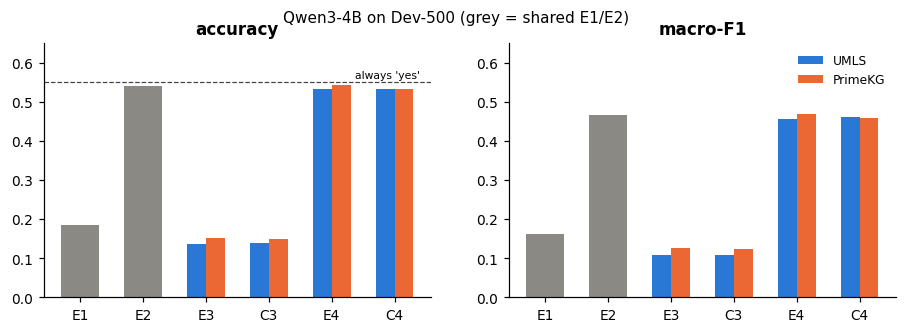

In [41]:
# Plot: accuracy and macro-F1 by condition
def plot_conditions(table, title, name):
    order = ["E1", "E2", "E3", "C3", "E4", "C4"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    for ax, metric in zip(axes, ["accuracy", "macro-F1"]):
        for i, cond in enumerate(order):
            if cond in ("E1", "E2"):
                ax.bar(i, table[table.condition == cond][metric].iloc[0], 0.6, color=GREY)
            else:
                for j, kg in enumerate(STUDY_KGS):
                    v = table[(table.condition == cond) & (table.KG == kg)][metric].iloc[0]
                    ax.bar(i - 0.15 + 0.3 * j, v, 0.3, color=KG_COLORS[kg], label=KG_NAMES[kg] if i == 2 else None)
        ax.set_xticks(range(6), order); ax.set_title(metric); ax.set_ylim(0, 0.65)
    axes[0].axhline(0.552, color="#444", lw=0.8, ls="--")
    axes[0].text(5.4, 0.56, "always 'yes'", ha="right", fontsize=7)
    axes[1].legend(frameon=False, fontsize=8)
    fig.suptitle(title, fontsize=10)
    save_fig(fig, name); plt.show()


if qwen_summary:
    plot_conditions(qwen_table, "Qwen3-4B on Dev-500 (grey = shared E1/E2)", "qwen_conditions")

**What we observed in our run** (your numbers should be the same or within a few answers; see the agreement table):

- The **abstract matters a lot**: E1 -> E2 raises accuracy from 0.184 to 0.540.
- Without the abstract the model answers "maybe" for most questions (420 of 500 in E1), which is why E1 is far
  *below* the 0.552 you would get by always saying "yes".
- **KG facts do not help.** E3 is *lower* than E1 for both KGs, and E4 is about the same as E2. E3 is about the
  same as C3, and E4 is about the same as C4: relevant facts do no better than irrelevant ones.

In [42]:
# The planned comparisons: difference = B - A in accuracy
def comparison_table(summary):
    return pd.DataFrame([{"family": r["family"], "comparison": r["comparison"], "acc diff": round(r["acc_diff"], 3),
                          "95% CI": f"{r['acc_diff_ci95'][0]:+.3f} to {r['acc_diff_ci95'][1]:+.3f}",
                          "macro-F1 diff": round(r["macro_f1_diff"], 3), "McNemar p": round(r["mcnemar_p"], 4),
                          "Holm p": None if r.get("p_holm") is None else round(r["p_holm"], 4)}
                         for r in summary["comparisons"]])


if qwen_summary:
    display(comparison_table(qwen_summary))

,family,comparison,acc diff,95% CI,macro-F1 diff,McNemar p,Holm p
0,positive_control,Abstract benefit: E1 -> E2,0.356,+0.306 to +0.406,0.306,0.0000,NaN
1,primary_umls,UMLS facts without abstract: E1 -> E3,-0.048,-0.070 to -0.026,-0.054,0.0000,0.0002
2,primary_umls,UMLS relevant vs control: C3 -> E3,-0.002,-0.010 to +0.006,-0.002,1.0000,1.0000
3,primary_umls,UMLS facts with abstract: E2 -> E4,-0.008,-0.024 to +0.008,-0.011,0.4545,1.0000
4,primary_umls,UMLS relevant vs control: C4 -> E4,0.000,-0.014 to +0.016,-0.005,1.0000,1.0000
5,secondary_primekg,PrimeKG facts without abstract: E1 -> E3,-0.032,-0.050 to -0.014,-0.035,0.0009,0.0034
6,secondary_primekg,PrimeKG relevant vs control: C3 -> E3,0.002,-0.004 to +0.008,0.002,1.0000,1.0000
7,secondary_primekg,PrimeKG facts with abstract: E2 -> E4,0.004,-0.014 to +0.022,0.001,0.8238,1.0000
8,secondary_primekg,PrimeKG relevant vs control: C4 -> E4,0.010,-0.002 to +0.022,0.011,0.2266,0.6797
9,kg_comparison,UMLS vs PrimeKG: E3,-0.016,-0.030 to -0.002,-0.019,0.0386,0.1543


**What we found (Qwen3-4B, Dev-500).**

- Abstract benefit (E1 -> E2): **+0.356** (95% CI +0.306 to +0.406).
- Facts without the abstract **lower** accuracy: E1 -> E3 is -0.048 for UMLS (Holm p < 0.001) and -0.032 for
  PrimeKG (Holm p = 0.003).
- But relevant and irrelevant facts do the same: E3 vs C3 is -0.002 (UMLS) and +0.002 (PrimeKG). So the drop is
  caused by *adding facts at all*, not by what they say.
- With the abstract, facts change nothing measurable: E2 -> E4 is -0.008 (UMLS) and +0.004 (PrimeKG), E4 vs C4 is
  0.000 and +0.010. All have Holm p >= 0.68.
- UMLS and PrimeKG do not differ significantly in any condition after correction.

A non-significant result is not proof that there is no effect. The confidence intervals rule out average gains
larger than about 0.8 (UMLS) and 2.2 (PrimeKG) accuracy points from adding facts to the abstract.

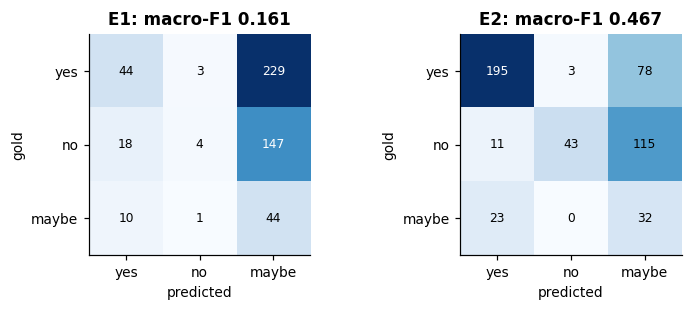

confusion matrices saved in /content/drive/MyDrive/BioMedicalQA_with_KG/biomedqa_results/llm/confusion_matrices


In [43]:
# Confusion matrices for every configuration (saved), plotted for E1 and E2
def confusion(rows):
    return np.array([[sum(1 for r in rows if r["gold"] == g and r["predicted"] == q) for q in LABELS + (None,)]
                     for g in LABELS])


for model_id, preds in LLM_PREDS.items():
    if model_id not in LLM_SUMMARY:
        continue
    for cfg in CONFIGS:
        mat = confusion(list(preds[cfg].values()))
        pd.DataFrame(mat, index=[f"gold_{l}" for l in LABELS], columns=[f"pred_{l}" for l in LABELS] + ["invalid"]) \
            .to_csv(R["confusion"] / f"{model_tag(model_id)}_{cfg.replace('/', '_')}.csv")
if qwen_summary:
    fig, axes = plt.subplots(1, 2, figsize=(7, 2.9))
    for ax, cond in zip(axes, ["E1", "E2"]):
        mat = confusion(list(LLM_PREDS[QWEN][cond].values()))[:, :3]
        ax.imshow(mat, cmap="Blues")
        for i in range(3):
            for j in range(3):
                ax.text(j, i, mat[i, j], ha="center", va="center", fontsize=8,
                        color="black" if mat[i, j] < mat.max() * 0.6 else "white")
        ax.set_xticks(range(3), LABELS); ax.set_yticks(range(3), LABELS)
        ax.set_xlabel("predicted"); ax.set_ylabel("gold")
        ax.set_title(f"{cond}: macro-F1 {qwen_summary['per_condition'][cond]['full']['macro_f1']:.3f}")
    fig.tight_layout(); save_fig(fig, "qwen_confusion_e1_e2"); plt.show()
print("confusion matrices saved in", R["confusion"])

**What we observe.** Without the abstract (E1) the model puts almost everything into "maybe" (420 of 500). With
the abstract (E2) it gets most "yes" questions right (195 of 276) and 32 of the 55 "maybe" questions, but it still
sends most "no" questions to "maybe" (115 of 169). The model is cautious: when it is unsure it says "maybe" rather
than "no". This "maybe" behaviour comes back in Section 13: adding facts mainly moves answers into or out of "maybe".

## 8.6 Dev-100 first look and consistency with Dev-400

We first ran everything on Dev-100 only. With 100 questions the confidence intervals are wide, which is why we did
not draw conclusions until the full development pool was done.

In [44]:
# Dev-100 subset and the Dev-100 vs Dev-400 consistency check
if qwen_summary:
    display(condition_table(qwen_summary, "dev_100")[["condition", "KG", "accuracy", "macro-F1"]])
    display(pd.DataFrame(qwen_summary["consistency"]))

,condition,KG,accuracy,macro-F1
0,E1,shared,0.16,0.140
1,E2,shared,0.56,0.485
2,E3,umls,0.13,0.096
3,C3,umls,0.14,0.107
4,E4,umls,0.55,0.478
5,C4,umls,0.54,0.472
6,E3,primekg,0.15,0.127
7,C3,primekg,0.15,0.127
8,E4,primekg,0.56,0.483
9,C4,primekg,0.54,0.472


,comparison,dev_100,dev_400,dev_500,consistent_direction_or_both_near_zero
0,Abstract benefit: E1 -> E2,0.40,0.3450,0.356,True
1,UMLS facts without abstract: E1 -> E3,-0.03,-0.0525,-0.048,True
2,UMLS relevant vs control: C3 -> E3,-0.01,0.0000,-0.002,True
3,UMLS facts with abstract: E2 -> E4,-0.01,-0.0075,-0.008,True
4,UMLS relevant vs control: C4 -> E4,0.01,-0.0025,0.000,True
5,PrimeKG facts without abstract: E1 -> E3,-0.01,-0.0375,-0.032,True
6,PrimeKG relevant vs control: C3 -> E3,0.00,0.0025,0.002,True
7,PrimeKG facts with abstract: E2 -> E4,0.00,0.0050,0.004,True
8,PrimeKG relevant vs control: C4 -> E4,0.02,0.0075,0.010,True
9,UMLS vs PrimeKG: E3,-0.02,-0.0150,-0.016,True


## 8.7 Second model: Phi-4-mini

The same questions, facts, controls, prompts, decoding and analysis code.

In [45]:
# Phi-4-mini: conditions and planned comparisons
if phi_summary:
    phi_table = condition_table(phi_summary)
    if qwen_summary:
        both = qwen_table[["condition", "KG", "accuracy", "macro-F1"]].rename(
            columns={"accuracy": "Qwen acc", "macro-F1": "Qwen macro-F1"})
        both["Phi acc"], both["Phi macro-F1"] = phi_table["accuracy"].values, phi_table["macro-F1"].values
        display(both)
    else:
        display(phi_table)
    display(comparison_table(phi_summary))
else:
    print("Phi-4-mini results are not available yet.")

,condition,KG,Qwen acc,Qwen macro-F1,Phi acc,Phi macro-F1
0,E1,shared,0.184,0.161,0.160,0.133
1,E2,shared,0.540,0.467,0.454,0.418
2,E3,umls,0.136,0.107,0.142,0.112
3,C3,umls,0.138,0.109,0.142,0.115
4,E4,umls,0.532,0.456,0.460,0.418
5,C4,umls,0.532,0.462,0.470,0.428
6,E3,primekg,0.152,0.126,0.140,0.113
7,C3,primekg,0.150,0.124,0.150,0.123
8,E4,primekg,0.544,0.468,0.456,0.419
9,C4,primekg,0.534,0.458,0.478,0.437


,family,comparison,acc diff,95% CI,macro-F1 diff,McNemar p,Holm p
0,positive_control,Abstract benefit: E1 -> E2,0.294,+0.248 to +0.338,0.285,0.0000,NaN
1,primary_umls,UMLS facts without abstract: E1 -> E3,-0.018,-0.036 to -0.002,-0.021,0.0636,0.2543
2,primary_umls,UMLS relevant vs control: C3 -> E3,0.000,-0.012 to +0.012,-0.002,1.0000,1.0000
3,primary_umls,UMLS facts with abstract: E2 -> E4,0.006,-0.010 to +0.024,-0.000,0.6291,1.0000
4,primary_umls,UMLS relevant vs control: C4 -> E4,-0.010,-0.024 to +0.004,-0.010,0.2668,0.8005
5,secondary_primekg,PrimeKG facts without abstract: E1 -> E3,-0.020,-0.036 to -0.006,-0.021,0.0129,0.0388
6,secondary_primekg,PrimeKG relevant vs control: C3 -> E3,-0.010,-0.020 to +0.000,-0.011,0.1250,0.2500
7,secondary_primekg,PrimeKG facts with abstract: E2 -> E4,0.002,-0.008 to +0.012,0.001,1.0000,1.0000
8,secondary_primekg,PrimeKG relevant vs control: C4 -> E4,-0.022,-0.036 to -0.010,-0.018,0.0010,0.0039
9,kg_comparison,UMLS vs PrimeKG: E3,0.002,-0.012 to +0.016,-0.000,1.0000,1.0000


**What we observed.** Phi-4-mini is weaker than Qwen (E2 accuracy 0.454 vs 0.540) but shows the same overall pattern:
a large abstract benefit (+0.294), a smaller drop when facts are added without the abstract (-0.018 for UMLS, not
significant after Holm; -0.020 for PrimeKG, Holm p = 0.039), and no benefit from relevant facts with the abstract
(E2 -> E4: +0.006 and +0.002). One difference: with PrimeKG, the *control* facts did better than the relevant facts
when the abstract was present (C4 0.478 vs E4 0.456, Holm p = 0.004). Section 13 shows that this comes from control
facts pushing some "maybe" answers to "yes", which cannot be a knowledge effect because those facts are irrelevant.

**Summary of the LLM study.** For two models and two KGs, KG facts never improved accuracy. Without the abstract
they made answers worse, and irrelevant facts did exactly the same.

# 9. Classical ML experiments

**Why.** An LLM might ignore facts given as text. We wanted to know whether KG information helps a model that must
use it as explicit features. If KG features gave no gain here either, the problem is more likely the knowledge itself.

**Data and features.** The same 500 development questions. Input text = question + " || " + abstract (no conclusion,
no labels, no MeSH terms). Three feature configurations:

| Config | Features |
|---|---|
| **A** | TF-IDF of question + abstract (word 1-2 grams, min_df 2, at most 5,000 terms, sublinear tf) |
| **B** | A + 18 UMLS features |
| **C** | A + 18 PrimeKG features |
| KGU / KGP | the 18 UMLS / PrimeKG features alone |

The 18 KG features are simple and identical for both KGs: number of linked entities in the question and the
abstract, question entities that reappear in the abstract, edges among linked entities (question-question and
question-abstract), relation counts by family (treat, contraindication, adverse, phenotype, gene, other), mean and max
log-degree, shared neighbours and the shortest question-abstract distance (capped at 3). A question without any linked
entity gets zeros, which means "no information", not "the answer is no".

Unlike the LLM facts, these features link **both the question and the abstract**, so for UMLS they use the
question+abstract-scoped graph (Section 4.2). PrimeKG uses its whole whitelisted graph.

**Models.** Logistic Regression, Random Forest (300 trees) and XGBoost (200 trees), all with class-balanced weights.

**Evaluation.** Repeated stratified 5-fold cross-validation with 3 repeats (15 outer folds, seed 42), identical folds
for every model and configuration. Small fixed hyperparameter grids were tuned with an inner 3-fold CV on macro-F1
(nested CV). TF-IDF and feature scaling are fitted inside each training fold only. In total 315 fold runs
(3 models x 5 configurations + 6 ablation configurations for Logistic Regression, 15 folds each).

**Statistics.** The primary comparisons are B - A and C - A in macro-F1 for each classifier (6 tests). Because
repeated-CV folds share training data, we used the Nadeau-Bengio corrected resampled t-test, with Holm correction
over the 6 tests.

In [46]:
# The 18 KG features
FAMILY = {  # display_relation -> family (both KGs)
    "indication": "treat", "off-label use": "treat", "may_treat": "treat", "may_prevent": "treat",
    "contraindication": "contra", "contraindicated_with_disease": "contra",
    "side effect": "adverse", "induces": "adverse",
    "phenotype present": "phenotype", "phenotype absent": "phenotype", "has_manifestation": "phenotype",
    "disease_has_finding": "phenotype", "disease_may_have_finding": "phenotype", "disease_excludes_finding": "phenotype",
    "associated with": "gene", "target": "gene", "enzyme": "gene", "transporter": "gene", "carrier": "gene",
    "disease_has_associated_gene": "gene",
    "linked to": "other", "may_diagnose": "other", "disease_may_have_associated_disease": "other",
}
FAMILIES = ("treat", "contra", "adverse", "phenotype", "gene", "other")
FEATURES = ["n_q_entities", "n_abs_entities", "n_unique_entities", "any_entity", "n_q_in_abs", "n_edges_within",
            "n_edges_qq", "n_edges_qa"] + [f"rel_{f}" for f in FAMILIES] + \
           ["mean_log_degree", "max_log_degree", "n_shared_neighbours", "qa_min_dist"]
GROUPS = {"entities": ["n_q_entities", "n_abs_entities", "n_unique_entities", "any_entity", "n_q_in_abs"],
          "relations": ["n_edges_within", "n_edges_qq", "n_edges_qa"] + [f"rel_{f}" for f in FAMILIES],
          "structure": ["mean_log_degree", "max_log_degree", "n_shared_neighbours", "qa_min_dist"]}


class KGFeaturizer:
    def __init__(self, edges, aliases=None):
        unknown = set(edges["display_relation"]) - set(FAMILY)
        if unknown:
            raise ValueError(f"relations without a family: {unknown}")
        self.linker = EntityLinker(node_table(edges), aliases)
        self.adj, self.pair_fams = defaultdict(set), defaultdict(set)
        for s, o, d in zip(edges["s_index"], edges["o_index"], edges["display_relation"]):
            s, o = int(s), int(o)
            if s == o:
                continue
            self.adj[s].add(o); self.adj[o].add(s)
            self.pair_fams[frozenset((s, o))].add(FAMILY[d])

    def _ids(self, text):
        return list(dict.fromkeys(m.node_index for m in self.linker.link(text)))

    def features(self, question, abstract):
        q, a = set(self._ids(question)), set(self._ids(abstract))
        u = q | a
        f = dict.fromkeys(FEATURES, 0.0)
        f.update(n_q_entities=len(q), n_abs_entities=len(a), n_unique_entities=len(u), any_entity=float(bool(u)),
                 n_q_in_abs=len(q & a), qa_min_dist=3.0)
        fam = defaultdict(int)
        for x, y in combinations(sorted(u), 2):
            fams = self.pair_fams.get(frozenset((x, y)))
            if fams:
                f["n_edges_within"] += 1
                f["n_edges_qq"] += x in q and y in q
                f["n_edges_qa"] += (x in q and y in a and y not in q) or (y in q and x in a and x not in q)
                for k in fams:
                    fam[k] += 1
        for k in FAMILIES:
            f[f"rel_{k}"] = float(fam[k])
        if u:
            degs = [math.log1p(len(self.adj.get(n, ()))) for n in u]
            f["mean_log_degree"], f["max_log_degree"] = sum(degs) / len(degs), max(degs)
            count = defaultdict(int)
            for n in u:
                for m in self.adj.get(n, ()):
                    if m not in u:
                        count[m] += 1
            f["n_shared_neighbours"] = float(sum(c >= 2 for c in count.values()))
        best = 3
        for x in q:
            for y in a:
                if x == y:
                    continue
                if y in self.adj.get(x, ()):
                    best = 1; break
                if best > 2 and self.adj.get(x, set()) & self.adj.get(y, set()):
                    best = 2
            if best == 1:
                break
        f["qa_min_dist"] = float(best)
        return {k: float(v) for k, v in f.items()}


REFERENCE_ML = json.loads(r"""{"fold_scores":{"logreg/A":{"r0f0":[0.384028,0.59],"r0f1":[0.424138,0.56],"r0f2":[0.399267,0.52],"r0f3":[0.326181,0.49],"r0f4":[0.31405,0.47],"r1f0":[0.435409,0.57],"r1f1":[0.365955,0.47],"r1f2":[0.404016,0.53],"r1f3":[0.366727,0.54],"r1f4":[0.389998,0.57],"r2f0":[0.446779,0.6],"r2f1":[0.423686,0.52],"r2f2":[0.407275,0.53],"r2f3":[0.32326,0.49],"r2f4":[0.344081,0.49]},"logreg/B-ent":{"r0f0":[0.361111,0.54],"r0f1":[0.409102,0.51],"r0f2":[0.419643,0.49],"r0f3":[0.35873,0.48],"r0f4":[0.319403,0.48],"r1f0":[0.443548,0.53],"r1f1":[0.332911,0.43],"r1f2":[0.432683,0.58],"r1f3":[0.4057,0.54],"r1f4":[0.387511,0.57],"r2f0":[0.468405,0.62],"r2f1":[0.343021,0.46],"r2f2":[0.380025,0.46],"r2f3":[0.413082,0.55],"r2f4":[0.347336,0.5]},"logreg/B-rel":{"r0f0":[0.372356,0.48],"r0f1":[0.410714,0.51],"r0f2":[0.419592,0.57],"r0f3":[0.388643,0.52],"r0f4":[0.313591,0.48],"r1f0":[0.425195,0.56],"r1f1":[0.349524,0.42],"r1f2":[0.413209,0.54],"r1f3":[0.410869,0.5],"r1f4":[0.413522,0.64],"r2f0":[0.458294,0.59],"r2f1":[0.353981,0.48],"r2f2":[0.397153,0.48],"r2f3":[0.331512,0.52],"r2f4":[0.3644,0.53]},"logreg/B-str":{"r0f0":[0.335185,0.36],"r0f1":[0.423291,0.48],"r0f2":[0.445503,0.55],"r0f3":[0.377217,0.51],"r0f4":[0.306397,0.44],"r1f0":[0.492477,0.6],"r1f1":[0.339154,0.45],"r1f2":[0.446905,0.54],"r1f3":[0.394444,0.53],"r1f4":[0.396954,0.58],"r2f0":[0.461785,0.6],"r2f1":[0.381481,0.52],"r2f2":[0.43059,0.52],"r2f3":[0.403195,0.54],"r2f4":[0.391831,0.51]},"logreg/B":{"r0f0":[0.355753,0.45],"r0f1":[0.429858,0.49],"r0f2":[0.42748,0.5],"r0f3":[0.324513,0.51],"r0f4":[0.326768,0.49],"r1f0":[0.4377,0.49],"r1f1":[0.322562,0.43],"r1f2":[0.395143,0.57],"r1f3":[0.424431,0.56],"r1f4":[0.369365,0.54],"r2f0":[0.483037,0.64],"r2f1":[0.321813,0.44],"r2f2":[0.403134,0.48],"r2f3":[0.393084,0.53],"r2f4":[0.374214,0.48]},"logreg/C-ent":{"r0f0":[0.380823,0.52],"r0f1":[0.385985,0.52],"r0f2":[0.395125,0.53],"r0f3":[0.341348,0.53],"r0f4":[0.322581,0.49],"r1f0":[0.409278,0.55],"r1f1":[0.3,0.42],"r1f2":[0.456175,0.6],"r1f3":[0.368056,0.55],"r1f4":[0.383892,0.57],"r2f0":[0.435183,0.6],"r2f1":[0.383718,0.51],"r2f2":[0.373048,0.57],"r2f3":[0.317091,0.47],"r2f4":[0.322132,0.46]},"logreg/C-rel":{"r0f0":[0.324203,0.5],"r0f1":[0.384737,0.54],"r0f2":[0.391147,0.52],"r0f3":[0.293548,0.45],"r0f4":[0.322002,0.49],"r1f0":[0.417122,0.56],"r1f1":[0.286031,0.45],"r1f2":[0.383342,0.58],"r1f3":[0.350265,0.53],"r1f4":[0.399471,0.59],"r2f0":[0.355565,0.49],"r2f1":[0.385748,0.52],"r2f2":[0.374185,0.54],"r2f3":[0.31875,0.51],"r2f4":[0.34281,0.51]},"logreg/C-str":{"r0f0":[0.375576,0.52],"r0f1":[0.432931,0.53],"r0f2":[0.396529,0.54],"r0f3":[0.319004,0.51],"r0f4":[0.329039,0.5],"r1f0":[0.411788,0.55],"r1f1":[0.29985,0.44],"r1f2":[0.448307,0.61],"r1f3":[0.357996,0.54],"r1f4":[0.373176,0.58],"r2f0":[0.443587,0.6],"r2f1":[0.350906,0.47],"r2f2":[0.3719,0.54],"r2f3":[0.356869,0.55],"r2f4":[0.357979,0.52]},"logreg/C":{"r0f0":[0.38432,0.52],"r0f1":[0.415067,0.56],"r0f2":[0.357568,0.48],"r0f3":[0.313705,0.5],"r0f4":[0.320703,0.49],"r1f0":[0.411788,0.55],"r1f1":[0.288102,0.42],"r1f2":[0.430613,0.58],"r1f3":[0.35262,0.53],"r1f4":[0.40625,0.61],"r2f0":[0.416162,0.54],"r2f1":[0.35522,0.47],"r2f2":[0.377481,0.57],"r2f3":[0.330862,0.53],"r2f4":[0.297218,0.43]},"logreg/KGP":{"r0f0":[0.222337,0.24],"r0f1":[0.305301,0.33],"r0f2":[0.240227,0.24],"r0f3":[0.270563,0.33],"r0f4":[0.168976,0.19],"r1f0":[0.221793,0.25],"r1f1":[0.168597,0.18],"r1f2":[0.233027,0.25],"r1f3":[0.26124,0.32],"r1f4":[0.22759,0.24],"r2f0":[0.179796,0.21],"r2f1":[0.227278,0.3],"r2f2":[0.298948,0.33],"r2f3":[0.19085,0.2],"r2f4":[0.282519,0.32]},"logreg/KGU":{"r0f0":[0.267252,0.29],"r0f1":[0.349254,0.37],"r0f2":[0.248182,0.26],"r0f3":[0.314416,0.36],"r0f4":[0.246838,0.29],"r1f0":[0.272588,0.29],"r1f1":[0.285601,0.31],"r1f2":[0.282574,0.3],"r1f3":[0.306955,0.33],"r1f4":[0.340111,0.37],"r2f0":[0.223234,0.24],"r2f1":[0.274633,0.3],"r2f2":[0.27374,0.28],"r2f3":[0.346406,0.35],"r2f4":[0.32738,0.35]},"rf/A":{"r0f0":[0.333629,0.57],"r0f1":[0.385337,0.61],"r0f2":[0.324173,0.55],"r0f3":[0.324543,0.57],"r0f4":[0.28729,0.51],"r1f0":[0.34321,0.56],"r1f1":[0.305664,0.55],"r1f2":[0.36108,0.58],"r1f3":[0.360544,0.59],"r1f4":[0.324719,0.57],"r2f0":[0.358366,0.6],"r2f1":[0.363889,0.61],"r2f2":[0.36489,0.61],"r2f3":[0.294785,0.55],"r2f4":[0.327485,0.53]},"rf/B":{"r0f0":[0.339212,0.58],"r0f1":[0.392014,0.63],"r0f2":[0.350216,0.57],"r0f3":[0.328901,0.56],"r0f4":[0.323549,0.55],"r1f0":[0.350617,0.56],"r1f1":[0.300926,0.54],"r1f2":[0.359808,0.59],"r1f3":[0.358366,0.6],"r1f4":[0.334033,0.57],"r2f0":[0.308284,0.58],"r2f1":[0.324173,0.55],"r2f2":[0.366135,0.6],"r2f3":[0.33455,0.57],"r2f4":[0.321217,0.53]},"rf/C":{"r0f0":[0.355012,0.58],"r0f1":[0.372265,0.6],"r0f2":[0.32004,0.58],"r0f3":[0.323549,0.55],"r0f4":[0.320386,0.54],"r1f0":[0.355012,0.58],"r1f1":[0.283955,0.55],"r1f2":[0.319048,0.54],"r1f3":[0.352912,0.59],"r1f4":[0.370863,0.61],"r2f0":[0.363028,0.61],"r2f1":[0.313588,0.53],"r2f2":[0.339815,0.58],"r2f3":[0.310396,0.56],"r2f4":[0.315875,0.52]},"rf/KGP":{"r0f0":[0.305815,0.38],"r0f1":[0.259722,0.31],"r0f2":[0.219508,0.3],"r0f3":[0.228395,0.35],"r0f4":[0.275181,0.38],"r1f0":[0.340078,0.42],"r1f1":[0.265562,0.29],"r1f2":[0.34149,0.4],"r1f3":[0.279716,0.45],"r1f4":[0.204621,0.28],"r2f0":[0.346065,0.48],"r2f1":[0.349306,0.5],"r2f2":[0.292063,0.36],"r2f3":[0.374528,0.42],"r2f4":[0.237716,0.38]},"rf/KGU":{"r0f0":[0.303548,0.44],"r0f1":[0.345271,0.51],"r0f2":[0.325844,0.38],"r0f3":[0.363783,0.47],"r0f4":[0.318085,0.41],"r1f0":[0.388007,0.5],"r1f1":[0.335597,0.5],"r1f2":[0.367365,0.55],"r1f3":[0.298589,0.49],"r1f4":[0.387004,0.52],"r2f0":[0.264055,0.33],"r2f1":[0.323117,0.46],"r2f2":[0.349495,0.46],"r2f3":[0.343786,0.52],"r2f4":[0.362908,0.43]},"xgb/A":{"r0f0":[0.376344,0.56],"r0f1":[0.375541,0.55],"r0f2":[0.38076,0.47],"r0f3":[0.30475,0.47],"r0f4":[0.436931,0.56],"r1f0":[0.369281,0.54],"r1f1":[0.386191,0.51],"r1f2":[0.427546,0.51],"r1f3":[0.470458,0.58],"r1f4":[0.343313,0.47],"r2f0":[0.320703,0.49],"r2f1":[0.380062,0.51],"r2f2":[0.308952,0.5],"r2f3":[0.371727,0.52],"r2f4":[0.345951,0.5]},"xgb/B":{"r0f0":[0.352078,0.55],"r0f1":[0.365079,0.54],"r0f2":[0.372027,0.5],"r0f3":[0.359447,0.49],"r0f4":[0.368801,0.53],"r1f0":[0.398899,0.58],"r1f1":[0.344428,0.52],"r1f2":[0.34629,0.44],"r1f3":[0.434636,0.58],"r1f4":[0.279935,0.45],"r2f0":[0.299419,0.47],"r2f1":[0.35817,0.53],"r2f2":[0.315789,0.51],"r2f3":[0.31875,0.51],"r2f4":[0.329345,0.49]},"xgb/C":{"r0f0":[0.348659,0.54],"r0f1":[0.359477,0.54],"r0f2":[0.39505,0.52],"r0f3":[0.378811,0.51],"r0f4":[0.418256,0.53],"r1f0":[0.389825,0.57],"r1f1":[0.332594,0.51],"r1f2":[0.350103,0.46],"r1f3":[0.381023,0.57],"r1f4":[0.326829,0.51],"r2f0":[0.311653,0.48],"r2f1":[0.340821,0.51],"r2f2":[0.332047,0.49],"r2f3":[0.36337,0.52],"r2f4":[0.336986,0.48]},"xgb/KGP":{"r0f0":[0.322298,0.36],"r0f1":[0.277802,0.34],"r0f2":[0.272217,0.31],"r0f3":[0.225152,0.32],"r0f4":[0.202525,0.27],"r1f0":[0.265278,0.36],"r1f1":[0.273201,0.3],"r1f2":[0.313791,0.44],"r1f3":[0.333774,0.45],"r1f4":[0.241889,0.27],"r2f0":[0.340432,0.48],"r2f1":[0.305978,0.43],"r2f2":[0.279567,0.3],"r2f3":[0.318937,0.37],"r2f4":[0.307994,0.36]},"xgb/KGU":{"r0f0":[0.386652,0.42],"r0f1":[0.250416,0.37],"r0f2":[0.266647,0.31],"r0f3":[0.36181,0.43],"r0f4":[0.353216,0.45],"r1f0":[0.353288,0.42],"r1f1":[0.294937,0.35],"r1f2":[0.442523,0.51],"r1f3":[0.307094,0.4],"r1f4":[0.398489,0.46],"r2f0":[0.295921,0.35],"r2f1":[0.322342,0.41],"r2f2":[0.284235,0.36],"r2f3":[0.331011,0.35],"r2f4":[0.389602,0.46]}},"feature_digest":{"umls":"4adf0d119dc75b54","primekg":"d2ff14a8ae0091eb"},"fold_membership_sha":"42d3f613ba8f950f","primary":{"logreg/B-A/macro_f1":[0.0022670066548316826,1.0],"logreg/C-A/macro_f1":[-0.019811314528715384,1.0],"rf/B-A/macro_f1":[0.002159696616586811,1.0],"rf/C-A/macro_f1":[-0.002924036693451663,1.0],"xgb/B-A/macro_f1":[-0.02369440480053932,1.0],"xgb/C-A/macro_f1":[-0.015533611097051552,1.0],"logreg/B-A/accuracy":[-0.02266666666666666,1.0],"logreg/C-A/accuracy":[-0.010666666666666661,1.0],"rf/B-A/accuracy":[0.0013333333333333346,1.0],"rf/C-A/accuracy":[-0.002666666666666662,1.0],"xgb/B-A/accuracy":[-0.003333333333333336,1.0],"xgb/C-A/accuracy":[-3.7007434154171884e-18,1.0]}}""")


def feature_digest(df):
    return hashlib.sha256(df.sort_index().round(9).to_csv().encode()).hexdigest()[:16]

In [47]:
# Build the feature table (about 2-4 minutes). UMLS features are saved in the private folder.
FEATURE_KGS = [kg for kg in ("umls", "primekg") if kg in STUDY_KGS]
ML_GRAPHS = {"primekg": (primekg_edges, None)}
if HAVE_UMLS:
    ML_GRAPHS["umls"] = (UMLS_GRAPHS["question_abstract"]["edges"], UMLS_GRAPHS["question_abstract"]["aliases"])
feature_tables = {}
for kg in FEATURE_KGS:
    path = (PRIVATE if kg == "umls" else R["classical_ml"]) / f"kg_features_{kg}.csv"
    meta_path = path.with_suffix(".settings.json")
    edges_, aliases_ = ML_GRAPHS[kg]
    feat_settings = {"edges": str(pd.util.hash_pandas_object(edges_, index=False).sum()),
                     "aliases": None if aliases_ is None else str(pd.util.hash_pandas_object(aliases_, index=False).sum()),
                     "questions_sha": hashlib.sha256(",".join(e.pmid for e in dev_pool).encode()).hexdigest()[:16]}
    if path.exists() and meta_path.exists() and load_json(meta_path) == feat_settings:   # same graph and questions
        feature_tables[kg] = pd.read_csv(path, dtype={"pmid": str}).set_index("pmid")
    else:
        t0 = time.time()
        fz = KGFeaturizer(*ML_GRAPHS[kg])
        feature_tables[kg] = pd.DataFrame({e.pmid: {f"{kg}_{k}": v for k, v in fz.features(e.question, e.abstract).items()}
                                           for e in dev_pool}).T.rename_axis("pmid")[[f"{kg}_{f}" for f in FEATURES]]
        feature_tables[kg].to_csv(path)
        save_json(feat_settings, meta_path)
        print(f"{KG_NAMES[kg]} features computed in {time.time() - t0:.0f} s")
    d = feature_digest(feature_tables[kg])
    print(f"{KG_NAMES[kg]}: questions with a linked entity {int((feature_tables[kg][f'{kg}_any_entity'] > 0).sum())}, "
          f"with an edge among linked entities {int((feature_tables[kg][f'{kg}_n_edges_within'] > 0).sum())} | "
          f"feature table identical to the original study: {d == REFERENCE_ML['feature_digest'][kg]}")

UMLS features computed in 5 s
UMLS: questions with a linked entity 456, with an edge among linked entities 33 | feature table identical to the original study: True
PrimeKG features computed in 6 s
PrimeKG: questions with a linked entity 354, with an edge among linked entities 48 | feature table identical to the original study: True


## 9.1 Cross-validation

The next cell runs the 315 fold runs (fewer without UMLS). It uses only the CPU and is the second most expensive step
of the notebook: about 75 minutes on a laptop CPU and **about 1.5-2.5 hours on a standard Colab CPU**; XGBoost is the
slowest model. Each fold is saved as one JSON file in `results/classical_ml/folds/` as soon as it is done, so the cell
can be stopped and re-run at any time. The folder stores the settings (folds, TF-IDF, seed, library versions and a hash of
each KG's feature table); fold files made with other settings are never mixed in.

In [48]:
# Cross-validation code
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
import sklearn, xgboost
from xgboost import XGBClassifier

ML_LABELS = ["yes", "no", "maybe"]
N_SPLITS, N_REPEATS = 5, 3
TFIDF = dict(ngram_range=(1, 2), min_df=2, max_features=5000, sublinear_tf=True, strip_accents="unicode")
MODELS = ("logreg", "rf", "xgb")
ML_CONFIGS = {"A": None, "B": "umls", "C": "primekg", "KGU": "umls_only", "KGP": "primekg_only"}
for _kg, _c in (("umls", "B"), ("primekg", "C")):           # feature-group ablation (logistic regression)
    for _g in ("entities", "relations", "structure"):
        ML_CONFIGS[f"{_c}-{_g[:3]}"] = f"{_kg}-minus-{_g}"


def ml_data():
    df = pd.DataFrame({"pmid": [e.pmid for e in dev_pool], "text": [e.question + " || " + e.abstract for e in dev_pool],
                       "y": [ML_LABELS.index(e.label) for e in dev_pool]}).set_index("pmid")
    assert not set(df.index) & test_pmids, "official test question in the data"
    for kg in FEATURE_KGS:
        df = df.join(feature_tables[kg].loc[df.index])
    return df, {kg: [f"{kg}_{f}" for f in FEATURES] for kg in FEATURE_KGS}


def ml_folds(df):
    rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
    return [{"repeat": i // N_SPLITS, "fold": i % N_SPLITS, "train": tr.tolist(), "test": te.tolist()}
            for i, (tr, te) in enumerate(rskf.split(np.zeros(len(df)), df["y"].values))]


def make_pipeline(model, config, kgcols):
    kg = ML_CONFIGS[config]
    parts = []
    if kg is None or not kg.endswith("_only"):
        parts.append(("tfidf", TfidfVectorizer(**TFIDF), "text"))
    if kg is not None:
        base = kg.replace("_only", "").split("-minus-")[0]
        cols = kgcols[base]
        if "-minus-" in kg:
            drop = {f"{base}_{f}" for f in GROUPS[kg.split("-minus-")[1]]}
            cols = [c for c in cols if c not in drop]
        parts.append(("kg", StandardScaler(), cols))
    pre = ColumnTransformer(parts)
    if model == "logreg":
        clf, grid = LogisticRegression(max_iter=5000, class_weight="balanced"), {"clf__C": [0.1, 1.0, 10.0]}
    elif model == "rf":
        clf = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
        grid = {"clf__max_depth": [None, 20], "clf__min_samples_leaf": [1, 3]}
    else:
        clf = XGBClassifier(objective="multi:softprob", n_estimators=200, learning_rate=0.1, tree_method="hist",
                            n_jobs=-1, random_state=SEED, eval_metric="mlogloss", verbosity=0)
        grid = {"clf__max_depth": [3, 6], "clf__reg_lambda": [1.0, 10.0]}
    return Pipeline([("pre", pre), ("clf", clf)]), grid


def _importance(pipe, model):
    """KG-feature importance inside the fitted pipeline (text terms summarised as one block)."""
    names = list(pipe.named_steps["pre"].get_feature_names_out())
    clf = pipe.named_steps["clf"]
    if model == "logreg":
        return {"type": "coef_per_class(yes,no,maybe)",
                "kg": {n: [round(float(c), 5) for c in clf.coef_[:, i]] for i, n in enumerate(names) if n.startswith("kg__")}}
    if model == "rf":
        imp = clf.feature_importances_
    else:
        g = clf.get_booster().get_score(importance_type="gain")
        imp = np.zeros(len(names))
        for k, v in g.items():
            imp[int(k[1:])] = v
        imp = imp / imp.sum() if imp.sum() else imp
    kg = {n: round(float(imp[i]), 6) for i, n in enumerate(names) if n.startswith("kg__")}
    text_total = float(sum(imp[i] for i, n in enumerate(names) if n.startswith("tfidf__")))
    return {"type": "impurity" if model == "rf" else "gain_normalised", "kg": kg, "text_total": round(text_total, 6)}


def run_fold(df, kgcols, model, config, f, out_dir):
    path = Path(out_dir) / f"{model}__{config}__r{f['repeat']}f{f['fold']}.json"
    if path.exists():
        return json.loads(path.read_text())
    t0 = time.time()
    tr, te = df.iloc[f["train"]], df.iloc[f["test"]]
    pipe, grid = make_pipeline(model, config, kgcols)
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED + 100 * f["repeat"] + f["fold"])
    gs = GridSearchCV(pipe, grid, scoring="f1_macro", cv=inner, n_jobs=1, refit=True)
    fit_params = {"clf__sample_weight": compute_sample_weight("balanced", tr["y"])} if model == "xgb" else {}
    gs.fit(tr, tr["y"], **fit_params)
    proba = gs.predict_proba(te)
    pred = proba.argmax(1)
    res = {"model": model, "config": config, "repeat": f["repeat"], "fold": f["fold"], "pmids": te.index.tolist(),
           "y": te["y"].tolist(), "pred": pred.tolist(), "proba": np.round(proba, 5).tolist(),
           "best_params": {k: (v if v is None or isinstance(v, (int, float, str)) else str(v)) for k, v in gs.best_params_.items()},
           "inner_best_macro_f1": round(float(gs.best_score_), 5), "seconds": round(time.time() - t0, 2),
           "importance": _importance(gs.best_estimator_, model)}
    tmp = path.with_suffix(".tmp"); tmp.write_text(json.dumps(res)); tmp.replace(path)
    return res

In [49]:
# Run the cross-validation (CPU; resumable). Set ML_TIME_BUDGET_MIN to stop after a number of minutes.
ML_TIME_BUDGET_MIN = None
df_ml, kgcols = ml_data()
FOLDS = ml_folds(df_ml)
fold_sha = hashlib.sha256(json.dumps({f"r{f['repeat']}f{f['fold']}": sorted(df_ml.index[f["test"]]) for f in FOLDS},
                                     sort_keys=True).encode()).hexdigest()[:16]
print("outer folds identical to the original study:", fold_sha == REFERENCE_ML["fold_membership_sha"])

base_cfgs = ["A"] + (["B", "KGU"] if "umls" in FEATURE_KGS else []) + ["C", "KGP"]
ablation = (["B-ent", "B-rel", "B-str"] if "umls" in FEATURE_KGS else []) + ["C-ent", "C-rel", "C-str"]
JOBS = [(m, c) for m in MODELS for c in base_cfgs] + [("logreg", c) for c in ablation]
ml_settings = {"folds": f"{N_SPLITS}x{N_REPEATS}", "fold_sha": fold_sha, "seed": SEED, "tfidf": TFIDF,
               "sklearn": sklearn.__version__, "xgboost": xgboost.__version__}
checkpoint_ok(R["ml_folds"], ml_settings)
check_parts(R["ml_folds"], {f"features_{kg}": feature_digest(feature_tables[kg]) for kg in FEATURE_KGS})
ml_settings["features_sha"] = {kg: feature_digest(feature_tables[kg]) for kg in FEATURE_KGS}

todo = [(m, c, f) for m, c in JOBS for f in FOLDS
        if not (R["ml_folds"] / f"{m}__{c}__r{f['repeat']}f{f['fold']}.json").exists()]
print(f"fold runs: {len(JOBS) * len(FOLDS)} in total, {len(todo)} still to do")
if todo and not RUN_CLASSICAL_ML:
    print("RUN_CLASSICAL_ML = False: the missing fold runs are skipped.")
elif todo:
    t0 = time.time()
    for k, (m, c, f) in enumerate(todo, 1):
        if ML_TIME_BUDGET_MIN and time.time() - t0 > ML_TIME_BUDGET_MIN * 60:
            print("time budget reached; run this cell again to continue"); break
        r = run_fold(df_ml, kgcols, m, c, f, R["ml_folds"])
        if k % 15 == 0 or k == len(todo):
            el = time.time() - t0
            print(f"   {k}/{len(todo)} done ({m} {c}), {el / 60:.0f} min so far, about {el / k * (len(todo) - k) / 60:.0f} min left")

outer folds identical to the original study: True
fold runs: 315 in total, 315 still to do
   15/315 done (logreg A), 2 min so far, about 31 min left
   30/315 done (logreg B), 5 min so far, about 44 min left
   45/315 done (logreg KGU), 5 min so far, about 28 min left
   60/315 done (logreg C), 8 min so far, about 35 min left
   75/315 done (logreg KGP), 8 min so far, about 26 min left
   90/315 done (rf A), 14 min so far, about 36 min left
   105/315 done (rf B), 21 min so far, about 41 min left
   120/315 done (rf KGU), 25 min so far, about 40 min left
   135/315 done (rf C), 31 min so far, about 41 min left
   150/315 done (rf KGP), 35 min so far, about 38 min left
   165/315 done (xgb A), 60 min so far, about 55 min left
   180/315 done (xgb B), 86 min so far, about 64 min left
   195/315 done (xgb KGU), 86 min so far, about 53 min left
   210/315 done (xgb C), 112 min so far, about 56 min left
   225/315 done (xgb KGP), 113 min so far, about 45 min left
   240/315 done (logreg B-

In [50]:
# Statistics for the fold runs
def _m(y, p):
    pr, rc, f1, sup = precision_recall_fscore_support(y, p, labels=[0, 1, 2], zero_division=0)
    return {"accuracy": accuracy_score(y, p), "macro_f1": f1_score(y, p, labels=[0, 1, 2], average="macro", zero_division=0),
            "per_class": {ML_LABELS[i]: {"precision": pr[i], "recall": rc[i], "f1": f1[i], "support": int(sup[i])} for i in range(3)},
            "confusion": confusion_matrix(y, p, labels=[0, 1, 2]).tolist(),
            "pred_dist": {ML_LABELS[i]: int((np.asarray(p) == i).sum()) for i in range(3)}}


def load_runs(run_dir):
    runs = defaultdict(dict)
    for p in glob.glob(str(Path(run_dir) / "*.json")):
        if Path(p).name.startswith("_"):
            continue
        r = json.loads(Path(p).read_text())
        runs[(r["model"], r["config"])][(r["repeat"], r["fold"])] = r
    return runs


def summarise(runs):
    out = {}
    for key, folds in runs.items():
        if len(folds) != N_SPLITS * N_REPEATS:
            continue
        fm = [_m(r["y"], r["pred"]) for r in folds.values()]
        reps = []
        for rep in range(N_REPEATS):
            y = sum((folds[(rep, f)]["y"] for f in range(N_SPLITS)), [])
            p = sum((folds[(rep, f)]["pred"] for f in range(N_SPLITS)), [])
            reps.append(_m(y, p))
        out[key] = {"folds": len(folds),
                    "fold_accuracy_mean": float(np.mean([x["accuracy"] for x in fm])), "fold_accuracy_sd": float(np.std([x["accuracy"] for x in fm], ddof=1)),
                    "fold_macro_f1_mean": float(np.mean([x["macro_f1"] for x in fm])), "fold_macro_f1_sd": float(np.std([x["macro_f1"] for x in fm], ddof=1)),
                    "repeat_accuracy": [x["accuracy"] for x in reps], "repeat_macro_f1": [x["macro_f1"] for x in reps],
                    "per_class_mean": {l: {k: float(np.mean([x["per_class"][l][k] for x in reps])) for k in ("precision", "recall", "f1")} for l in ML_LABELS},
                    "confusion_sum_over_repeats": np.sum([x["confusion"] for x in reps], axis=0).tolist(),
                    "pred_dist_mean": {l: float(np.mean([x["pred_dist"][l] for x in reps])) for l in ML_LABELS},
                    "best_params": [folds[k]["best_params"] for k in sorted(folds)],
                    "seconds_total": float(sum(r["seconds"] for r in folds.values()))}
    return out


def corrected_t(diffs, ratio=1 / (N_SPLITS - 1)):
    """Nadeau-Bengio corrected resampled t-test: variance x (1/k + n_test/n_train), df = k - 1."""
    d = np.asarray(diffs, float); k = len(d); mean = d.mean(); var = d.var(ddof=1)
    se = math.sqrt((1 / k + ratio) * var) if var > 0 else 0.0
    if se == 0:
        return mean, (mean, mean), 1.0 if mean == 0 else 0.0
    t = mean / se; p = 2 * stats.t.sf(abs(t), k - 1); h = stats.t.ppf(0.975, k - 1) * se
    return mean, (mean - h, mean + h), p


def ml_compare(runs, model, a, b, metric):
    fa, fb = runs[(model, a)], runs[(model, b)]
    vals = [_m(fb[k]["y"], fb[k]["pred"])[metric] - _m(fa[k]["y"], fa[k]["pred"])[metric] for k in sorted(set(fa) & set(fb))]
    mean, ci, p = corrected_t(vals)
    return {"model": model, "A": a, "B": b, "metric": metric, "k": len(vals), "diff_mean": mean, "ci95": list(ci), "p": p,
            "folds_better": int(sum(v > 0 for v in vals)), "folds_worse": int(sum(v < 0 for v in vals))}


def per_question_correct(runs, model, config):
    acc = defaultdict(list)
    for r in runs[(model, config)].values():
        for pm, y, p in zip(r["pmids"], r["y"], r["pred"]):
            acc[pm].append(int(y == p))
    return {k: float(np.mean(v)) for k, v in acc.items()}


def importance_tables(runs):
    rows = []
    for (model, config), folds in runs.items():
        if config not in ("B", "C"):
            continue
        agg, text = defaultdict(list), []
        for r in folds.values():
            for n, v in r["importance"]["kg"].items():
                agg[n].append(np.abs(v).mean() if isinstance(v, list) else v)
            if "text_total" in r["importance"]:
                text.append(r["importance"]["text_total"])
        kg_total = float(np.mean([sum(np.abs(np.asarray(v)).mean() if isinstance(v, list) else v for v in r["importance"]["kg"].values())
                                  for r in folds.values()])) if model != "logreg" else None
        for n, v in agg.items():
            rows.append({"model": model, "config": config, "feature": n.replace("kg__", ""), "importance_mean": float(np.mean(v)),
                         "importance_sd": float(np.std(v)), "kind": next(iter(folds.values()))["importance"]["type"],
                         "kg_block_share": kg_total, "text_block_share": float(np.mean(text)) if text else None})
    return pd.DataFrame(rows)

In [51]:
# Summaries, primary comparisons and the saved result tables
runs = load_runs(R["ml_folds"])
ml_summary = summarise(runs)
print("complete model/config pairs:", len(ml_summary), "| fold runs loaded:", sum(len(v) for v in runs.values()))

fold_rows = []
for (model, config), folds in sorted(runs.items()):
    for (rep, fo), r in sorted(folds.items()):
        m = _m(r["y"], r["pred"])
        ref = REFERENCE_ML["fold_scores"].get(f"{model}/{config}", {}).get(f"r{rep}f{fo}")
        fold_rows.append({"model": model, "config": config, "repeat": rep, "fold": fo, "macro_f1": m["macro_f1"],
                          "accuracy": m["accuracy"], "best_params": json.dumps(r["best_params"]), "seconds": r["seconds"],
                          "original_macro_f1": ref[0] if ref else None})
fold_df = pd.DataFrame(fold_rows)
fold_df.to_csv(R["classical_ml"] / "fold_results.csv", index=False)
if len(fold_df):
    same = (fold_df["macro_f1"].round(6) == fold_df["original_macro_f1"]).sum()
    print(f"fold runs with exactly the original macro-F1: {same}/{len(fold_df)}")

names = {"A": "A text", "B": "B text+UMLS", "C": "C text+PrimeKG", "KGU": "UMLS only", "KGP": "PrimeKG only"}
ml_table = pd.DataFrame([{"model": model, "config": names[config], "macro-F1": round(s["fold_macro_f1_mean"], 3),
                          "SD": round(s["fold_macro_f1_sd"], 3), "accuracy": round(s["fold_accuracy_mean"], 3),
                          "F1 yes/no/maybe": "/".join(f"{s['per_class_mean'][l]['f1']:.2f}" for l in ML_LABELS),
                          "predicted yes/no/maybe": "/".join(f"{s['pred_dist_mean'][l]:.0f}" for l in ML_LABELS)}
                         for (model, config), s in sorted(ml_summary.items()) if config in names])
display(ml_table)

prim = []
for metric in ("macro_f1", "accuracy"):
    rows = [ml_compare(runs, model, "A", b, metric) for model in MODELS for b in ("B", "C")
            if (model, "A") in ml_summary and (model, b) in ml_summary]
    for r, p in zip(rows, holm([r["p"] for r in rows])):
        r["p_holm"] = p
    prim += rows
comp_rows = [{**r, "ci95_low": r["ci95"][0], "ci95_high": r["ci95"][1], "family": "primary"} for r in prim]
for model in MODELS:
    if (model, "B") in ml_summary and (model, "C") in ml_summary:
        r = ml_compare(runs, model, "B", "C", "macro_f1")
        comp_rows.append({**r, "ci95_low": r["ci95"][0], "ci95_high": r["ci95"][1], "family": "exploratory: UMLS vs PrimeKG (C - B)"})
pd.DataFrame(comp_rows).drop(columns=["ci95"], errors="ignore").to_csv(R["classical_ml"] / "model_comparison.csv", index=False)
pd.DataFrame([{"model": m, "config": c, "macro_f1_mean": v["fold_macro_f1_mean"], "macro_f1_sd": v["fold_macro_f1_sd"],
               "accuracy_mean": v["fold_accuracy_mean"], "accuracy_sd": v["fold_accuracy_sd"],
               **{f"{l}_f1": v["per_class_mean"][l]["f1"] for l in ML_LABELS},
               **{f"pred_{l}": v["pred_dist_mean"][l] for l in ML_LABELS}}
              for (m, c), v in sorted(ml_summary.items())]).to_csv(R["classical_ml"] / "summary_by_model_and_config.csv", index=False)

prim_table = pd.DataFrame([{"model": r["model"], "comparison": f"{r['B']} - A", "diff": round(r["diff_mean"], 4),
                            "95% CI": f"{r['ci95'][0]:+.3f} to {r['ci95'][1]:+.3f}", "p": round(r["p"], 3),
                            "Holm p": round(r["p_holm"], 3), "folds better/worse": f"{r['folds_better']}/{r['folds_worse']}",
                            "original diff": round(REFERENCE_ML["primary"].get(f"{r['model']}/{r['B']}-A/macro_f1", [np.nan])[0], 4)}
                           for r in prim if r["metric"] == "macro_f1"])
print("Primary comparisons (macro-F1, corrected resampled t-test, Holm over the comparisons that could be run):")
display(prim_table)

complete model/config pairs: 21 | fold runs loaded: 315
fold runs with exactly the original macro-F1: 126/315


,model,config,macro-F1,SD,accuracy,F1 yes/no/maybe,predicted yes/no/maybe
0,logreg,A text,0.382,0.042,0.527,0.64/0.43/0.08,314/167/19
1,logreg,B text+UMLS,0.385,0.054,0.505,0.61/0.42/0.14,299/173/28
2,logreg,C text+PrimeKG,0.369,0.045,0.524,0.64/0.40/0.08,337/148/14
3,logreg,PrimeKG only,0.233,0.044,0.262,0.30/0.31/0.12,134/183/183
4,logreg,UMLS only,0.291,0.039,0.313,0.41/0.28/0.19,157/147/195
5,rf,A text,0.343,0.027,0.574,0.71/0.32/0.00,425/75/0
6,rf,B text+UMLS,0.334,0.037,0.568,0.70/0.30/0.00,429/71/0
7,rf,C text+PrimeKG,0.336,0.026,0.567,0.70/0.31/0.00,429/71/0
8,rf,PrimeKG only,0.288,0.053,0.380,0.49/0.30/0.10,264/164/72
9,rf,UMLS only,0.338,0.034,0.465,0.59/0.35/0.09,312/135/53


Primary comparisons (macro-F1, corrected resampled t-test, Holm over the comparisons that could be run):


,model,comparison,diff,95% CI,p,Holm p,folds better/worse,original diff
0,logreg,B - A,0.0032,-0.050 to +0.056,0.900,1.0,7/8,0.0023
1,logreg,C - A,-0.0130,-0.053 to +0.027,0.495,1.0,6/9,-0.0198
2,rf,B - A,-0.0084,-0.045 to +0.029,0.634,1.0,7/7,0.0022
3,rf,C - A,-0.0063,-0.037 to +0.025,0.672,1.0,5/10,-0.0029
4,xgb,B - A,0.0153,-0.025 to +0.055,0.425,1.0,9/6,-0.0237
5,xgb,C - A,0.0075,-0.023 to +0.038,0.603,1.0,11/4,-0.0155


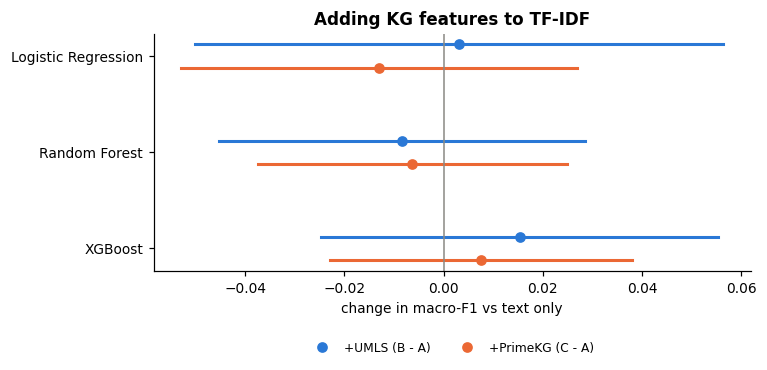

In [52]:
# Plot: change in macro-F1 from adding KG features (mean of 15 folds, corrected 95% CI)
pm = [r for r in prim if r["metric"] == "macro_f1"]
if pm:
    fig, ax = plt.subplots(figsize=(7, 2.8))
    for i, model in enumerate(MODELS):
        for off, b, kg in ((-0.12, "B", "umls"), (0.12, "C", "primekg")):
            r = next((x for x in pm if x["model"] == model and x["B"] == b), None)
            if r is None:
                continue
            ax.plot(r["ci95"], [i + off] * 2, color=KG_COLORS[kg], lw=2)
            ax.plot(r["diff_mean"], i + off, "o", color=KG_COLORS[kg], label=f"+{KG_NAMES[kg]} ({b} - A)" if i == 0 else None)
    ax.axvline(0, color=GREY, lw=1)
    ax.set_yticks(range(3), ["Logistic Regression", "Random Forest", "XGBoost"]); ax.invert_yaxis()
    ax.set_xlabel("change in macro-F1 vs text only"); ax.set_title("Adding KG features to TF-IDF")
    ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
    save_fig(fig, "ml_kg_effect"); plt.show()

**What we found.** No KG configuration improved any classifier. The changes in macro-F1 are between -0.024 and
+0.002, every confidence interval includes zero, and all Holm-adjusted p-values are 1.00. Logistic Regression was the
best text model (macro-F1 0.384); Random Forest had the best accuracy (0.571) but never predicted "maybe", which is why
its macro-F1 is low (0.337).

The KG features alone carry very little signal: UMLS-only reaches macro-F1 0.29-0.34 and PrimeKG-only 0.23-0.29,
around the 0.333 you would get by guessing in proportion to the labels.

In [53]:
# Feature-group ablation (Logistic Regression), feature importance and coverage subgroups
abl_names = {"B": "B (all UMLS)", "B-ent": "B without entity counts", "B-rel": "B without relation counts",
             "B-str": "B without structure", "C": "C (all PrimeKG)", "C-ent": "C without entity counts",
             "C-rel": "C without relation counts", "C-str": "C without structure"}
display(pd.DataFrame([{"config": v, "macro-F1": round(ml_summary[("logreg", k)]["fold_macro_f1_mean"], 3),
                       "accuracy": round(ml_summary[("logreg", k)]["fold_accuracy_mean"], 3)}
                      for k, v in abl_names.items() if ("logreg", k) in ml_summary]))

imp = importance_tables(runs)
imp.to_csv(R["classical_ml"] / "feature_importance.csv", index=False)
for (model, config), g in (imp.groupby(["model", "config"]) if len(imp) else []):
    top = g.sort_values("importance_mean", ascending=False).head(4)
    share = g["kg_block_share"].iloc[0]
    share_text = f"KG share of importance {share:.3f}" if share == share and share is not None else "LR: |standardised coefficient|"
    print(f"{model:6s} {config}: {share_text}; top KG features: {list(top.feature)}")

cov = []
for model in MODELS:
    for b, kg in (("B", "umls"), ("C", "primekg")):
        if (model, "A") not in ml_summary or (model, b) not in ml_summary:
            continue
        feats = feature_tables[kg]
        ca, cb = per_question_correct(runs, model, "A"), per_question_correct(runs, model, b)
        for name, mask in (("question entity linked", feats[f"{kg}_n_q_entities"] > 0),
                           ("no question entity", feats[f"{kg}_n_q_entities"] == 0),
                           ("any KG edge among linked entities", feats[f"{kg}_n_edges_within"] > 0),
                           ("no KG edge", feats[f"{kg}_n_edges_within"] == 0)):
            ids = [p for p in feats.index[mask] if p in ca]
            if ids:
                cov.append({"model": model, "kg": kg, "group": name, "n": len(ids),
                            "acc_A": float(np.mean([ca[i] for i in ids])), "acc_KG": float(np.mean([cb[i] for i in ids])),
                            "diff": float(np.mean([cb[i] - ca[i] for i in ids]))})
cov_df = pd.DataFrame(cov)
cov_df.to_csv(R["classical_ml"] / "coverage_groups.csv", index=False)
display(cov_df.round(3))
save_json({"summary": {f"{m}/{c}": v for (m, c), v in ml_summary.items()}, "primary": prim, "coverage_groups": cov,
           "settings": ml_settings}, R["classical_ml"] / "ml_results.json")

,config,macro-F1,accuracy
0,B (all UMLS),0.385,0.505
1,B without entity counts,0.391,0.519
2,B without relation counts,0.380,0.513
3,B without structure,0.405,0.521
4,C (all PrimeKG),0.369,0.524
5,C without entity counts,0.376,0.529
6,C without relation counts,0.356,0.519
7,C without structure,0.375,0.534


logreg B: LR: |standardised coefficient|; top KG features: ['umls_n_edges_qa', 'umls_n_shared_neighbours', 'umls_rel_treat', 'umls_n_edges_within']
logreg C: LR: |standardised coefficient|; top KG features: ['primekg_rel_adverse', 'primekg_n_q_entities', 'primekg_rel_treat', 'primekg_max_log_degree']
rf     B: KG share of importance 0.027; top KG features: ['umls_mean_log_degree', 'umls_max_log_degree', 'umls_n_unique_entities', 'umls_n_abs_entities']
rf     C: KG share of importance 0.021; top KG features: ['primekg_mean_log_degree', 'primekg_max_log_degree', 'primekg_n_shared_neighbours', 'primekg_n_abs_entities']
xgb    B: KG share of importance 0.012; top KG features: ['umls_max_log_degree', 'umls_n_unique_entities', 'umls_n_abs_entities', 'umls_mean_log_degree']
xgb    C: KG share of importance 0.009; top KG features: ['primekg_n_abs_entities', 'primekg_n_shared_neighbours', 'primekg_mean_log_degree', 'primekg_max_log_degree']


,model,kg,group,n,acc_A,acc_KG,diff
0,logreg,umls,question entity linked,291,0.537,0.518,-0.019
1,logreg,umls,no question entity,209,0.512,0.486,-0.026
2,logreg,umls,any KG edge among linked entities,33,0.596,0.586,-0.010
3,logreg,umls,no KG edge,467,0.522,0.499,-0.023
4,logreg,primekg,question entity linked,203,0.558,0.542,-0.016
5,logreg,primekg,no question entity,297,0.505,0.512,0.007
6,logreg,primekg,any KG edge among linked entities,48,0.465,0.417,-0.049
7,logreg,primekg,no KG edge,452,0.533,0.535,0.002
8,rf,umls,question entity linked,291,0.575,0.574,-0.001
9,rf,umls,no question entity,209,0.573,0.560,-0.013


**What we learned from classical ML.**

- In Random Forest and XGBoost the KG features receive only 1-3% of the total importance. The top ones are entity
  degree and entity counts, which describe *how many and how general* the linked terms are rather than medical
  relations.
- Removing any one group of KG features changes Logistic Regression macro-F1 by at most 0.016, so no group is needed.
- Questions with linked entities or KG edges do not do better with KG features (subgroup table). More coverage did
  not mean more useful information.

This is the same message as the LLM study, from a very different kind of model: the KG content we could retrieve
does not carry information about the answers beyond what the abstract already says.

# 10. Evaluation metrics

These are the metrics we computed (`compute_metrics` in Section 8 for the LLM study, scikit-learn metrics for
classical ML).

| Metric | How we computed it | Why |
|---|---|---|
| **Accuracy** | correct / all questions; an invalid reply counts as wrong | easy to read; comparable with other PubMedQA work |
| **Precision, recall, F1 per class** | for yes, no and maybe separately | shows which classes the model handles |
| **Macro-F1** | average of the three per-class F1 scores | treats the rare "maybe" class (11%) as important as "yes" (55%) |
| **Confusion matrix** | gold x predicted counts | shows where errors go (for us: into "maybe") |
| **Predicted label distribution** | counts of yes/no/maybe | detects answer bias |
| **Paired comparison** | same questions in both conditions; difference of accuracy | removes the variation between questions |
| **Exact McNemar test** (LLM) | binomial test on questions correct in only one of the two conditions | standard test for two paired classifiers |
| **Paired bootstrap 95% CI** (LLM) | 2,000 resamples of questions, seed 42 | uncertainty of the difference |
| **Holm correction** | within each planned family of tests | we ran several tests; this controls false positives |
| **Corrected resampled t-test** (ML) | Nadeau-Bengio correction for overlapping CV training sets, 15 folds | normal t-tests are too optimistic in repeated CV |
| **Exact sign test** (Section 13) | fixed vs broken answers among changed predictions | exploratory, uncorrected |

**Why macro-F1 matters here.** Because 55% of the answers are "yes", a model that always says "yes" gets 0.552
accuracy but a macro-F1 of only 0.237 (F1 0.711 for yes, 0 for no and maybe). Random Forest is a real example:
the best accuracy of all classical models, but zero F1 on "maybe". Macro-F1 exposes this.

In [54]:
# The metric code on a tiny example
gold = ["yes", "yes", "no", "maybe", "no", "yes"]
pred = ["yes", "maybe", "no", "maybe", "yes", "yes"]
m = compute_metrics(gold, pred)
print("accuracy", round(m["accuracy"], 3), "| macro-F1", round(m["macro_f1"], 3))
print({k: {kk: round(vv, 2) for kk, vv in v.items()} for k, v in m["per_class"].items()})
print("always 'yes' on the dev pool -> macro-F1", round(compute_metrics(
    [e.label for e in dev_pool], ["yes"] * len(dev_pool))["macro_f1"], 3))
print("McNemar p if 5 questions are correct only in A and 15 only in B:", round(mcnemar_exact(5, 15), 4))

accuracy 0.667 | macro-F1 0.667
{'yes': {'precision': 0.67, 'recall': 0.67, 'f1': 0.67, 'support': 3}, 'no': {'precision': 1.0, 'recall': 0.5, 'f1': 0.67, 'support': 2}, 'maybe': {'precision': 0.5, 'recall': 1.0, 'f1': 0.67, 'support': 1}}
always 'yes' on the dev pool -> macro-F1 0.237
McNemar p if 5 questions are correct only in A and 15 only in B: 0.0414


# 11. Preliminary KG Relevance Audit (AI-assisted)

**Why we did this.** After finding no benefit (Sections 8-9), we wanted to know *why*. There are four possible
bottlenecks:

| | Bottleneck | Meaning |
|---|---|---|
| **A** | KG content | the needed relationships are not in the graph |
| **B** | Entity linking | the right concepts are not identified in the question |
| **C** | Retrieval | useful relationships exist, but the retriever does not pick them |
| **D** | Model utilisation | relevant facts are given, but the model does not use them |

The simplest way to separate them is to look at the facts the model actually received and judge whether they could
help answer the question.

**Important: this audit is preliminary.** All relevance judgements were made by an AI annotator (Claude) following
written guidelines. They have **not** been validated by a biomedical expert or a second human annotator. We decided
not to run a human annotation, so there is **no agreement or reliability statistic** in this notebook. The
annotations are research data: they are embedded in this notebook (UMLS facts only by a short hash of their text)
and cannot be recomputed by code. Everything else in this section (the sample, the sheet, the statistics) is
recomputed here. Human validation is future work; Section 11.6 contains the code to analyse it.

**Sample.** 50 of the 500 development questions, drawn with seed 42 in four strata: questions with an ambiguous
entity link (10), with many facts (15), with few facts (15) and with no facts (10), with fixed label quotas that
oversample "maybe" (20 yes / 18 no / 12 maybe). Model predictions were never used to choose questions. The annotation
sheets contained no gold labels, conclusions or predictions; gold labels are joined only afterwards for the by-label
tables. The audited facts are exactly the E3/E4 facts the model saw.

**Categories** (each fact gets one; entity-link correctness and factual correctness were recorded separately):

| Code | Category | Meaning |
|---|---|---|
| 1 | Directly relevant | speaks to the relationship the question asks about; could move the answer between yes/no/maybe |
| 2a | Indirectly relevant, same topic | true and on the question's topic, but does not bear on the claim |
| 2b | Indirectly relevant, generic | shares only the concept (e.g. an arbitrary drug with that side effect) |
| 3 | Redundant | already in the question/abstract or implied by the concept name |
| 4 | Incorrect entity link | the fact belongs to a wrongly linked concept |
| 5 | Incorrect or misleading relationship | link fine, but the fact is wrong or misleading for this question |
| 6 | Cannot determine | not enough information to judge |

## 11.1 The sample

In [55]:
# Sampling design: strata, label quotas, seed 42 (selection never uses model predictions)
REFERENCE_DIAG = json.loads(r"""{"sample_pmids":["10757151","11247896","11413427","11838307","11882828","12607120","14992556","15369037","15475728","15477551","15703931","16991071","17179167","17244100","17489316","17502203","17562682","18403944","19299238","19406119","19643525","19931500","20130378","20304513","20353735","20594006","21457946","21569408","21873082","21880023","22301406","22303473","22427593","22706226","23096188","23228527","23598835","23792130","24434052","24606627","24793469","24827404","25155638","25489696","25636371","25987398","26452334","26717802","27146470","28006766"],"sample_by_stratum":{"MANY":15,"FEW":15,"AMB":10,"NONE":10},"audit":{"primekg":{"pct":{"directly relevant":0.6,"indirectly relevant":89.1,"redundant":1.9,"incorrect entity link":0.0,"incorrect/misleading relationship":8.3,"cannot determine":0.0},"pct_2a_2b":{"2a":3.8,"2b":85.3},"design_weighted_pct":{"directly relevant":0.8,"indirectly relevant":87.1,"redundant":0.8,"incorrect entity link":0.0,"incorrect/misleading relationship":11.3,"cannot determine":0.0},"facts":156,"mention_link_pct":{"correct":83.7,"partial":16.3}},"umls":{"pct":{"directly relevant":0.0,"indirectly relevant":77.5,"redundant":13.1,"incorrect entity link":5.2,"incorrect/misleading relationship":4.2,"cannot determine":0.0},"pct_2a_2b":{"2a":12.7,"2b":64.8},"design_weighted_pct":{"directly relevant":0.0,"indirectly relevant":81.9,"redundant":11.9,"incorrect entity link":3.2,"incorrect/misleading relationship":3.1,"cannot determine":0.0},"facts":213,"mention_link_pct":{"correct":81.0,"partial":11.1,"incorrect":6.3,"unsure":1.6}}},"missed_concepts":{"primekg":{"in_question":{"A: no exact match in KG":73,"B: in KG with usable edges, not linked":25},"abstract_or_background_only":{"A: no exact match in KG":9,"B: in KG with usable edges, not linked":5}},"umls":{"in_question":{"A: in vocabulary, no whitelisted relations":56,"B: in KG with usable edges, not linked":23,"A: no exact match in KG":2},"abstract_or_background_only":{"B: in KG with usable edges, not linked":10,"A: in vocabulary, no whitelisted relations":4}}},"strategies":{"primekg/R1":{"facts":156,"questions_with_facts":33,"categories":{"1":1,"2":139,"3":3,"5":13},"link_correct":{"correct":128,"partial":28},"questions_with_direct_fact":1,"new_vs_R1":0},"primekg/R1p":{"facts":156,"questions_with_facts":33,"categories":{"1":2,"2":136,"3":4,"5":14},"link_correct":{"correct":128,"partial":28},"questions_with_direct_fact":1,"new_vs_R1":5},"primekg/R2":{"facts":8,"questions_with_facts":5,"categories":{"1":2,"2":2,"3":2,"5":2},"link_correct":{"correct":7,"partial":1},"questions_with_direct_fact":1,"new_vs_R1":5},"primekg/R3":{"facts":1,"questions_with_facts":1,"categories":{"2":1},"link_correct":{"correct":1},"questions_with_direct_fact":0,"new_vs_R1":1},"umls/R1":{"facts":213,"questions_with_facts":40,"categories":{"2":165,"3":28,"4":11,"5":9},"link_correct":{"correct":173,"partial":27,"incorrect":11,"unsure":2},"questions_with_direct_fact":0,"new_vs_R1":0},"umls/R1p":{"facts":213,"questions_with_facts":40,"categories":{"2":163,"3":30,"4":11,"5":9},"link_correct":{"correct":173,"partial":27,"incorrect":11,"unsure":2},"questions_with_direct_fact":0,"new_vs_R1":4},"umls/R2":{"facts":7,"questions_with_facts":5,"categories":{"3":7},"link_correct":{"correct":7},"questions_with_direct_fact":0,"new_vs_R1":4},"umls/connectivity":{"question_entities":63,"abstract_entities_after_filter":73,"abstract_mentions_dropped_as_risky_synonyms":68,"questions_with_abstract_entities":33,"questions_with_qq_direct_edge":0,"questions_with_qq_2hop":6,"questions_with_q_abstract_direct_edge":5,"oracle_questions_with_2plus_key_concepts":31,"oracle_questions_with_direct_key_edge":1,"oracle_questions_with_2hop_key_path":13,"oracle_key_pairs":58,"oracle_pairs_direct":1,"oracle_pairs_2hop":21},"primekg/connectivity":{"question_entities":43,"abstract_entities_after_filter":54,"abstract_mentions_dropped_as_risky_synonyms":0,"questions_with_abstract_entities":27,"questions_with_qq_direct_edge":2,"questions_with_qq_2hop":2,"questions_with_q_abstract_direct_edge":5,"oracle_questions_with_2plus_key_concepts":23,"oracle_questions_with_direct_key_edge":4,"oracle_questions_with_2hop_key_path":9,"oracle_key_pairs":37,"oracle_pairs_direct":5,"oracle_pairs_2hop":12}},"transitions":{"qwen":{"umls/E2->E4":[25,6,10],"umls/C4->E4":[19,7,7],"umls/E1->E3":[41,5,29],"umls/C3->E3":[7,2,3],"umls/E2->C4":[30,9,13],"umls/E1->C3":[44,6,29],"primekg/E2->E4":[25,11,9],"primekg/C4->E4":[15,8,3],"primekg/E1->E3":[27,3,19],"primekg/C3->E3":[5,2,1],"primekg/E2->C4":[22,7,10],"primekg/E1->C3":[26,2,19]},"phi4mini":{"umls/E2->E4":[19,10,7],"umls/C4->E4":[14,4,9],"umls/E1->E3":[34,5,14],"umls/C3->E3":[15,5,5],"umls/E2->C4":[21,13,5],"umls/E1->C3":[31,4,13],"primekg/E2->E4":[8,4,3],"primekg/C4->E4":[12,0,11],"primekg/E1->E3":[25,2,12],"primekg/C3->E3":[13,1,6],"primekg/E2->C4":[16,13,1],"primekg/E1->C3":[24,4,9]}},"retrieval_quality":{"umls_replay_mismatches":0,"primekg_replay_mismatches":0,"umls":{"questions":500,"questions_with_facts":291,"facts":1275,"direct_between_two_question_entities":5,"single_entity_neighbour":1270,"neighbour_selected_by_alphabetical_order":904,"neighbour_selected_by_alphabetical_order_pct":71.2,"neighbour_group_candidates_median":5.0,"neighbour_group_candidates_mean":25.2,"neighbour_alpha_rank_max":2,"questions_with_candidates":291,"candidates_per_covered_question_median":28.0,"candidates_per_covered_question_mean":93.8,"share_of_candidate_facts_retained_pct":4.67,"median_share_retained_per_question_pct":14.0,"questions_per_entity_cap_binding":256,"questions_hit_max_facts_8":44,"questions_with_fact_rejected_by_word_cap":0,"questions_with_linked_entity_left_without_facts":0},"primekg":{"questions":500,"questions_with_facts":203,"facts":909,"direct_between_two_question_entities":9,"single_entity_neighbour":900,"neighbour_selected_by_alphabetical_order":754,"neighbour_selected_by_alphabetical_order_pct":83.8,"neighbour_group_candidates_median":10.0,"neighbour_group_candidates_mean":61.7,"neighbour_alpha_rank_max":2,"questions_with_candidates":203,"candidates_per_covered_question_median":104.0,"candidates_per_covered_question_mean":247.1,"share_of_candidate_facts_retained_pct":1.81,"median_share_retained_per_question_pct":5.4,"questions_per_entity_cap_binding":197,"questions_hit_max_facts_8":30,"questions_with_fact_rejected_by_word_cap":0,"questions_with_linked_entity_left_without_facts":0}}}""")
AUDIT_SEED = 42
QUOTAS = {"AMB": {"yes": 4, "no": 4, "maybe": 2}, "MANY": {"yes": 6, "no": 5, "maybe": 4},
          "FEW": {"yes": 6, "no": 5, "maybe": 4}, "NONE": {"yes": 4, "no": 4, "maybe": 2}}
_norm = lambda s: " ".join(re.sub(r"[^a-z0-9 ]", " ", s.lower()).split())


def ambiguity(umls_mentions, prime_mentions):
    """A UMLS synonym link from a single word whose name differs from the concept name, or the same surface linked
    to different node types in UMLS and PrimeKG."""
    reasons = []
    for m in umls_mentions:
        s, n = _norm(m.surface), _norm(m.node_name)
        if len(s.split()) == 1 and s != n and s.rstrip("s") != n.rstrip("s"):
            reasons.append(f"umls single-word synonym '{m.surface}'")
    ptype = {_norm(m.surface): m.node_type for m in prime_mentions}
    for m in umls_mentions:
        t = ptype.get(_norm(m.surface))
        if t and t != m.node_type and not (t == "effect/phenotype" and m.node_type in ("disease", "finding")):
            reasons.append(f"type differs: '{m.surface}' umls={m.node_type} primekg={t}")
    return reasons


def pool_table():
    rows = []
    for e in dev_pool:
        nu, np_ = len(FACTS["umls"][e.pmid]), len(FACTS["primekg"][e.pmid])
        rows.append({"pmid": e.pmid, "split": split_of[e.pmid], "n_facts_umls": nu, "n_facts_primekg": np_,
                     "n_mentions_umls": len(MENTIONS["umls"][e.pmid]), "n_mentions_primekg": len(MENTIONS["primekg"][e.pmid]),
                     "coverage_stratum": "NONE" if nu == np_ == 0 else "MANY" if max(nu, np_) >= 5 else "FEW",
                     "ambiguity": "; ".join(ambiguity(MENTIONS["umls"][e.pmid], MENTIONS["primekg"][e.pmid])),
                     "gold": e.label})
    return pd.DataFrame(rows).set_index("pmid").sort_index()


def draw(df, seed=AUDIT_SEED):
    """Sequential draw AMB -> MANY -> FEW -> NONE; within stratum and label, k questions without replacement from the
    sorted eligible PMIDs, one shared numpy.random.default_rng stream."""
    rng = np.random.default_rng(seed)
    taken, out = set(), []
    order = [("AMB", (df.ambiguity != "") & (df.coverage_stratum != "NONE")),
             ("MANY", df.coverage_stratum == "MANY"), ("FEW", df.coverage_stratum == "FEW"),
             ("NONE", df.coverage_stratum == "NONE")]
    for name, mask in order:
        for lab, k in QUOTAS[name].items():
            cand = sorted(p for p in df.index[mask & (df.gold == lab)] if p not in taken)
            pick = list(rng.choice(cand, size=min(k, len(cand)), replace=False))
            taken.update(pick)
            out += [{"pmid": p, "sample_stratum": name} for p in sorted(pick)]
    return pd.DataFrame(out).set_index("pmid").join(df)


def inclusion_probabilities(df, n_sim=1500, seed=12345):
    """Monte-Carlo inclusion probability of every pool question under the exact sequential procedure."""
    hits = pd.Series(0, index=df.index)
    for s in np.random.SeedSequence(seed).spawn(n_sim):
        hits[draw(df, seed=np.random.default_rng(s).integers(2**31)).index] += 1
    return hits / n_sim


AUDIT_PMIDS = sorted(AUDIT_DATA["questions"])
audit_gold = pd.DataFrame({"gold": [examples[p].label for p in AUDIT_PMIDS]}, index=pd.Index(AUDIT_PMIDS, name="pmid"))
pool, audit_sample, incl = None, None, None
if "umls" in STUDY_KGS:
    pool = pool_table()
    audit_sample = draw(pool)
    again = draw(pool)
    print("sample size", len(audit_sample), "| by stratum", audit_sample.sample_stratum.value_counts().to_dict(),
          "| labels", audit_sample.gold.value_counts().to_dict())
    print("reproducible:", list(again.index) == list(audit_sample.index),
          "| identical to the sample we annotated:", sorted(audit_sample.index) == AUDIT_PMIDS == REFERENCE_DIAG["sample_pmids"])
    t0 = time.time()
    incl = inclusion_probabilities(pool)
    pool["exclusive_stratum"] = pool.coverage_stratum.where(~((pool.ambiguity != "") & (pool.coverage_stratum != "NONE")), "AMB")
    pool["inclusion_prob_mc"] = incl
    print(f"inclusion probabilities (1,500 simulated draws) in {time.time() - t0:.0f} s")
    audit_sample.drop(columns="gold").to_csv(R["audit"] / "audit_sample.csv")      # annotation-safe: no labels
    pool.drop(columns=["gold", "ambiguity"]).to_csv(R["audit"] / "audit_pool_strata.csv")
    save_json({"seed": AUDIT_SEED, "quotas": QUOTAS, "n": len(audit_sample), "pmids": sorted(audit_sample.index),
               "sample_by_stratum": audit_sample.sample_stratum.value_counts().to_dict(),
               "sample_label_counts": audit_sample.gold.value_counts().to_dict(),
               "facts_to_audit": {"umls": int(audit_sample.n_facts_umls.sum()), "primekg": int(audit_sample.n_facts_primekg.sum())},
               "predictions_used_for_selection": False}, R["audit"] / "audit_sample_meta.json")
else:
    print("The sample design uses the UMLS fact counts; without UMLS we use the 50 audited questions as given.")

sample size 50 | by stratum {'MANY': 15, 'FEW': 15, 'AMB': 10, 'NONE': 10} | labels {'yes': 20, 'no': 18, 'maybe': 12}
reproducible: True | identical to the sample we annotated: True
inclusion probabilities (1,500 simulated draws) in 15 s


## 11.2 The annotation sheet and the AI annotations

One row per audited fact: exactly the facts of the E3/E4 prompts, with the entity-linking decision that produced the
fact. The embedded AI labels are joined by item id, and **each label carries a hash of the fact text it was given
for**, so we can check that every label belongs to the same fact text as in our study.

In [56]:
# Rebuild the sheet and join the embedded AI labels
def sheet_rows(kg):
    rows = []
    for p in AUDIT_PMIDS:
        by_node = {m.node_index: m for m in MENTIONS[kg][p]}
        for i, f in enumerate(KG_SETUP[kg]["facts_obj"][p]):
            ms = [by_node[n] for n in (f.s_index, f.o_index) if n in by_node]
            rows.append({"item_id": f"{p}-{kg}-{i}", "pmid": p, "kg": kg, "fact_rank": i, "fact_text": f.text,
                         "fact_sha": hashlib.sha256(f.text.encode()).hexdigest()[:10], "relation": f.display_relation,
                         "linking_decision": " ; ".join(f"'{m.surface}' -> {m.node_name} [{m.node_type}]" for m in ms),
                         "both_ends_linked": len(ms) == 2})
    return rows


sheet = pd.DataFrame([r for kg in STUDY_KGS for r in sheet_rows(kg)])
ai = pd.read_csv(io.StringIO(AUDIT_DATA["facts_csv"]), dtype=str, keep_default_na=False)
ai = ai.rename(columns={"subtype": "category_2_subtype", "justification_primekg_only": "justification", "fact_sha": "label_fact_sha"})
ann = sheet.merge(ai, on="item_id", how="left")
expected_items = ai[ai.item_id.str.split("-").str[1].isin(STUDY_KGS)]
checks = {
    "every_fact_has_a_label": bool(ann.category.notna().all()) and len(ann) == len(expected_items),
    "label_belongs_to_the_same_fact_text": bool((ann.fact_sha == ann.label_fact_sha).all()),
    "valid_link": bool(ann.link_correct.isin(["correct", "partial", "incorrect", "unsure"]).all()),
    "valid_fact": bool(ann.fact_correct.isin(["correct", "incorrect", "misleading", "unsure"]).all()),
    "subtype_only_for_2": bool(((ann.category == "2") == ann.category_2_subtype.isin(["2a", "2b"])).all()),
    "cat4_iff_incorrect_link": bool(((ann.category == "4") == (ann.link_correct == "incorrect")).all()),
    "cat5_implies_bad_fact": bool(ann[ann.category == "5"].fact_correct.isin(["incorrect", "misleading"]).all())}
print("facts per KG:", ann.groupby("kg").size().to_dict())
print(json.dumps(checks, indent=1))

if "umls" in STUDY_KGS:      # the full sheet contains UMLS text: private folder only
    (PRIVATE / "diagnostics").mkdir(exist_ok=True)
    ann.to_csv(PRIVATE / "diagnostics" / "ai_annotation_facts_with_umls_text.csv", index=False)
ann.assign(fact_text=np.where(ann.kg == "primekg", ann.fact_text, ""),
           linking_decision=np.where(ann.kg == "primekg", ann.linking_decision, "")) \
   .to_csv(R["audit"] / "ai_annotation_facts.csv", index=False)

facts per KG: {'primekg': 156, 'umls': 213}
{
 "every_fact_has_a_label": true,
 "label_belongs_to_the_same_fact_text": true,
 "valid_link": true,
 "valid_fact": true,
 "subtype_only_for_2": true,
 "cat4_iff_incorrect_link": true,
 "cat5_implies_bad_fact": true
}


## 11.3 How the facts were selected: retrieval replay

To link the audit labels with the retrieval rules, we replay the retriever with bookkeeping for all 500 questions. For
every supplied fact we record whether it was a **direct** edge between two question concepts or a **neighbour** fact
of one concept, and whether **alphabetical order** decided it (its concept-relation group had more candidates than
were kept).

In [57]:
# Retrieval replay with bookkeeping (both KGs, all 500 questions)
def replay(retriever, nodes, max_facts=8, per_entity=4, per_relation=2, max_words=120):
    """Exact copy of FactRetriever.retrieve that also records why each fact was chosen."""
    chosen, info, texts, words = [], [], set(), 0
    q = {"rejected_words": 0, "hit_max_facts": False}

    def add(f, meta):
        nonlocal words
        if f.text in texts or len(chosen) >= max_facts:
            return False
        if words + f.words > max_words:
            q["rejected_words"] += 1
            return False
        chosen.append(f); info.append(meta); texts.add(f.text); words += f.words
        return True

    for a, b in combinations(nodes, 2):
        added = 0
        for f in retriever.by_node.get(a, []):
            if {f.s_index, f.o_index} == {a, b} and added < per_relation and add(f, {"stage": "direct", "entity": a}):
                added += 1
    per_ent, per_rel = defaultdict(int), defaultdict(int)
    iters = {n: iter(retriever.by_node.get(n, [])) for n in nodes}

    def next_fact(n):
        for f in iters[n]:
            if f.text in texts or per_rel[(n, f.display_relation)] >= per_relation:
                continue
            return f
        return None

    active = list(nodes)
    while active and len(chosen) < max_facts:
        still = []
        for n in active:
            if per_ent[n] >= per_entity or len(chosen) >= max_facts:
                continue
            f = next_fact(n)
            if f is not None and add(f, {"stage": "neighbour", "entity": n}):
                per_ent[n] += 1; per_rel[(n, f.display_relation)] += 1; still.append(n)
        active = still
    q["hit_max_facts"] = len(chosen) >= max_facts
    return chosen, info, q


def retrieval_quality(kg):
    retr = KG_SETUP[kg]["retriever"]
    facts_rows, q_rows, mismatches = [], [], 0
    for e in dev_pool:
        nodes = NODES[kg][e.pmid]
        chosen, info, qi = replay(retr, nodes, **CAPS)
        if [f.text for f in chosen] != FACTS[kg][e.pmid]:
            mismatches += 1
        avail = {n: list(dict.fromkeys(f.text for f in retr.by_node.get(n, []))) for n in nodes}
        groups = defaultdict(list)
        for n in nodes:
            for f in retr.by_node.get(n, []):
                if f.text not in groups[(n, f.display_relation)]:
                    groups[(n, f.display_relation)].append(f.text)
        kept = defaultdict(int)
        for f, m in zip(chosen, info):
            if m["stage"] == "neighbour":
                kept[(m["entity"], f.display_relation)] += 1
        for i, (f, m) in enumerate(zip(chosen, info)):
            row = {"kg": kg, "pmid": e.pmid, "rank": i, "stage": m["stage"], "relation": f.display_relation, "priority": f.priority}
            if m["stage"] == "neighbour":
                g = groups[(m["entity"], f.display_relation)]
                row.update({"group_candidates": len(g), "group_retained": kept[(m["entity"], f.display_relation)],
                            "alpha_rank_in_group": g.index(f.text), "entity_candidates": len(avail[m["entity"]]),
                            "selected_by_alphabetical_order": len(g) > kept[(m["entity"], f.display_relation)]})
            facts_rows.append(row)
        q_rows.append({"kg": kg, "pmid": e.pmid, "n_entities": len(nodes),
                       "n_entities_with_candidates": sum(bool(v) for v in avail.values()),
                       "n_entities_with_retained": len({m["entity"] for m in info}),
                       "candidates": sum(len(v) for v in avail.values()), "retained": len(chosen),
                       "per_entity_cap_binding": any(len(avail[n]) > 4 for n in nodes),
                       "hit_max_facts": qi["hit_max_facts"], "rejected_by_word_cap": qi["rejected_words"]})
    return pd.DataFrame(facts_rows), pd.DataFrame(q_rows), mismatches


def rq_summary(f, q):
    nb, qc = f[f.stage == "neighbour"], q[q.candidates > 0]
    return {"questions_with_facts": int((q.retained > 0).sum()), "facts": len(f),
            "direct_between_two_question_entities": int((f.stage == "direct").sum()),
            "single_entity_neighbour": len(nb),
            "neighbour_selected_by_alphabetical_order": int(nb.selected_by_alphabetical_order.sum()),
            "neighbour_selected_by_alphabetical_order_pct": round(100 * nb.selected_by_alphabetical_order.mean(), 1),
            "neighbour_group_candidates_median": float(nb.group_candidates.median()),
            "candidates_per_covered_question_median": float(qc.candidates.median()),
            "share_of_candidate_facts_retained_pct": round(100 * qc.retained.sum() / qc.candidates.sum(), 2),
            "questions_hit_max_facts_8": int(qc.hit_max_facts.sum()),
            "questions_with_fact_rejected_by_word_cap": int((qc.rejected_by_word_cap > 0).sum())}


RQ_F, RQ_Q, rq = [], [], {}
for kg in STUDY_KGS:
    f, q, mm = retrieval_quality(kg)
    RQ_F.append(f); RQ_Q.append(q)
    rq[kg] = {"replay_mismatches": mm, **rq_summary(f, q)}
RQ_F, RQ_Q = pd.concat(RQ_F), pd.concat(RQ_Q)
RQ_F.to_csv(R["strategies"] / "retrieval_quality_facts.csv", index=False)
RQ_Q.to_csv(R["strategies"] / "retrieval_quality_questions.csv", index=False)
save_json(rq, R["strategies"] / "retrieval_quality_summary.json")
rq_tab = pd.DataFrame(rq)
rq_tab["original UMLS"] = [REFERENCE_DIAG["retrieval_quality"].get("umls", {}).get(k) for k in rq_tab.index]
rq_tab["original PrimeKG"] = [REFERENCE_DIAG["retrieval_quality"].get("primekg", {}).get(k) for k in rq_tab.index]
display(rq_tab)

,umls,primekg,original UMLS,original PrimeKG
replay_mismatches,0.00,0.00,NaN,NaN
questions_with_facts,291.00,203.00,291.00,203.00
facts,1275.00,909.00,1275.00,909.00
direct_between_two_question_entities,5.00,9.00,5.00,9.00
single_entity_neighbour,1270.00,900.00,1270.00,900.00
neighbour_selected_by_alphabetical_order,904.00,754.00,904.00,754.00
neighbour_selected_by_alphabetical_order_pct,71.20,83.80,71.20,83.80
neighbour_group_candidates_median,5.00,10.00,5.00,10.00
candidates_per_covered_question_median,28.00,104.00,28.00,104.00
share_of_candidate_facts_retained_pct,4.67,1.81,4.67,1.81


**What we learned.** Over 99% of supplied facts are about a *single* linked concept; facts that connect two
question concepts are very rare. For most neighbour facts, alphabetical order decided which of the candidates the
model saw, and only a small share of all candidate facts fits into the 8-fact budget.

## 11.4 Category shares

(bootstrap CIs computed in 64 s)


cat,1,2a,2b,3,4,5,6,facts,questions with >=1 directly relevant fact
kg,,,,,,,,,
primekg,0.6,3.8,85.3,1.9,0.0,8.3,0,156,1
umls,0.0,12.7,64.8,13.1,5.2,4.2,0,213,0


identical to our original audit results: True


,primekg,umls
design-weighted %,,
directly relevant,0.8,0.0
indirectly relevant,87.1,81.9
redundant,0.8,11.9
incorrect entity link,0.0,3.2
incorrect/misleading relationship,11.3,3.1
cannot determine,0.0,0.0


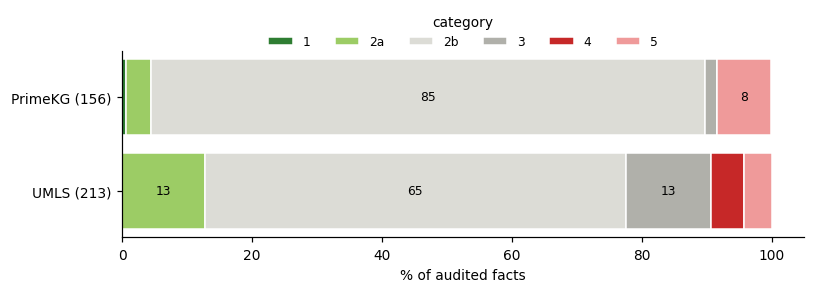

In [58]:
# Category shares per KG (unweighted, cluster-bootstrap CIs over questions, design-weighted), by gold label, link quality
CATS = ["1", "2", "3", "4", "5", "6"]
CAT_NAMES = {"1": "directly relevant", "2": "indirectly relevant", "3": "redundant", "4": "incorrect entity link",
             "5": "incorrect/misleading relationship", "6": "cannot determine"}


def shares(f):
    out = {c: float((f.category == c).mean()) for c in CATS}
    out.update({"2a": float((f.category_2_subtype == "2a").mean()), "2b": float((f.category_2_subtype == "2b").mean())})
    return out


def cluster_ci(f, stat, n_boot=2000, seed=7):
    rng = np.random.default_rng(seed)
    groups = {p: g for p, g in f.groupby("pmid")}
    keys = list(groups)
    vals = [stat(pd.concat([groups[keys[i]] for i in rng.choice(len(keys), len(keys), replace=True)])) for _ in range(n_boot)]
    return [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))]


def audit_summary(df, gold, incl):
    res = {}
    for kg, f in df.groupby("kg"):
        per_q_direct = f[f.category == "1"].groupby("pmid").size().reindex(gold.index, fill_value=0)
        covered = f.pmid.unique()
        r = {"facts": len(f), "questions_with_facts": int(len(covered)),
             "pct": {CAT_NAMES[c]: round(100 * v, 1) for c, v in shares(f).items() if c in CAT_NAMES},
             "pct_2a_2b": {k: round(100 * shares(f)[k], 1) for k in ("2a", "2b")},
             "ci95_pct": {CAT_NAMES[c]: [round(100 * x, 1) for x in cluster_ci(f, lambda d, c=c: (d.category == c).mean())] for c in CATS},
             "link_correct_pct": (f.link_correct.value_counts(normalize=True) * 100).round(1).to_dict(),
             "fact_correct_pct": (f.fact_correct.value_counts(normalize=True) * 100).round(1).to_dict(),
             "questions_with_direct_fact_of_50": int((per_q_direct > 0).sum())}
        if incl is not None:
            w = 1 / f.pmid.map(incl)
            r["design_weighted_pct"] = {CAT_NAMES[c]: round(100 * float(np.average(f.category == c, weights=w)), 1) for c in CATS}
        g = f.merge(gold, left_on="pmid", right_index=True)
        r["by_gold_label"] = {lab: {"facts": len(x), **{CAT_NAMES[c]: round(100 * v, 1) for c, v in shares(x).items() if c in CAT_NAMES}}
                              for lab, x in g.groupby("gold")}
        m = f.assign(mention=f.linking_decision.str.split(" ; ")).explode("mention")
        mm = m.groupby(["pmid", "mention"]).link_correct.agg(lambda s: s.mode().iloc[0])
        r["mentions_with_facts"] = int(len(mm))
        r["mention_link_pct"] = (mm.value_counts(normalize=True) * 100).round(1).to_dict()
        res[kg] = r
    return res


t0 = time.time()
ann = ann.merge(RQ_F[["kg", "pmid", "rank", "stage", "selected_by_alphabetical_order"]],
                left_on=["kg", "pmid", "fact_rank"], right_on=["kg", "pmid", "rank"], how="left")
AUDIT = {"annotator": "AI (Claude), single preliminary annotation; not expert-validated", "checks": checks,
         "per_kg": audit_summary(ann, audit_gold, incl)}
AUDIT["by_retrieval_stage"] = {f"{k}/{s}": shares(x) | {"n": len(x)} for (k, s), x in ann.groupby(["kg", "stage"])}
print(f"(bootstrap CIs computed in {time.time() - t0:.0f} s)")

ann["cat"] = ann["category"].where(ann["category"] != "2", ann["category_2_subtype"])
order = ["1", "2a", "2b", "3", "4", "5", "6"]
share_tab = (ann.groupby("kg")["cat"].value_counts(normalize=True).unstack(fill_value=0).reindex(columns=order, fill_value=0) * 100).round(1)
share_tab["facts"] = ann.groupby("kg").size()
share_tab["questions with >=1 directly relevant fact"] = ann[ann.category == "1"].groupby("kg").pmid.nunique().reindex(share_tab.index, fill_value=0)
display(share_tab)
print("identical to our original audit results:",
      all(AUDIT["per_kg"][kg]["pct"] == REFERENCE_DIAG["audit"][kg]["pct"] for kg in AUDIT["per_kg"]))
display(pd.DataFrame({kg: AUDIT["per_kg"][kg].get("design_weighted_pct", {}) for kg in AUDIT["per_kg"]}).rename_axis("design-weighted %"))

fig, ax = plt.subplots(figsize=(8, 2.2))
cat_colors = ["#2e7d32", "#9ccc65", "#dcdcd6", "#b0b0aa", "#c62828", "#ef9a9a"]
kgs_here = [kg for kg in ("umls", "primekg") if kg in share_tab.index]
for i, kg in enumerate(kgs_here):
    left = 0
    for c, col in zip(order[:-1], cat_colors):
        v = share_tab.loc[kg, c]
        ax.barh(i, v, left=left, color=col, edgecolor="white", label=c if i == 0 else None)
        if v >= 6:
            ax.text(left + v / 2, i, f"{v:.0f}", ha="center", va="center", fontsize=8)
        left += v
ax.set_yticks(range(len(kgs_here)), [f"{KG_NAMES[k]} ({int(share_tab.loc[k, 'facts'])})" for k in kgs_here])
ax.set_xlabel("% of audited facts")
ax.legend(ncol=6, frameon=False, fontsize=8, bbox_to_anchor=(0.5, 1.25), loc="upper center", title="category")
save_fig(fig, "audit_categories"); plt.show()

**What we observe.**

- Of 369 audited facts, **1** was directly relevant (PrimeKG: "breast cancer is associated with the gene/protein
  CYP2D6" for the CYP2D6*4 question). UMLS gave 0 of 213.
- Most facts are true but generic (2b): 65% for UMLS and 85% for PrimeKG.
- UMLS adds more redundant facts (13%, mostly definitional) and some wrong-sense links (5%). PrimeKG adds more
  implausible drug-disease edges (8% wrong or misleading, e.g. "Tranexamic acid is contraindicated in anxiety
  disorder").
- The by-label tables (in `audit_results.json`) look the same for yes, no and maybe questions.

In [59]:
# A few PrimeKG facts with their audit labels (PrimeKG is CC BY 4.0, so its text can be shown)
examples_ids = ["22301406-primekg-0", "11247896-primekg-0", "15475728-primekg-0", "17244100-primekg-1",
                "25636371-primekg-1", "11882828-primekg-1"]
ex_tab = ann.set_index("item_id").loc[examples_ids, ["fact_text", "linking_decision", "cat", "justification"]]
ex_tab.insert(0, "question", [examples[i.split("-")[0]].question[:70] for i in examples_ids])
display(ex_tab)

,question,fact_text,linking_decision,cat,justification
item_id,,,,,
22301406-primekg-0,CYP2D6*4 allele and breast cancer risk: is there any association?,breast cancer is associated with the gene/protein CYP2D6.,'breast cancer' -> breast cancer [disease] ; 'CYP2D6' -> CYP2D6 [gene/protein],1,"States a CYP2D6-breast cancer gene association, the relationship asked; gene-level only (not the *4 allele..."
11247896-primekg-0,Can APC mutation analysis contribute to therapeutic decisions in famil,familial adenomatous polyposis is associated with the gene/protein APC.,'familial adenomatous polyposis' -> familial adenomatous polyposis [disease] ; 'APC' -> APC [gene/protein],3,Gene-disease link FAP-APC is stated throughout the abstract; adds nothing about therapeutic decisions.
15475728-primekg-0,Alcohol consumption and acute myocardial infarction: a benefit of alco,Acetophenazine is contraindicated in myocardial infarction.,'myocardial infarction' -> myocardial infarction [disease],2b,Unrelated drug contraindication.
17244100-primekg-1,Can patient coaching reduce racial/ethnic disparities in cancer pain c,Abacavir may cause Pain as a side effect.,'pain' -> Pain [effect/phenotype],2b,Drug side effect of pain; unrelated.
25636371-primekg-1,Is it possible to stop treatment with nucleos(t)ide analogs in patient,Lamivudine may cause Chronic hepatitis as a side effect.,'chronic hepatitis' -> Chronic hepatitis [effect/phenotype],5,"Lamivudine does not cause chronic hepatitis; the label concerns hepatitis flares after stopping, distorted..."
11882828-primekg-1,Does tranexamic acid reduce desmopressin-induced hyperfibrinolysis?,Tranexamic acid is contraindicated in anxiety disorder.,'tranexamic acid' -> Tranexamic acid [drug],5,Anxiety disorder is not a recognised contraindication of tranexamic acid; likely a data artefact.


## 11.5 Missed key concepts: linking problem or content problem?

For each audited question the annotator listed its 2-4 key concepts (e.g. intervention, outcome, population) and
which of them question linking missed, with the terms to look them up. For every missed concept we search the
**full** UMLS vocabulary (same allowed sources and relation types; these rows were extracted in the Spark pass of
Section 4.2) and the PrimeKG node names, using exact normalised matching. This separates "the KG has it but we did not
link it" (bottleneck B) from "the KG does not have it in a usable form" (bottleneck A). Exact matching is
conservative: "absent" means no exact name match for any listed term, not proof of absence.

In [60]:
# Concept lookup in the full UMLS and in PrimeKG
def umls_presence(terms_by_q):
    conso = load_pass(UMLS_EXTRACT, "MRCONSO")
    conso = conso[conso["nstr"].isin(cands_lookup)]
    rel = load_pass(UMLS_EXTRACT, "MRREL")
    rel = rel[rel["rela"].isin(UMLS_SPECS)]
    deg = pd.concat([rel["cui1"], rel["cui2"]]).value_counts()
    by_term = conso.groupby("nstr")["cui"].apply(set).to_dict()
    names = conso.drop_duplicates("cui").set_index("cui")["str"].to_dict()
    rows = []
    for pmid, concepts in terms_by_q.items():
        for concept, terms in concepts.items():
            cuis = set().union(*[by_term.get(normalize(t), set()) for t in terms])
            edges = int(sum(deg.get(c, 0) for c in cuis))
            rows.append({"pmid": pmid, "concept": concept, "kg": "umls", "n_nodes": len(cuis), "n_edges": edges,
                         "matched": "; ".join(sorted({names[c] for c in cuis}))[:200],
                         "status": "absent" if not cuis else "present_with_edges" if edges else "present_no_whitelisted_edges"})
    return pd.DataFrame(rows), by_term


def primekg_presence(terms_by_q):
    e = primekg_edges
    nodes = pd.concat([e[["s_index", "s_name"]].set_axis(["i", "n"], axis=1), e[["o_index", "o_name"]].set_axis(["i", "n"], axis=1)])
    deg = nodes["i"].value_counts()
    nodes = nodes.drop_duplicates("i")
    nodes["k"] = nodes["n"].map(normalize)
    by = nodes.groupby("k")["i"].apply(set).to_dict()
    name = nodes.set_index("i")["n"].to_dict()
    rows = []
    for pmid, concepts in terms_by_q.items():
        for concept, terms in concepts.items():
            idx = set().union(*[by.get(normalize(t), set()) for t in terms])
            rows.append({"pmid": pmid, "concept": concept, "kg": "primekg", "n_nodes": len(idx),
                         "n_edges": int(sum(deg.get(i, 0) for i in idx)), "matched": "; ".join(sorted(name[i] for i in idx))[:200],
                         "status": "present_with_edges" if idx else "absent"})
    return pd.DataFrame(rows), by


parts = [primekg_presence(LOOKUP_TERMS)[0]]
UMLS_BY_TERM = None
if HAVE_UMLS:
    u, UMLS_BY_TERM = umls_presence(LOOKUP_TERMS)
    parts.insert(0, u)
    u.to_csv(PRIVATE / "diagnostics" / "concept_lookup_umls_matches.csv", index=False)
look = pd.concat(parts, ignore_index=True)
look["in_question"] = [AUDIT_DATA["questions"][p]["missed"][c]["in_question"] for p, c in zip(look.pmid, look.concept)]
look["missed_here"] = [AUDIT_DATA["questions"][p]["missed"][c]["missed_in"] in ("both", kg)
                       for p, c, kg in zip(look.pmid, look.concept, look.kg)]
look.assign(matched=np.where(look.kg == "primekg", look.matched, "")).to_csv(R["audit"] / "concept_lookup.csv", index=False)

labels_map = {"present_with_edges": "B: in KG with usable edges, not linked",
              "present_no_whitelisted_edges": "A: in vocabulary, no whitelisted relations",
              "absent": "A: no exact match in KG"}
m = look[look.missed_here]
missed = {kg: {"in_question": x[x.in_question].status.map(labels_map).value_counts().to_dict(),
               "abstract_or_background_only": x[~x.in_question].status.map(labels_map).value_counts().to_dict()}
          for kg, x in m.groupby("kg")}
AUDIT["missed_concepts"] = missed
display(pd.crosstab(m[m.in_question].status.map(labels_map), m[m.in_question].kg, margins=True))
print("identical to our original lookup:", all(missed[kg] == REFERENCE_DIAG["missed_concepts"][kg] for kg in missed))
kc = AUDIT_DATA["key_concept_coverage"]
print(f"Key-concept linking coverage ({kc['note']}): UMLS {kc['linked']['umls']}/{kc['key_concepts']}, "
      f"PrimeKG {kc['linked']['primekg']}/{kc['key_concepts']}")
save_json(AUDIT, R["audit"] / "audit_results.json")

kg,primekg,umls,All
status,,,
"A: in vocabulary, no whitelisted relations",0,56,56
A: no exact match in KG,73,2,75
"B: in KG with usable edges, not linked",25,23,48
All,98,81,179


identical to our original lookup: True
Key-concept linking coverage (counted by the AI annotator from its question-level lists (partial and generic links count as linked)): UMLS 65/146, PrimeKG 48/146


**What we found.**

- Only 45% (UMLS) and 33% (PrimeKG) of the key question concepts were linked, and in only one question per KG were
  *all* key concepts linked.
- About a quarter of the missed concepts exist in the KG with usable relations (bottleneck B). Examples:
  "desmopressin" inside "desmopressin-induced", "postnatal" vs "postpartum" depression, "alcohol" vs "ethanol".
- About 70-75% do not exist in a usable form (bottleneck A): procedures (vertebroplasty, sleeve gastrectomy, LEEP),
  tests and measurements (pH monitoring, FDG-PET in PrimeKG), exposures (music, exercise, alloxan), biomarkers
  without relations (Ki-67), and five questions that are not about biomedical entities at all (h-index, OSCE exams,
  insurance policy, area deprivation, awareness campaigns).

So all three of A, B and C show up. The next section asks which one actually limits us.

## 11.6 Code for a future human validation

We did not run a human annotation. If someone later labels (part of) the audited facts, this cell compares the
human and AI categories: raw agreement and Cohen's kappa per KG. The file needs the columns `item_id` and `category`
(1-6). With no file it does nothing, so **no agreement statistic is reported in this study**.

In [61]:
# Optional: agreement between a human annotation and the AI annotation (not used in this study)
HUMAN_ANNOTATION_CSV = None        # e.g. "/content/data/human_annotation.csv"


def cohen_kappa(a, b):
    a, b = list(a), list(b)
    cats = sorted(set(a) | set(b))
    n = len(a)
    po = sum(x == y for x, y in zip(a, b)) / n
    pe = sum((a.count(c) / n) * (b.count(c) / n) for c in cats)
    return (po - pe) / (1 - pe) if pe < 1 else 1.0


if HUMAN_ANNOTATION_CSV:
    human = pd.read_csv(HUMAN_ANNOTATION_CSV, dtype=str)[["item_id", "category"]].rename(columns={"category": "human"})
    both = ann.merge(human, on="item_id")
    for kg, x in both.groupby("kg"):
        print(f"{KG_NAMES[kg]}: {len(x)} facts, agreement {np.mean(x.human == x.category):.3f}, "
              f"Cohen's kappa {cohen_kappa(x.human, x.category):.3f}")
else:
    print("No human annotation supplied: no agreement statistic (the audit stays preliminary).")

No human annotation supplied: no agreement statistic (the audit stays preliminary).


# 12. Retrieval Strategy Analysis

**What we wanted to know.** If we fixed retrieval, would the model get relevant facts? We tried three alternative
strategies on the same 50 audited questions. **These are diagnostic retrieval runs only: no new LLM predictions are
made with them.** The original retriever and its facts are not changed.

| Strategy | What changes compared with R1 | Why |
|---|---|---|
| **R1** | (the facts the LLM actually saw) | baseline |
| **R1'** | same candidates and caps, but neighbours that also appear in the abstract come first instead of alphabetical order | tests whether the *ranking* is the problem |
| **R2** | only edges from a question concept to another question concept or to an abstract concept | tests whether linking the question to the abstract finds claim-related facts |
| **R3** | edges among abstract concepts, kept if one end is a direct neighbour of a question concept | tests whether the abstract's own concepts are connected in a useful way |

For these we use the question+abstract-scoped UMLS graph and the PrimeKG whitelist. Abstract concepts are linked with
the same linker, minus single-word synonym links (surface differs from the concept name), the main source of wrong
senses in the audit. R2 and R3 keep at most 8 edges, ordered by relation priority, then the less-connected (more
specific) edge first, then text. New facts were labelled with the same guidelines by the same AI annotator.

We also compute an **upper bound**: assume linking were perfect (add every missed key concept that the lookup found
in the KG) and check whether any two key concepts of a question are connected by a direct edge or a two-hop path.
For UMLS this uses all whitelisted UMLS relations of those concepts (from the Spark pass), at concept (CUI) level.

In [62]:
# Strategies R1, R1', R2, R3 and the connectivity of the linked concepts
STRAT_CAP = 8


def risky(m):
    s, n = normalize(m.surface), normalize(m.node_name)
    return len(s.split()) == 1 and s != n and s.rstrip("s") != n.rstrip("s")


def r1_prime(retr, q_nodes, a_nodes, max_facts=8, per_entity=4, per_relation=2):
    """The R1 algorithm with one change: neighbours that are abstract concepts come first."""
    chosen, texts = [], set()
    for a, b in combinations(q_nodes, 2):
        added = 0
        for f in retr.by_node.get(a, []):
            if {f.s_index, f.o_index} == {a, b} and added < per_relation and f.text not in texts and len(chosen) < max_facts:
                chosen.append(f); texts.add(f.text); added += 1
    other = lambda f, n: f.o_index if f.s_index == n else f.s_index
    lists = {n: sorted(retr.by_node.get(n, []), key=lambda f: (other(f, n) not in a_nodes, f.priority,
                                                                 f.display_relation, f.text.lower())) for n in q_nodes}
    per_ent, per_rel, iters = defaultdict(int), defaultdict(int), {n: iter(lists[n]) for n in q_nodes}
    active = list(q_nodes)
    while active and len(chosen) < max_facts:
        still = []
        for n in active:
            if per_ent[n] >= per_entity or len(chosen) >= max_facts:
                continue
            f = next((f for f in iters[n] if f.text not in texts and per_rel[(n, f.display_relation)] < per_relation), None)
            if f is not None:
                chosen.append(f); texts.add(f.text); per_ent[n] += 1; per_rel[(n, f.display_relation)] += 1; still.append(n)
        active = still
    return chosen


def edge_facts(retr, pairs_ok, deg, nodes, node_rank):
    """Edges whose two ends satisfy pairs_ok, one per sentence, ordered by relation priority, then the less-connected
    edge first, then text. Both ends of such an edge are in `nodes`, so scanning only those nodes in the graph's
    node order visits the edges in the same order as a scan of the whole graph."""
    seen, out = set(), []
    for n in sorted((n for n in nodes if n in retr.by_node), key=node_rank.get):
        for f in retr.by_node[n]:
            if f.text not in seen and pairs_ok(f.s_index, f.o_index):
                seen.add(f.text); out.append(f)
    out.sort(key=lambda f: (f.priority, math.log1p(deg[f.s_index]) + math.log1p(deg[f.o_index]), f.text.lower()))
    return out


STRAT_KG = {"primekg": (primekg_linker, primekg_retriever)}
if HAVE_UMLS:
    g = UMLS_GRAPHS["question_abstract"]
    STRAT_KG["umls"] = (EntityLinker(node_table(g["edges"]), g["aliases"]), FactRetriever(g["edges"], "umls"))

srows, lrows, crows = [], [], []
for kg in STUDY_KGS:
    linker, retr = STRAT_KG[kg]
    deg = {n: len(v) for n, v in retr.neighbors.items()}
    node_rank = {n: i for i, n in enumerate(retr.by_node)}
    for p in AUDIT_PMIDS:
        e = examples[p]
        qm, am = linker.link(e.question), linker.link(e.abstract)
        Q = list(dict.fromkeys(m.node_index for m in qm))
        A = {m.node_index for m in am if not risky(m)} - set(Q)
        for where, ms in (("question", qm), ("abstract", [m for m in am if m.node_index not in Q])):
            for m in ms:
                lrows.append({"kg": kg, "pmid": p, "where": where, "surface": m.surface, "node": m.node_name,
                              "type": m.node_type, "risky": risky(m)})
        near_q = set().union(*[retr.neighbors.get(n, set()) for n in Q]) if Q else set()
        strategies = {
            "R1": [(f.text, f.display_relation) for f in KG_SETUP[kg]["facts_obj"][p]],
            "R1_rerun": [(f.text, f.display_relation) for f in retr.retrieve(Q, **CAPS)],
            "R1p": [(f.text, f.display_relation) for f in r1_prime(retr, Q, A)],
            "R2": [(f.text, f.display_relation) for f in edge_facts(
                retr, lambda s, o: (s in Q and (o in Q or o in A)) or (o in Q and s in A), deg, set(Q) | A, node_rank)][:STRAT_CAP],
            "R3": [(f.text, f.display_relation) for f in edge_facts(
                retr, lambda s, o: s in A and o in A and s != o and (s in near_q or o in near_q), deg, A, node_rank)][:STRAT_CAP]}
        for st, fs in strategies.items():
            for i, (t, r_) in enumerate(fs):
                srows.append({"kg": kg, "pmid": p, "strategy": st, "rank": i, "fact_text": t, "relation": r_,
                              "fact_sha": hashlib.sha256(t.encode()).hexdigest()[:10]})
        crows.append({"kg": kg, "pmid": p, "n_q_entities": len(Q), "n_abs_entities": len(A),
                      "n_abs_entities_risky_dropped": sum(risky(m) for m in am),
                      "qq_pairs": len(Q) * (len(Q) - 1) // 2,
                      "qq_direct": sum(1 for a, b in combinations(Q, 2) if b in retr.neighbors.get(a, set())),
                      "qq_2hop": sum(1 for a, b in combinations(Q, 2) if retr.neighbors.get(a, set()) & retr.neighbors.get(b, set())),
                      "qa_direct_pairs": sum(1 for a in Q for b in A if b in retr.neighbors.get(a, set()))})
SF, SL, SC = pd.DataFrame(srows), pd.DataFrame(lrows), pd.DataFrame(crows)
for kg in STUDY_KGS:
    a = set(map(tuple, SF[(SF.kg == kg) & (SF.strategy == "R1")][["pmid", "fact_text"]].values))
    b = set(map(tuple, SF[(SF.kg == kg) & (SF.strategy == "R1_rerun")][["pmid", "fact_text"]].values))
    print(f"{KG_NAMES[kg]}: R1 re-run on this graph reproduces the supplied facts: {a == b} ({len(a & b)} shared)")
if HAVE_UMLS:
    SF.to_csv(PRIVATE / "diagnostics" / "strategy_facts_with_umls_text.csv", index=False)
    SL.to_csv(PRIVATE / "diagnostics" / "strategy_links_with_umls_text.csv", index=False)
SF.assign(fact_text=np.where(SF.kg == "primekg", SF.fact_text, "")).to_csv(R["strategies"] / "strategy_facts.csv", index=False)
SC.to_csv(R["strategies"] / "connectivity.csv", index=False)

UMLS: R1 re-run on this graph reproduces the supplied facts: True (213 shared)
PrimeKG: R1 re-run on this graph reproduces the supplied facts: True (156 shared)


In [63]:
# Upper bound: with perfect linking, are two key concepts of a question connected at all?
def umls_cui_graph():
    rel = load_pass(UMLS_EXTRACT, "MRREL").drop_duplicates()
    rel = rel[rel.rela.isin(UMLS_SPECS) & (rel.cui1 != rel.cui2)]
    adj, lab = defaultdict(set), {}
    for r_ in rel.itertuples(index=False):
        adj[r_.cui1].add(r_.cui2); adj[r_.cui2].add(r_.cui1)
        lab.setdefault(frozenset((r_.cui1, r_.cui2)), set()).add(r_.rela)
    return adj, lab


pby = defaultdict(set)
for i, n in {**dict(zip(primekg_edges.s_index, primekg_edges.s_name)), **dict(zip(primekg_edges.o_index, primekg_edges.o_name))}.items():
    pby[normalize(n)].add(i)
if HAVE_UMLS:
    u_adj, u_lab = umls_cui_graph()
    cui_of_qa = UMLS_GRAPHS["question_abstract"]["cui_of"]

orows, opaths = [], []
for p in AUDIT_PMIDS:
    q = examples[p].question
    for kg in STUDY_KGS:
        linker, retr = STRAT_KG[kg]
        concepts = {}
        if kg == "umls":
            for m in linker.link(q):
                concepts[f"linked:{m.node_name}"] = {cui_of_qa[m.node_index]}
            nbr, labels = u_adj, u_lab
        else:
            for m in linker.link(q):
                concepts[f"linked:{m.node_name}"] = {m.node_index}
            nbr, labels = retr.neighbors, None
        for c, info in AUDIT_DATA["questions"][p]["missed"].items():
            if not info["in_question"] or info["missed_in"] not in ("both", kg):
                continue
            hit = look[(look.pmid == p) & (look.concept == c) & (look.kg == kg)]
            if hit.empty or hit.status.iloc[0] != "present_with_edges":
                continue
            terms = LOOKUP_TERMS[p][c]
            nodes = set().union(*[(UMLS_BY_TERM if kg == "umls" else pby).get(normalize(t), set()) for t in terms])
            if nodes:
                concepts[f"lookup:{c}"] = nodes
        pairs = [(a, b) for a, b in combinations(concepts, 2) if not (concepts[a] & concepts[b])]
        direct = two = 0
        for a, b in pairs:
            A_, B_ = concepts[a], concepts[b]
            d = [(x, y) for x in A_ for y in B_ if y in nbr.get(x, set())]
            mids = {z for x in A_ for y in B_ for z in (nbr.get(x, set()) & nbr.get(y, set()))}
            if d:
                direct += 1
                rel_ = sorted(set().union(*[labels.get(frozenset(e_), set()) for e_ in d])) if labels else []
                opaths.append({"kg": kg, "pmid": p, "a": a, "b": b, "kind": "direct", "detail": ";".join(rel_)})
            if mids:
                two += 1
                opaths.append({"kg": kg, "pmid": p, "a": a, "b": b, "kind": "2hop", "n_intermediates": len(mids),
                               "min_intermediate_degree": sorted(len(nbr.get(z, ())) for z in mids)[0], "detail": ""})
        orows.append({"kg": kg, "pmid": p, "key_concepts_available": len(concepts),
                      "from_lookup": sum(k.startswith("lookup:") for k in concepts), "pairs": len(pairs),
                      "pairs_direct": direct, "pairs_2hop": two})
OC, OP = pd.DataFrame(orows), pd.DataFrame(opaths)
OC.to_csv(R["strategies"] / "oracle_connectivity.csv", index=False)
if HAVE_UMLS:
    OP.to_csv(PRIVATE / "diagnostics" / "oracle_paths_with_umls_names.csv", index=False)
if len(OP):
    OP[OP.kg == "primekg"].to_csv(R["strategies"] / "oracle_paths_primekg.csv", index=False)

strategy facts without an AI label: 0 (0 means every fact was labelled)


,KG,strategy,facts,questions with facts,facts not in R1,categories,questions with a directly relevant fact
0,umls,R1,213,40,0,"{'2': 165, '3': 28, '4': 11, '5': 9}",0
1,umls,R1',213,40,4,"{'2': 163, '3': 30, '4': 11, '5': 9}",0
2,umls,R2,7,5,4,{'3': 7},0
3,umls,R3,0,0,0,{},0
4,primekg,R1,156,33,0,"{'1': 1, '2': 139, '3': 3, '5': 13}",1
5,primekg,R1',156,33,5,"{'1': 2, '2': 136, '3': 4, '5': 14}",1
6,primekg,R2,8,5,5,"{'1': 2, '2': 2, '3': 2, '5': 2}",1
7,primekg,R3,1,1,1,{'2': 1},0


identical to our original strategy results: True 


,umls,primekg
question_entities,63,43
abstract_entities_after_filter,73,54
abstract_mentions_dropped_as_risky_synonyms,68,0
questions_with_abstract_entities,33,27
questions_with_qq_direct_edge,0,2
questions_with_qq_2hop,6,2
questions_with_q_abstract_direct_edge,5,5
oracle_questions_with_2plus_key_concepts,31,23
oracle_questions_with_direct_key_edge,1,4
oracle_questions_with_2hop_key_path,13,9


AI labels of the direct key-concept edges found under perfect linking (UMLS edge text not shown):


,kg,pmid,category,subtype,edge,note
0,primekg,19299238,2,2a,Letrozole is contraindicated in osteoporosis.,"Supports the premise that aromatase inhibitors harm bone, not whether preventing osteoporosis removes the ..."
1,primekg,19299238,2,2a,Anastrozole / Letrozole may cause Osteoporosis as a side effect.,"Same: background for the premise, not the claim."
2,primekg,19299238,3,,Anastrozole / Letrozole may cause Arthralgia as a side effect.,Aromatase-inhibitor musculoskeletal symptoms are stated in the question.
3,umls,25636371,3,,,
4,primekg,25636371,5,,Lamivudine may cause Chronic hepatitis as a side effect.,Distorted post-withdrawal flare warning (audit fact 25636371-primekg-1).
5,primekg,11247896,3,,familial adenomatous polyposis is associated with the gene/protein APC.,Retrieved by R1; already stated in the abstract.
6,primekg,22301406,1,,breast cancer is associated with the gene/protein CYP2D6.,Retrieved by R1; the only answer-bearing association found.


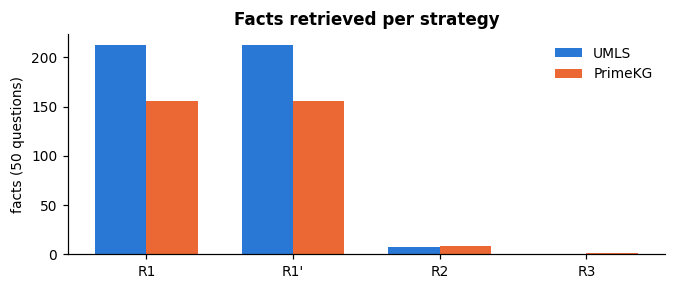

In [64]:
# Summary per strategy with the AI relevance labels (identical facts keep their audit label)
LAB = {(r.kg, r.pmid, r.fact_sha): (r.link_correct, r.category) for r in ann.itertuples()}
extra = pd.read_csv(io.StringIO(AUDIT_DATA["extra_csv"]), dtype=str, keep_default_na=False)
for r in extra.itertuples():
    LAB[(r.kg, r.pmid, r.fact_sha)] = (r.link_correct, r.category)
F = SF[SF.strategy != "R1_rerun"].copy()
F["key"] = list(zip(F.kg, F.pmid, F.fact_sha))
F["link_correct"] = [LAB.get(k, ("unlabelled", None))[0] for k in F.key]
F["category"] = [LAB.get(k, (None, "unlabelled"))[1] for k in F.key]
print("strategy facts without an AI label:", int((F.category == "unlabelled").sum()), "(0 means every fact was labelled)")
STRAT = {}
for (kg, st), x in F.groupby(["kg", "strategy"]):
    r1 = set(F[(F.kg == kg) & (F.strategy == "R1")].key)
    STRAT[f"{kg}/{st}"] = {"facts": len(x), "questions_with_facts": int(x.pmid.nunique()),
                           "categories": x.category.value_counts().sort_index().to_dict(),
                           "link_correct": x.link_correct.value_counts().to_dict(),
                           "questions_with_direct_fact": int(x[x.category == "1"].pmid.nunique()),
                           "new_vs_R1": int(sum(1 for k in x.key if k not in r1))}
for kg in STUDY_KGS:
    c, o = SC[SC.kg == kg], OC[OC.kg == kg]
    STRAT[f"{kg}/connectivity"] = {
        "question_entities": int(c.n_q_entities.sum()), "abstract_entities_after_filter": int(c.n_abs_entities.sum()),
        "abstract_mentions_dropped_as_risky_synonyms": int(c.n_abs_entities_risky_dropped.sum()),
        "questions_with_abstract_entities": int((c.n_abs_entities > 0).sum()),
        "questions_with_qq_direct_edge": int((c.qq_direct > 0).sum()), "questions_with_qq_2hop": int((c.qq_2hop > 0).sum()),
        "questions_with_q_abstract_direct_edge": int((c.qa_direct_pairs > 0).sum()),
        "oracle_questions_with_2plus_key_concepts": int((o.key_concepts_available >= 2).sum()),
        "oracle_questions_with_direct_key_edge": int((o.pairs_direct > 0).sum()),
        "oracle_questions_with_2hop_key_path": int((o.pairs_2hop > 0).sum()),
        "oracle_key_pairs": int(o.pairs.sum()), "oracle_pairs_direct": int(o.pairs_direct.sum()), "oracle_pairs_2hop": int(o.pairs_2hop.sum())}
save_json(STRAT, R["strategies"] / "strategy_results.json")

rows = []
for kg in STUDY_KGS:
    for st, name in (("R1", "R1"), ("R1p", "R1'"), ("R2", "R2"), ("R3", "R3")):
        r_ = STRAT.get(f"{kg}/{st}", {"facts": 0, "questions_with_facts": 0, "categories": {}, "questions_with_direct_fact": 0, "new_vs_R1": 0})
        rows.append({"KG": kg, "strategy": name, "facts": r_["facts"], "questions with facts": r_["questions_with_facts"],
                     "facts not in R1": r_["new_vs_R1"], "categories": r_["categories"],
                     "questions with a directly relevant fact": r_["questions_with_direct_fact"]})
strat_table = pd.DataFrame(rows)
display(strat_table)
same = {k: STRAT[k] == REFERENCE_DIAG["strategies"].get(k) for k in STRAT}
print("identical to our original strategy results:", all(same.values()), "" if all(same.values()) else same)
display(pd.DataFrame({kg: STRAT[f"{kg}/connectivity"] for kg in STUDY_KGS}))

oracle_labels = pd.DataFrame(AUDIT_DATA["oracle_edges"])
print("AI labels of the direct key-concept edges found under perfect linking (UMLS edge text not shown):")
display(oracle_labels[oracle_labels.kg.isin(STUDY_KGS)])

fig, ax = plt.subplots(figsize=(7, 2.6))
for j, kg in enumerate(STUDY_KGS):
    t = strat_table[strat_table.KG == kg]
    ax.bar(np.arange(4) + (j - 0.5) * 0.35, t["facts"], 0.35, color=KG_COLORS[kg], label=KG_NAMES[kg])
ax.set_xticks(range(4), ["R1", "R1'", "R2", "R3"]); ax.set_ylabel("facts (50 questions)")
ax.set_title("Facts retrieved per strategy"); ax.legend(frameon=False)
save_fig(fig, "retrieval_strategies"); plt.show()

**What we found.**

- **R1'** changes only 4 (UMLS) and 5 (PrimeKG) of the facts: few neighbours of question concepts appear in the
  abstract at all.
- **R2** finds very few edges (7 UMLS, 8 PrimeKG, in 5 questions each), mostly redundant restatements such as
  "lung cancer has the manifestation non-small cell lung cancer" or a drug named in the abstract treating the
  disease. **R3** finds 0 (UMLS) and 1 (PrimeKG) fact.
- No strategy adds a single new question with a directly relevant fact. The only such question in either KG is still
  the CYP2D6 one.
- **Upper bound:** even with perfect linking, two key concepts share a direct edge in only 1 (UMLS) and 4 (PrimeKG)
  of the 50 questions, and the AI labels of these edges (table above) show only one directly relevant edge (the
  CYP2D6 one); the rest are redundant, merely related or misleading. Two-hop paths exist in 13 and 9 questions, but
  they go through a shared drug or syndrome, so they only say "both concepts have a common neighbour". That cannot
  express a study finding like "X improves Y in group Z".

**What this tells us about retrieval.** The alphabetical ranking (C) explains why the supplied facts are noise, but
better ranking or abstract-aware retrieval cannot produce relevant facts that are not in the graph. For PubMedQA, the
graphs mostly do not contain the claims the questions are about. KG content (A) is the dominant bottleneck; linking
(B) and retrieval (C) are real but secondary.

# 13. Prediction-Change Analysis

**What we wanted to know.** Accuracy differences hide what happens to individual answers. We compare the predictions
of Section 8 question by question to see which answers changed when facts were added, and whether those changes
fixed or broke the answer. No new inference is run.

Reminder: E1 = question only, E2 = + abstract, E3/E4 = + relevant facts (without/with abstract), C3/C4 = + matched
irrelevant facts.

Only questions that received facts can change (Section 7.3), so the counts below are over the covered questions
(291 for UMLS and 203 for PrimeKG in our run). A change is **fixed** if the old answer was wrong and the new one is
right, **broke** if the old answer was right and the new one wrong. The exact sign test of fixed vs broke is
exploratory and uncorrected.

In [65]:
# Transitions for every model, KG and comparison
from scipy.stats import binomtest
PAIRS = [("E2", "E4"), ("C4", "E4"), ("E1", "E3"), ("C3", "E3"), ("E2", "C4"), ("E1", "C3")]


def sign_p(k, m):
    return round(float(binomtest(k, k + m, 0.5).pvalue), 4) if k + m else None


def transitions(P, kg, base, new, subset=None):
    B, N = P[kg][base], P[kg][new]
    fact_cond = new if new in ("E3", "E4", "C3", "C4") else base
    ids = [p for p in sorted(N) if P[kg][fact_cond][p]["n_facts"] > 0 and (subset is None or split_of[p] in subset)]
    rows = []
    for p in ids:
        a, b, g = B[p]["predicted"], N[p]["predicted"], N[p]["gold"]
        eff = "no change" if a == b else "fixed" if (a != g and b == g) else "broke" if (a == g and b != g) else "wrong->wrong"
        rows.append({"pmid": p, "gold": g, "base": a, "new": b, "transition": "unchanged" if a == b else f"{a}->{b}", "effect": eff})
    d = pd.DataFrame(rows)
    ch = d[d.base != d.new]
    trans = Counter(d.transition)
    fixed, broke = int((d.effect == "fixed").sum()), int((d.effect == "broke").sum())
    return {"kg": kg, "comparison": f"{base}->{new}", "n_covered": len(d), "changed": len(ch),
            "changed_pct": round(100 * len(ch) / len(d), 1) if len(d) else None, "fixed": fixed, "broke": broke,
            "wrong_to_wrong": int((d.effect == "wrong->wrong").sum()), "net_correct": fixed - broke,
            "to_maybe": int(ch.new.eq("maybe").sum()), "from_maybe": int(ch.base.eq("maybe").sum()),
            **{t: int(trans.get(t, 0)) for t in ["yes->maybe", "no->maybe", "maybe->yes", "maybe->no", "yes->no", "no->yes"]},
            "sign_test_p_fixed_vs_broke": sign_p(fixed, broke),
            "acc_base": round(float((d.base == d.gold).mean()), 3) if len(d) else None,
            "acc_new": round(float((d.new == d.gold).mean()), 3) if len(d) else None}, d


TRANS, long_rows = {}, []
for model_id in LLM_SUMMARY:
    preds = LLM_PREDS[model_id]
    P = {kg: {"E1": preds["E1"], "E2": preds["E2"], **{c: preds[f"{c}/{kg}"] for c in KG_CONDS}} for kg in STUDY_KGS}
    for scope, subset in (("dev100", {"dev_100"}), ("dev500", None)):
        for kg in STUDY_KGS:
            for base, new in PAIRS:
                s, d = transitions(P, kg, base, new, subset)
                TRANS.setdefault(model_tag(model_id), {}).setdefault(scope, []).append(s)
                if scope == "dev500":
                    long_rows.append(d.assign(model=model_id, kg=kg, comparison=f"{base}->{new}"))
if TRANS:
    pd.concat(long_rows).to_csv(R["transitions"] / "transitions_long.csv", index=False)
    save_json(TRANS, R["transitions"] / "transitions_results.json")
    cols = ["kg", "comparison", "n_covered", "changed", "fixed", "broke", "net_correct", "to_maybe", "from_maybe",
            "yes->maybe", "maybe->yes", "no->maybe", "maybe->no", "yes->no", "no->yes", "sign_test_p_fixed_vs_broke"]
    ref_names = {"Qwen3-4B-Instruct-2507": "qwen", "Phi-4-mini-instruct": "phi4mini"}
    for tag, res in TRANS.items():
        t = pd.DataFrame(res["dev500"])
        ref = REFERENCE_DIAG["transitions"].get(ref_names.get(tag, ""), {})
        t["original changed/fixed/broke"] = ["/".join(map(str, ref.get(f"{k}/{c}", []))) for k, c in zip(t.kg, t.comparison)]
        print(f"{tag}, Dev-500 (covered questions only):")
        display(t[cols + ["original changed/fixed/broke"]])
else:
    print("No complete LLM predictions yet (Section 8.3).")

Qwen3-4B-Instruct-2507, Dev-500 (covered questions only):


,kg,comparison,n_covered,changed,fixed,broke,net_correct,to_maybe,from_maybe,yes->maybe,maybe->yes,no->maybe,maybe->no,yes->no,no->yes,sign_test_p_fixed_vs_broke,original changed/fixed/broke
0,umls,E2->E4,291,25,6,10,-4,9,15,8,14,1,1,0,1,0.4545,25/6/10
1,umls,C4->E4,291,19,7,7,0,9,10,5,8,4,2,0,0,1.0000,19/7/7
2,umls,E1->E3,291,41,5,29,-24,40,1,36,0,4,1,0,0,0.0000,41/5/29
3,umls,C3->E3,291,7,2,3,-1,3,4,2,2,1,2,0,0,1.0000,7/2/3
4,umls,E2->C4,291,30,9,13,-4,12,17,10,13,2,4,0,1,0.5235,30/9/13
5,umls,E1->C3,291,44,6,29,-23,42,2,37,1,5,1,0,0,0.0001,44/6/29
6,primekg,E2->E4,203,25,11,9,2,10,15,8,13,2,2,0,0,0.8238,25/11/9
7,primekg,C4->E4,203,15,8,3,5,8,6,8,6,0,0,1,0,0.2266,15/8/3
8,primekg,E1->E3,203,27,3,19,-16,25,2,21,1,4,1,0,0,0.0009,27/3/19
9,primekg,C3->E3,203,5,2,1,1,1,4,0,3,1,1,0,0,1.0000,5/2/1


Phi-4-mini-instruct, Dev-500 (covered questions only):


,kg,comparison,n_covered,changed,fixed,broke,net_correct,to_maybe,from_maybe,yes->maybe,maybe->yes,no->maybe,maybe->no,yes->no,no->yes,sign_test_p_fixed_vs_broke,original changed/fixed/broke
0,umls,E2->E4,291,19,10,7,3,6,13,1,10,5,3,0,0,0.6291,19/10/7
1,umls,C4->E4,291,14,4,9,-5,11,3,8,2,3,1,0,0,0.2668,14/4/9
2,umls,E1->E3,291,34,5,14,-9,30,4,26,2,4,2,0,0,0.0636,34/5/14
3,umls,C3->E3,291,15,5,5,0,10,5,9,3,1,2,0,0,1.0000,15/5/5
4,umls,E2->C4,291,21,13,5,8,3,18,0,15,3,3,0,0,0.0963,21/13/5
5,umls,E1->C3,291,31,4,13,-9,26,5,22,4,4,1,0,0,0.0490,31/4/13
6,primekg,E2->E4,203,8,4,3,1,3,5,1,4,2,1,0,0,1.0000,8/4/3
7,primekg,C4->E4,203,12,0,11,-11,12,0,9,0,3,0,0,0,0.0010,12/0/11
8,primekg,E1->E3,203,25,2,12,-10,19,6,17,5,2,1,0,0,0.0129,25/2/12
9,primekg,C3->E3,203,13,1,6,-5,8,5,8,4,0,1,0,0,0.1250,13/1/6


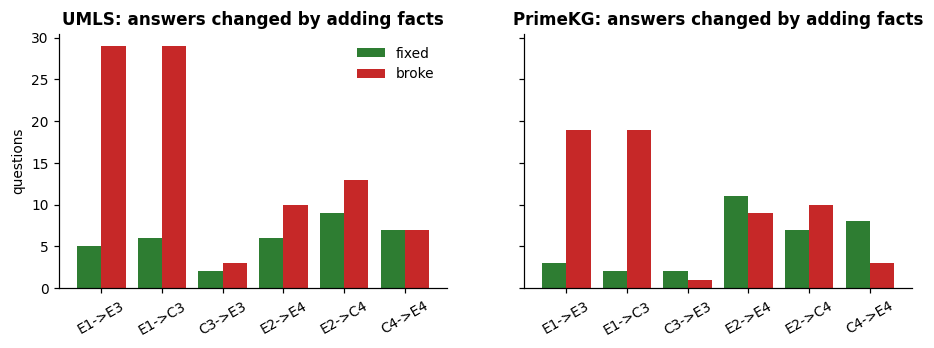

,kg,comparison,n_covered,changed,fixed,broke,net_correct
0,umls,E2->E4,56,3,0,1,-1
1,umls,C4->E4,56,3,2,1,1
2,umls,E1->E3,56,6,1,4,-3
3,umls,C3->E3,56,1,0,1,-1
4,umls,E2->C4,56,6,1,3,-2
5,umls,E1->C3,56,7,2,4,-2
6,primekg,E2->E4,39,4,1,1,0
7,primekg,C4->E4,39,2,2,0,2
8,primekg,E1->E3,39,5,1,2,-1
9,primekg,C3->E3,39,1,0,0,0


In [66]:
# Plot: fixed vs broken answers for each comparison (Qwen3-4B, Dev-500), and the Dev-100 subset
if "Qwen3-4B-Instruct-2507" in TRANS:
    qwen_tr = pd.DataFrame(TRANS["Qwen3-4B-Instruct-2507"]["dev500"])
    fig, axes = plt.subplots(1, len(STUDY_KGS), figsize=(5 * len(STUDY_KGS), 3), sharey=True, squeeze=False)
    comps_ = ["E1->E3", "E1->C3", "C3->E3", "E2->E4", "E2->C4", "C4->E4"]
    for ax, kg in zip(axes[0], STUDY_KGS):
        t = qwen_tr[qwen_tr.kg == kg].set_index("comparison").loc[comps_]
        x = np.arange(len(comps_))
        ax.bar(x - 0.2, t["fixed"], 0.4, color="#2e7d32", label="fixed")
        ax.bar(x + 0.2, t["broke"], 0.4, color="#c62828", label="broke")
        ax.set_xticks(x, comps_, rotation=30); ax.set_title(f"{KG_NAMES[kg]}: answers changed by adding facts")
    axes[0][0].set_ylabel("questions"); axes[0][0].legend(frameon=False)
    save_fig(fig, "transitions_qwen"); plt.show()
    display(pd.DataFrame(TRANS["Qwen3-4B-Instruct-2507"]["dev100"])[["kg", "comparison", "n_covered", "changed", "fixed", "broke", "net_correct"]])

**What we found.**

- **Without the abstract, facts push answers to "maybe", whatever they say.** For Qwen with UMLS, E1 -> E3 changed
  41 answers: 40 moved to "maybe" (mostly yes -> maybe), 5 got fixed and 29 broke. Irrelevant facts (E1 -> C3) did
  almost exactly the same (44 changed, 6 fixed, 29 broke). Between E3 and C3 only 7 answers (2.4%) differ. PrimeKG
  and Phi-4-mini show the same pattern.
- **With the abstract, facts change about 1 answer in 10, in both directions** (mostly maybe <-> yes), with no
  consistent gain: E2 -> E4 is 6 fixed / 10 broke for UMLS and 11 / 9 for PrimeKG; relevant vs control (C4 -> E4)
  is 7 / 7 and 8 / 3, none significant.
- **Direct yes <-> no flips almost never happen** (at most 1 per comparison).
- For Phi-4-mini with PrimeKG, the *control* facts helped with the abstract (E2 -> C4: 13 fixed, 1 broke), mostly by
  moving "maybe" to "yes". This explains why C4 beat E4 for Phi in Section 8.7. Since the facts were irrelevant, this
  is a context effect, not knowledge.
- The Dev-100 subset shows the same directions with small numbers.

**Why this does not answer bottleneck D.** These changes show that the model reacts to the *presence* of a fact
block, mainly by becoming more or less cautious. They do not show that it read or understood the facts. Since
almost none of the facts were relevant (Section 11), our experiments never tested whether the model *can* use
genuinely relevant biomedical knowledge.

# 14. Consolidated discussion

**Why the abstract helps so much.** PubMedQA questions ask what a particular study found. The abstract (even without
its conclusion) reports that study's results, so it contains the evidence; E1 -> E2 adds 36 accuracy points. Without
it, the model mostly says "maybe", which is a reasonable reaction to a question it cannot answer from memory.

**Why KG augmentation gave no measurable gain.** Our evidence points to the knowledge itself:

1. **The graphs rarely contain the answer-bearing relationship (A).** Even with perfect linking, a directly relevant
   edge between key concepts existed in only 1 of 50 audited questions. Curated KGs store general relations (drug
   treats disease, disease has phenotype, gene associated with disease), not study-level findings about procedures,
   measurements, exposures and populations.
2. **Linking misses or confuses many concepts (B).** Fewer than half of the key concepts were linked; UMLS synonyms
   help coverage but bring wrong senses.
3. **Retrieval returns generic, alphabetically chosen neighbours (C).** This explains why the supplied facts were
   noise, but the retrieval-strategy analysis shows that better ranking or abstract-aware retrieval adds almost
   nothing, because there is little relevant content to find.

**UMLS vs PrimeKG.** UMLS covers more questions (291 vs 203 of 500 receive facts), thanks to synonyms, but its
facts include more definitional filler and wrong-sense links. PrimeKG's facts are more often implausible drug-disease
edges. In the LLM results the two KGs never differed significantly, and in classical ML neither helped.

**LLM and classical ML agree.** Two LLMs given facts as text, and three classifiers given KG features as numbers,
all showed no gain. This makes "the model ignores the facts" an unlikely *main* explanation for the null result.

**Why model utilisation (D) remains unresolved.** The model's answers changed when facts were added, but relevant and
irrelevant facts changed them in the same way, and almost no relevant facts were ever supplied. We therefore cannot
say whether the model would use genuinely relevant facts. Our experiments simply never gave it the chance.

**What we do not claim.** We do not claim that KGs cannot help biomedical QA in general. Our conclusions are about
PubMedQA-style questions, these two KGs as we accessed them, this retrieval pipeline and these small models.
The relevance audit behind the bottleneck ranking is a preliminary AI-assisted analysis.

# 15. Limitations and future work

**Limitations.**

- **Limited KG coverage for this task.** Both KGs cover drugs, diseases, phenotypes and genes, but most PubMedQA
  questions are about procedures, measurements, exposures or social factors, and about study-level findings.
- **Entity linking** is exact string matching: it misses morphological and lexical variants and cannot tell word
  senses apart.
- **Retrieval** ranks neighbours by relation priority and then alphabetically, ignoring the question's meaning, and
  reads only the question.
- **The relevance audit is a preliminary AI-assisted analysis** on 50 questions. It was not validated by a
  biomedical expert or a second annotator, and no agreement statistic exists. The AI labels are embedded research
  data; they cannot be regenerated by running code.
- **No fine-tuning** (Each time we reached free colab tier limit so we got distracted).
- **No direct test of model utilisation:** we never gave the model hand-checked, genuinely relevant facts.
- **Small models only** (3.8-4B parameters), greedy decoding, one prompt wording.
- **Official test set not evaluated.** All numbers are on the 500-question development pool. The test set stayed
  locked; the pool was used for the whole analysis, so the reported numbers are development results.
- **Statistical power.** With 500 questions, effects smaller than about 1-2 accuracy points cannot be ruled out.
- **Exact reproduction of the LLM answers** needs the same GPU type and library versions as our runs; on other
  hardware a few near-tied answers can change (Section 8.4 shows the agreement).
- **OptimusKG** (PrimeKG's successor) was not integrated.

**Future work.**

1. **Human validation** of the relevance audit by an independent biomedical expert (Section 11.6 has the analysis code).
2. **Claim-level knowledge sources:** literature-derived relations or evidence retrieved from other abstracts, which
   state study-level findings, instead of curated drug-disease graphs.
3. **A direct test of D:** give the model a small set of hand-checked, answer-relevant facts and see whether it uses
   them (needs new inference).
4. **Better linking:** handle hyphenated forms ("X-induced"), lexical variants and word senses. Our retrieval-strategy
   analysis suggests this alone would change little.
5. **Fine-tuning,** with a training set that keeps the "maybe" class, as described in Section 14.

# 16. Conclusion

We asked whether facts from UMLS and PrimeKG improve biomedical question answering on PubMedQA. We built a complete
pipeline: Spark extraction of scoped UMLS graphs, a whitelisted PrimeKG graph, exact-match entity linking,
rule-based fact retrieval and matched irrelevant control facts. We tested it in six input conditions with two LLMs
and with three classical classifiers, on 500 development questions with the test set kept locked.

The abstract improved accuracy by 36 points, but KG facts never helped: without the abstract they lowered accuracy,
exactly as much as irrelevant facts did, and with the abstract they changed nothing measurable. Classical models
showed the same result.

Our follow-up diagnostics suggest the main reason is the knowledge itself. Even with perfect linking, the graphs
almost never contain the specific claim a PubMedQA question asks about. Linking and retrieval problems are real but
secondary. Whether a model can use genuinely relevant KG facts remains open, because our setup never supplied them.
For this kind of question, structured KGs of general drug-disease knowledge are the wrong source of evidence; the
study's own text is what matters.

# 17. Consolidated results and export

The next cells collect the main numbers of this run into `results/final_summary/`, list everything in the results
folder, and pack it into a ZIP for download.

In [67]:
# Consolidated results of this run (one table + one JSON)
consolidated, missing = [], []
for model_id, s in LLM_SUMMARY.items():
    for cfg in CONFIGS:
        m = s["per_condition"][cfg]["full"]
        consolidated.append({"experiment": "LLM", "model": model_tag(model_id), "configuration": cfg,
                             "metric": "accuracy", "value": m["accuracy"],
                             "ci95": f"{m['accuracy_ci95'][0]:.3f}-{m['accuracy_ci95'][1]:.3f}"})
        consolidated.append({"experiment": "LLM", "model": model_tag(model_id), "configuration": cfg,
                             "metric": "macro_f1", "value": m["macro_f1"], "ci95": ""})
    for r in s["comparisons"]:
        consolidated.append({"experiment": "LLM comparison", "model": model_tag(model_id), "configuration": r["comparison"],
                             "metric": "accuracy difference", "value": r["acc_diff"],
                             "ci95": f"{r['acc_diff_ci95'][0]:+.3f} to {r['acc_diff_ci95'][1]:+.3f}",
                             "p_holm": r.get("p_holm"), "mcnemar_p": r["mcnemar_p"]})
for model_id in LLM_MODELS:
    if model_id not in LLM_SUMMARY:
        missing.append(f"LLM results for {model_id}")
if "ml_summary" in globals() and ml_summary:
    for (model, config), v in sorted(ml_summary.items()):
        consolidated.append({"experiment": "classical ML", "model": model, "configuration": config,
                             "metric": "macro_f1 (mean of 15 folds)", "value": v["fold_macro_f1_mean"], "ci95": ""})
    for r in prim:
        if r["metric"] == "macro_f1":
            consolidated.append({"experiment": "classical ML comparison", "model": r["model"], "configuration": f"{r['B']} - A",
                                 "metric": "macro_f1 difference", "value": r["diff_mean"],
                                 "ci95": f"{r['ci95'][0]:+.3f} to {r['ci95'][1]:+.3f}", "p_holm": r["p_holm"]})
else:
    missing.append("classical ML results")
for kg, r in AUDIT.get("per_kg", {}).items():
    for cat, v in r["pct"].items():
        consolidated.append({"experiment": "relevance audit (AI, preliminary)", "model": "", "configuration": kg,
                             "metric": f"% {cat}", "value": v, "ci95": "-".join(map(str, r["ci95_pct"].get(cat, [])))})
cons_df = pd.DataFrame(consolidated)
cons_df.to_csv(R["final_summary"] / "consolidated_results.csv", index=False)

final = {"created": datetime.now().isoformat(), "seed": SEED, "knowledge_graphs": STUDY_KGS, "llm_models": LLM_MODELS,
         "inputs": INPUTS, "official_test_set": {"questions": len(test_pmids), "used_for_evaluation": False},
         "dataset": load_json(R["dataset"] / "dataset_summary.json"),
         "prompt_identity_with_original_study": bool(prompt_check["identical to original"].all()),
         "llm_validation_all_ok": {model_tag(m): s["validation"]["all_ok"] for m, s in LLM_SUMMARY.items()},
         "llm_agreement_with_original": agree.to_dict("records") if agree_rows else None,
         "ml_fold_runs": int(len(fold_df)) if "fold_df" in globals() else 0,
         "audit_note": "AI preliminary annotation, not expert-validated; no agreement statistic",
         "not_available_in_this_run": missing}
versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "scipy": __import__("scipy").__version__,
            "matplotlib": matplotlib.__version__}
try:
    import torch, transformers
    versions.update({"torch": torch.__version__, "transformers": transformers.__version__, "gpu": GPU_NAME})
except ImportError:
    pass
final["environment"] = versions
save_json(final, R["final_summary"] / "final_summary.json")
display(cons_df.head(30))
print("missing in this run:", missing if missing else "nothing")

,experiment,model,configuration,metric,value,ci95,p_holm,mcnemar_p
0,LLM,Qwen3-4B-Instruct-2507,E1,accuracy,0.184000,0.150-0.218,NaN,NaN
1,LLM,Qwen3-4B-Instruct-2507,E1,macro_f1,0.161111,,NaN,NaN
2,LLM,Qwen3-4B-Instruct-2507,E2,accuracy,0.540000,0.496-0.582,NaN,NaN
3,LLM,Qwen3-4B-Instruct-2507,E2,macro_f1,0.466950,,NaN,NaN
4,LLM,Qwen3-4B-Instruct-2507,E3/umls,accuracy,0.136000,0.106-0.166,NaN,NaN
5,LLM,Qwen3-4B-Instruct-2507,E3/umls,macro_f1,0.106687,,NaN,NaN
6,LLM,Qwen3-4B-Instruct-2507,C3/umls,accuracy,0.138000,0.108-0.170,NaN,NaN
7,LLM,Qwen3-4B-Instruct-2507,C3/umls,macro_f1,0.108725,,NaN,NaN
8,LLM,Qwen3-4B-Instruct-2507,E4/umls,accuracy,0.532000,0.486-0.576,NaN,NaN
9,LLM,Qwen3-4B-Instruct-2507,E4/umls,macro_f1,0.456438,,NaN,NaN


missing in this run: nothing


In [68]:
# What is in the results folder
def list_results(root=RESULTS_DIR):
    rows = []
    for p in sorted(Path(root).rglob("*")):
        if p.is_file() and not p.name.startswith("_"):
            rel = p.relative_to(root)
            rows.append({"folder": str(rel.parent), "file": p.name, "KB": round(p.stat().st_size / 1024, 1),
                         "private (UMLS)": rel.parts[0] == "umls_private"})
    return pd.DataFrame(rows)


listing = list_results()
summary_by_folder = listing.groupby("folder").agg(files=("file", "size"), KB=("KB", "sum")).round(1)
display(summary_by_folder)

,files,KB
folder,,
classical_ml,8,143.1
classical_ml/folds,315,1958.4
dataset,3,9.4
diagnostics/prediction_transitions,2,517.0
diagnostics/relevance_audit,6,108.1
diagnostics/retrieval_analysis,8,278.4
figures,9,244.3
final_summary,2,14.2
knowledge_graphs,2,1.3


### Download the results

`INCLUDE_PRIVATE_UMLS = False` (the default) leaves out `umls_private/`, so the ZIP contains **no UMLS-derived text**
and can be shared. Set it to True only for a ZIP you keep for yourself (for example to resume on another day); never
share or publish that ZIP.

In [69]:
# Pack the results into a ZIP (outputs only; never the input datasets)
INCLUDE_PRIVATE_UMLS = False
zip_name = "results_private_umls.zip" if INCLUDE_PRIVATE_UMLS else "results.zip"
zip_path = Path("/content") / zip_name if Path("/content").exists() else RESULTS_DIR.parent / zip_name
n = 0
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(RESULTS_DIR.rglob("*")):
        if not p.is_file():
            continue
        rel = p.relative_to(RESULTS_DIR)
        if rel.parts[0] == "umls_private" and not INCLUDE_PRIVATE_UMLS:
            continue
        z.write(p, Path("results") / rel); n += 1
print(f"{zip_path} : {n} files, {zip_path.stat().st_size / 2**20:.1f} MB")
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("Not on Colab: download the ZIP from", zip_path)

/content/results.zip : 418 files, 4.1 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [70]:
# Optional: copy the results to Google Drive
EXPORT_TO_DRIVE = False
if EXPORT_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    target = Path(DRIVE_RESULTS_DIR + "_export_" + datetime.now().strftime("%Y%m%d_%H%M"))
    shutil.copytree(RESULTS_DIR, target, ignore=None if INCLUDE_PRIVATE_UMLS else shutil.ignore_patterns("umls_private"))
    print("copied to", target)
else:
    print("Drive export skipped (EXPORT_TO_DRIVE = False).")

Drive export skipped (EXPORT_TO_DRIVE = False).
